# EDA de Olist

Esta libreta reúne tres análisis del mismo extracto, el [Brazilian E-Commerce Public Dataset](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce) de Olist (2016–2018):

- `eda.ipynb`: entregas tardías y nota de la reseña.
- `Proyecto_JM.ipynb`: precio, flete y vendedores.
- `Proyecto_Angel.ipynb`: órdenes, pagos, productos y distancia.

El recorrido es el de las tres libretas: dependencias, configuraciones, obtención de datos, cargado, limpieza, transformaciones, análisis exploratorio y conclusión. En el análisis exploratorio hay una subsección por origen. Cada una conserva sus preguntas, sus poblaciones y sus gráficas.

**Preguntas**

- ¿Cuánto se pasa un pedido del día prometido, y qué patrones de esa entrega bajan la nota de la reseña?
- ¿Cómo se distribuyen el precio y el flete, cómo se concentran las ventas y cómo cambian según el estado del vendedor?
- ¿Cómo se reparten los estatus, los tiempos de entrega, la conciliación entre pago y costo, las categorías, las regiones y la distancia entre cliente y vendedor?

### Integrantes

- Laura Berenice Badillo Santos
- Eduardo Sánchez Benítez
- Juan Alberto Jaimes Romero
- Juan Manuel Sóstenes Sánchez
- Angel Noriega Cabrera

Las tres libretas no usan los mismos nombres ni las mismas reglas. Aquí hay una sola lectura de los CSV. `pedidos`, `ordenes` y `orders` son la misma tabla, sin fechas imputadas. La imputación de entregas vive solo en `ordenes_entregadas`. `items_raw` conserva el límite de envío como texto y `sellers_raw` conserva el código postal como entero; `articulos` y `sellers` son las copias corregidas. En el análisis, `por_estado` es el estado del cliente y `por_estado_vendedor` es el estado del vendedor. `comparacion_cep` cuenta dígitos del código postal y `comparacion` contrasta el pago con el costo.


## Dependencias

La libreta usa pandas, NumPy y matplotlib. No instala paquetes y no modifica los CSV. Las tres lecturas se hacen con `read_csv`; no hace falta `olist_tools`.


In [1]:
from pathlib import Path
import os
import sys

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter, PercentFormatter
from IPython.display import Markdown, display

print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("matplotlib:", plt.matplotlib.__version__)


Python: 3.14.8
pandas: 3.1.1
NumPy: 2.5.5
matplotlib: 3.11.2


## Configuraciones

Opciones de tablas, el registro `FIGURAS` del análisis de reseñas, los cortes de atraso y de espera, los colores del análisis de vendedores y las reglas del análisis de órdenes: imputación, códigos postales, plazos, categorías, regiones y colores.

El estilo base es el de las figuras de reseñas. Las figuras de vendedores usan fondo oscuro solo dentro de su celda, para no apagar las otras. El estilo de órdenes se aplica al entrar en esa subsección y se retira al salir.

`figura` anota el título de cada gráfica de reseñas. La comprobación final exige esas diez figuras. `mostrar` dibuja las de vendedores y no las anota ahí.


In [2]:
%matplotlib inline

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)
pd.set_option("display.max_rows", 30)

ESTILO_BASE = {
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.28,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
}
ESTILO_ANGEL = {
    "figure.dpi": 120,
    "axes.grid": False,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
    "axes.titlesize": 11,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.unicode_minus": False,
}
plt.rcParams.update(ESTILO_BASE)

FIGURAS = []
FIGDIR = Path("figures")
EXPORTAR = False
MIN_VENDEDORES = 20
COL = {
    "azul": "#5a6af5",
    "rosa": "#ed78db",
    "naranja": "#ffa657",
    "rojo": "#ff8077",
    "verde": "#86e092",
}


def figura(titulo, xlabel, ylabel, ancho=9, alto=4.6):
    fig, ax = plt.subplots(figsize=(ancho, alto))
    ax.set_title(titulo)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    FIGURAS.append(titulo)
    return fig, ax


def mostrar(fig, nombre):
    fig.tight_layout()
    if EXPORTAR:
        FIGDIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(FIGDIR / f"{nombre}.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)


CORTES_ATRASO = [-np.inf, -8, -1, 0, 3, 7, 14, np.inf]
ETIQ_ATRASO = [
    "8 días o más antes",
    "1 a 7 días antes",
    "el día prometido",
    "1 a 3 días tarde",
    "4 a 7 días tarde",
    "8 a 14 días tarde",
    "15 días o más tarde",
]
ETIQ_ESPERA = ["hasta 7", "8 a 14", "15 a 21", "22 a 30", "más de 30"]

MESES = ["ene", "feb", "mar", "abr", "may", "jun",
         "jul", "ago", "sep", "oct", "nov", "dic"]


def imputar_media_del_dia(serie):
    return serie.fillna(serie.mean())

def zip5(serie):
    return serie.astype("string").str.replace(r"\.0$", "", regex=True).str.zfill(5)

def formato_conteo(valor, total):
    porcentaje = 100.0 * valor / total
    texto = f"{porcentaje:.2f}".rstrip("0").rstrip(".")
    return f"{valor:,.0f} ({texto}%)"


def grafica_dona(ax, conteos, colores, titulo, titulo_leyenda, min_pct=8.0, startangle=90, leyenda="abajo"):
    etiquetas = list(conteos.index)
    valores = np.asarray([conteos[etiqueta] for etiqueta in etiquetas], dtype=float)
    total = float(valores.sum())
    wedges, _ = ax.pie(
        valores,
        colors=[colores.get(etiqueta, "#999999") for etiqueta in etiquetas],
        startangle=startangle,
        counterclock=False,
        wedgeprops=dict(width=0.46, edgecolor="white", linewidth=1),
    )
    for wedge, valor in zip(wedges, valores):
        if 100 * valor / total < min_pct:
            continue
        angulo = np.deg2rad((wedge.theta1 + wedge.theta2) / 2.0)
        x = float(np.cos(angulo))
        y = float(np.sin(angulo))
        ax.annotate(
            formato_conteo(valor, total),
            xy=(0.78 * x, 0.78 * y),
            xytext=(1.38 * x, 1.38 * y),
            ha="center",
            va="center",
            fontsize=8,
            arrowprops=dict(arrowstyle="-", color="#888888", lw=0.6),
            annotation_clip=False,
        )
    if leyenda == "abajo":
        columnas = 1 if len(etiquetas) <= 2 else 2
        ax.legend(
            wedges,
            [f"{etiqueta}   {formato_conteo(valor, total)}" for etiqueta, valor in zip(etiquetas, valores)],
            title=titulo_leyenda,
            loc="upper center",
            bbox_to_anchor=(0.5, -0.06),
            ncol=columnas,
            frameon=False,
            fontsize=8,
        )
    else:
        ax.legend(
            wedges,
            [f"{etiqueta}   {formato_conteo(valor, total)}" for etiqueta, valor in zip(etiquetas, valores)],
            title=titulo_leyenda,
            loc="center left",
            bbox_to_anchor=(1.02, 0.5),
            frameon=False,
            fontsize=8,
        )
    ax.set_title(titulo, loc="center", fontsize=9.5, pad=16)

def clasificar_plazo(cuotas):
    cuotas = int(cuotas)
    if cuotas == 1:
        return "Un unico pago"
    if cuotas == 2:
        return "Dos pagos"
    if 3 <= cuotas <= 5:
        return "De 2 a 5 pagos"
    if 6 <= cuotas <= 10:
        return "De 6 a 10 pagos"
    if 11 <= cuotas <= 15:
        return "De 11 a 15 pagos"
    if 16 <= cuotas <= 20:
        return "De 16 a 20 pagos"
    if 21 <= cuotas <= 24:
        return "De 21 a 24 pagos"
    return "Otro"


orden_plazo = [
    "De 11 a 15 pagos",
    "De 16 a 20 pagos",
    "De 21 a 24 pagos",
    "De 6 a 10 pagos",
    "De 2 a 5 pagos",
    "Dos pagos",
    "Un unico pago",
]
colores_plazo = {
    "De 11 a 15 pagos": "#1F4E79",
    "De 16 a 20 pagos": "#ED7D31",
    "De 21 a 24 pagos": "#E36C9D",
    "De 6 a 10 pagos": "#5E3C99",
    "De 2 a 5 pagos": "#8E3A59",
    "Dos pagos": "#F4B183",
    "Un unico pago": "#C0392B",
}

orden_tipos = ["boleto", "credit_card", "debit_card", "voucher"]
colores_tipo = {
    "boleto": "#5B9BD5",
    "credit_card": "#1F4E79",
    "debit_card": "#ED7D31",
    "voucher": "#C73E8D",
}

orden_status = ["canceled", "created", "delivered", "invoiced", "shipped", "unavailable"]

colores_bandera = {"Sin diferencias": "#4F81BD", "Con diferencias": "#ED7D31"}
colores_detalle = {"Con valores faltantes": "#1F4E79", "Con diferencias": "#ED7D31"}
colores_status = {
    "canceled": "#1F4E79",
    "created": "#ED7D31",
    "delivered": "#C0392B",
    "invoiced": "#E36C9D",
    "shipped": "#F1C40F",
    "unavailable": "#A04040",
}

GRUPOS = {
    "Tecnología y electrónica": [
        "audio", "computers", "computers_accessories", "consoles_games", "electronics",
        "fixed_telephony", "telephony", "tablets_printing_image", "small_appliances",
        "small_appliances_home_oven_and_coffee", "home_appliances", "home_appliances_2",
    ],
    "Hogar y mobiliario": [
        "bed_bath_table", "furniture_bedroom", "furniture_decor", "furniture_living_room",
        "furniture_mattress_and_upholstery", "home_comfort_2", "home_confort", "housewares",
        "kitchen_dining_laundry_garden_furniture", "la_cuisine", "office_furniture",
    ],
    "Moda y accesorios": [
        "fashio_female_clothing", "fashion_bags_accessories", "fashion_childrens_clothes",
        "fashion_male_clothing", "fashion_shoes", "fashion_sport", "fashion_underwear_beach",
        "watches_gifts", "luggage_accessories",
    ],
    "Belleza y cuidado personal": ["health_beauty", "perfumery", "diapers_and_hygiene"],
    "Construcción y jardín": [
        "construction_tools_construction", "construction_tools_lights", "construction_tools_safety",
        "costruction_tools_garden", "costruction_tools_tools", "garden_tools",
        "home_construction", "air_conditioning",
    ],
    "Entretenimiento y recreación": [
        "sports_leisure", "toys", "cool_stuff", "christmas_supplies", "party_supplies",
        "art", "arts_and_craftmanship", "cine_photo", "cds_dvds_musicals", "dvds_blu_ray",
        "music", "musical_instruments",
    ],
    "Libros y papelería": [
        "books_general_interest", "books_imported", "books_technical", "stationery",
    ],
    "Alimentos y bebidas": ["agro_industry_and_commerce", "drinks", "food", "food_drink"],
    "Automotriz e industria": [
        "auto", "industry_commerce_and_business", "market_place",
        "signaling_and_security", "security_and_services",
    ],
    "Mascotas y flores": ["pet_shop", "flowers"],
}
mapa_categoria = {
    categoria: grupo
    for grupo, categorias in GRUPOS.items()
    for categoria in categorias
}

regiones = {
    "Norte": ["AC", "AP", "AM", "PA", "RO", "RR", "TO"],
    "Nordeste": ["AL", "BA", "CE", "MA", "PB", "PE", "PI", "RN", "SE"],
    "Centro-Oeste": ["DF", "GO", "MT", "MS"],
    "Sudeste": ["ES", "MG", "RJ", "SP"],
    "Sur": ["PR", "RS", "SC"],
}
mapa_region = {estado: region for region, estados in regiones.items() for estado in estados}


## Obtención de datos

Los CSV pertenecen al Brazilian E-Commerce Public Dataset de Olist y están publicados en [work-at-olist-data](https://github.com/olist/work-at-olist-data). La libreta no los descarga.

Los busca, en este orden, en `OLIST_DATA_DIR`, en `~/projects/work-at-olist-data/datasets` y en carpetas hermanas del directorio de trabajo. Hacen falta los nueve archivos: pedidos, reseñas, artículos, pagos, clientes, productos, vendedores, traducción de categorías y geolocalización.


In [3]:
def localizar_directorio(requeridos):
    candidatos = []
    definida = os.environ.get("OLIST_DATA_DIR")
    if definida:
        candidatos.append(Path(definida).expanduser())
    candidatos.append(Path("~/projects/work-at-olist-data/datasets").expanduser())
    ubicacion = Path.cwd().resolve()
    for base in (ubicacion, *ubicacion.parents):
        candidatos.extend([
            base / "work-at-olist-data" / "datasets",
            base / "datasets",
            base.parent / "work-at-olist-data" / "datasets",
        ])
    vistos = set()
    for ruta in candidatos:
        clave = str(ruta)
        if clave in vistos:
            continue
        vistos.add(clave)
        if all((ruta / nombre).is_file() for nombre in requeridos):
            return ruta
    raise FileNotFoundError(
        "No encontré los CSV de Olist. Define OLIST_DATA_DIR o clona "
        "https://github.com/olist/work-at-olist-data junto al proyecto."
    )


REQUERIDOS = (
    "olist_orders_dataset.csv",
    "olist_order_reviews_dataset.csv",
    "olist_order_items_dataset.csv",
    "olist_order_payments_dataset.csv",
    "olist_customers_dataset.csv",
    "olist_products_dataset.csv",
    "olist_sellers_dataset.csv",
    "product_category_name_translation.csv",
    "olist_geolocation_dataset.csv",
)
DATA_DIR = localizar_directorio(REQUERIDOS)
FIGDIR = Path.cwd().resolve() / "figures"
print("Directorio:", DATA_DIR)
for nombre in REQUERIDOS:
    ruta = DATA_DIR / nombre
    print(f"{nombre:48} {ruta.stat().st_size / 1_048_576:8.1f} MB")


Directorio: /home/alberto/projects/work-at-olist-data/datasets
olist_orders_dataset.csv                             16.8 MB
olist_order_reviews_dataset.csv                      13.8 MB
olist_order_items_dataset.csv                        14.3 MB
olist_order_payments_dataset.csv                      5.4 MB
olist_customers_dataset.csv                           8.2 MB
olist_products_dataset.csv                            2.3 MB
olist_sellers_dataset.csv                             0.2 MB
product_category_name_translation.csv                 0.0 MB
olist_geolocation_dataset.csv                        58.4 MB


## Cargado de datos

Se leen los nueve archivos. Los identificadores quedan como texto para que los cruces no fallen por el tipo. Las fechas de pedido, de reseña y de límite de despacho se interpretan en la copia que las usa como fecha.

`sellers_raw` se lee con el código postal como entero: así se ve el cero inicial que pandas se come. Esa columna se corrige en la limpieza. `items_raw` deja `shipping_limit_date` como texto para mostrar el tipo con el que llega el archivo; `articulos` ya la trae como fecha.

De la geolocalización solo se usan el prefijo y las coordenadas.


In [4]:
pedidos = pd.read_csv(
    DATA_DIR / "olist_orders_dataset.csv",
    dtype={"order_id": "string", "customer_id": "string", "order_status": "string"},
    parse_dates=[
        "order_purchase_timestamp",
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date",
        "order_estimated_delivery_date",
    ],
    encoding="utf-8-sig",
)
ordenes = pedidos
orders = pedidos

resenas = pd.read_csv(
    DATA_DIR / "olist_order_reviews_dataset.csv",
    dtype={"review_id": "string", "order_id": "string"},
    parse_dates=["review_creation_date", "review_answer_timestamp"],
    encoding="utf-8-sig",
)
items_raw = pd.read_csv(
    DATA_DIR / "olist_order_items_dataset.csv",
    encoding="utf-8-sig",
)
sellers_raw = pd.read_csv(
    DATA_DIR / "olist_sellers_dataset.csv",
    encoding="utf-8-sig",
)

print(
    "pedidos", f"{len(pedidos):,}",
    "| artículos", f"{len(items_raw):,}",
    "| vendedores", f"{len(sellers_raw):,}",
)
for nombre, df in [("orders", pedidos), ("order_items", items_raw), ("sellers", sellers_raw)]:
    print(f"\n{nombre}: {df.shape[0]:,} filas x {df.shape[1]} columnas")
    display(df.head(3))
    print(df.dtypes.to_string())

for columna in ("order_id", "product_id", "seller_id"):
    items_raw[columna] = items_raw[columna].astype("string")
sellers_raw["seller_id"] = sellers_raw["seller_id"].astype("string")

articulos = items_raw.copy()
articulos["order_item_id"] = articulos["order_item_id"].astype("Int64")
articulos["shipping_limit_date"] = pd.to_datetime(articulos["shipping_limit_date"])

clientes = pd.read_csv(
    DATA_DIR / "olist_customers_dataset.csv",
    dtype={
        "customer_id": "string",
        "customer_unique_id": "string",
        "customer_zip_code_prefix": "string",
        "customer_city": "string",
        "customer_state": "string",
    },
    encoding="utf-8-sig",
)
productos = pd.read_csv(
    DATA_DIR / "olist_products_dataset.csv",
    dtype={"product_id": "string", "product_category_name": "string"},
    encoding="utf-8-sig",
)
traduccion = pd.read_csv(
    DATA_DIR / "product_category_name_translation.csv",
    dtype={
        "product_category_name": "string",
        "product_category_name_english": "string",
    },
    encoding="utf-8-sig",
)
pagos = pd.read_csv(
    DATA_DIR / "olist_order_payments_dataset.csv",
    dtype={"order_id": "string", "payment_type": "string"},
    encoding="utf-8-sig",
)
geolocalizacion = pd.read_csv(
    DATA_DIR / "olist_geolocation_dataset.csv",
    dtype={"geolocation_zip_code_prefix": "string"},
    usecols=["geolocation_zip_code_prefix", "geolocation_lat", "geolocation_lng"],
    encoding="utf-8-sig",
)

for nombre, tabla in {
    "pedidos": pedidos,
    "reseñas": resenas,
    "artículos": articulos,
    "clientes": clientes,
    "productos": productos,
    "traducción": traduccion,
    "pagos": pagos,
    "vendedores": sellers_raw,
    "geolocalización": geolocalizacion,
}.items():
    print(f"{nombre:18} {tabla.shape[0]:8,} filas   {tabla.shape[1]:2} columnas")
display(resenas.head(3))


pedidos 99,441 | artículos 112,650 | vendedores 3,095

orders: 99,441 filas x 8 columnas


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04


order_id                                 string
customer_id                              string
order_status                             string
order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]

order_items: 112,650 filas x 7 columnas


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.9,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.9,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.0,17.87


order_id                   str
order_item_id            int64
product_id                 str
seller_id                  str
shipping_limit_date        str
price                  float64
freight_value          float64

sellers: 3,095 filas x 4 columnas


,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ


seller_id                   str
seller_zip_code_prefix    int64
seller_city                 str
seller_state                str


pedidos              99,441 filas    8 columnas
reseñas              99,224 filas    7 columnas
artículos           112,650 filas    7 columnas
clientes             99,441 filas    5 columnas
productos            32,951 filas    9 columnas
traducción               71 filas    2 columnas
pagos               103,886 filas    5 columnas
vendedores            3,095 filas    4 columnas
geolocalización    1,000,163 filas    3 columnas


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17,2018-02-18 14:36:24


### Variables

**orders** (unidad: un pedido). En esta libreta se usa la fecha de compra para revisar plazos de envío.

| Variable | Descripción | Tipo |
|---|---|---|
| order_id | Identificador del pedido | Identificador |
| order_purchase_timestamp | Fecha y hora de la compra | Fecha |

**order_items** (unidad: un artículo dentro de un pedido)

| Variable | Descripción | Tipo |
|---|---|---|
| order_id | Identificador del pedido | Identificador |
| order_item_id | Número consecutivo del artículo dentro del pedido | Numérica discreta |
| product_id | Identificador del producto | Identificador |
| seller_id | Identificador del vendedor | Identificador |
| shipping_limit_date | Fecha límite para entregar el artículo | Fecha |
| price | Precio del artículo (BRL) | Numérica continua |
| freight_value | Costo de envío del artículo (BRL) | Numérica continua |

**sellers** (unidad: un vendedor)

| Variable | Descripción | Tipo |
|---|---|---|
| seller_id | Identificador del vendedor | Identificador |
| seller_zip_code_prefix | Primeros 5 dígitos del código postal | Categórica |
| seller_city | Ciudad del vendedor | Categórica nominal |
| seller_state | Estado del vendedor | Categórica nominal |


## Limpieza de datos

Cada bloque revisa un problema distinto. Las reseñas y el atraso no reescriben filas ni imputan fechas. El código postal del vendedor sí se completa a cinco dígitos. Las fechas de entrega solo se imputan en la copia `ordenes_entregadas`, que el análisis de la nota no usa.


### Entregas y reseñas

La entrega que no está y la reseña que se repite.

Un pedido es una fila de `pedidos`. Una reseña no lo es: el mismo `review_id` aparece en dos pedidos, y un pedido puede traer dos notas. El mensaje puede ocupar varias líneas dentro del CSV.

La fecha prometida es un día. Compararla con la hora de la entrega marca como tarde un paquete que llegó durante ese día. La fecha de entrega al cliente falta cuando el pedido no avanzó; rellenarla con la fecha prometida convertiría un pedido detenido en un pedido a tiempo.

Esta sección no reescribe filas. Deja contado qué falta, qué está invertido y qué reseña no es un pedido. Las reglas que sí cambian la tabla están en transformaciones.


In [5]:
por_estado = pd.DataFrame({
    "pedidos": pedidos.groupby("order_status", observed=True).size(),
    "sin fecha al cliente": pedidos.groupby("order_status", observed=True)["order_delivered_customer_date"].apply(lambda s: int(s.isna().sum())),
    "sin entrega al transportista": pedidos.groupby("order_status", observed=True)["order_delivered_carrier_date"].apply(lambda s: int(s.isna().sum())),
    "sin aprobación": pedidos.groupby("order_status", observed=True)["order_approved_at"].apply(lambda s: int(s.isna().sum())),
}).sort_values("pedidos", ascending=False)
por_estado.index.name = "estado"
display(por_estado)

promesa_a_medianoche = int(
    (pedidos["order_estimated_delivery_date"].dt.normalize() == pedidos["order_estimated_delivery_date"]).sum()
)
encuesta_a_la_una = int((resenas["review_creation_date"].dt.hour == 1).sum())
mensajes_con_salto = int(resenas["review_comment_message"].dropna().str.contains("\n").sum())

def ambos(izquierda, derecha):
    return izquierda.notna() & derecha.notna()

inversiones = pd.Series({
    "Transportista antes de la compra": int((pedidos["order_delivered_carrier_date"] < pedidos["order_purchase_timestamp"]).sum()),
    "Transportista antes de la aprobación": int((
        ambos(pedidos["order_delivered_carrier_date"], pedidos["order_approved_at"])
        & (pedidos["order_delivered_carrier_date"] < pedidos["order_approved_at"])
    ).sum()),
    "Cliente antes del transportista": int((
        ambos(pedidos["order_delivered_customer_date"], pedidos["order_delivered_carrier_date"])
        & (pedidos["order_delivered_customer_date"] < pedidos["order_delivered_carrier_date"])
    ).sum()),
    "Cliente antes de la compra": int((pedidos["order_delivered_customer_date"] < pedidos["order_purchase_timestamp"]).sum()),
    "Aprobación antes de la compra": int((pedidos["order_approved_at"] < pedidos["order_purchase_timestamp"]).sum()),
}, name="pedidos")
display(inversiones.to_frame())

ids_repetidos = resenas["review_id"].duplicated(keep=False)
grupos_id = resenas.loc[ids_repetidos].groupby("review_id").agg(
    pedidos_distintos=("order_id", "nunique"),
    notas_distintas=("review_score", "nunique"),
)
notas_por_pedido = resenas.groupby("order_id")["review_score"].nunique()
calidad_resena = pd.Series({
    "Filas de reseña": len(resenas),
    "review_id distintos": int(resenas["review_id"].nunique()),
    "review_id repetidos en otro pedido": int(len(grupos_id)),
    "Esos grupos con más de una nota": int(grupos_id["notas_distintas"].gt(1).sum()),
    "Esos grupos en un solo pedido": int(grupos_id["pedidos_distintos"].eq(1).sum()),
    "Pedidos con más de una reseña": int(resenas.groupby("order_id").size().gt(1).sum()),
    "Pedidos con notas distintas": int(notas_por_pedido.gt(1).sum()),
    "Pedidos sin reseña": int((~pedidos["order_id"].isin(resenas["order_id"])).sum()),
    "Reseñas sin pedido": int((~resenas["order_id"].isin(pedidos["order_id"])).sum()),
    "Mensajes ausentes": int(resenas["review_comment_message"].isna().sum()),
    "Títulos ausentes": int(resenas["review_comment_title"].isna().sum()),
    "Mensajes con un salto de línea": mensajes_con_salto,
}, name="cantidad")
display(calidad_resena.to_frame())

display(Markdown(
    f"La fecha prometida cae a medianoche en **{promesa_a_medianoche:,}** de **{len(pedidos):,}** pedidos. "
    f"El límite de despacho del vendedor trae hora: hay **{articulos['shipping_limit_date'].dt.hour.nunique()}** horas distintas. "
    f"La fecha de la encuesta es un día; **{encuesta_a_la_una:,}** filas quedan a la 01:00 y el resto a medianoche. "
    f"**{mensajes_con_salto:,}** mensajes traen un salto de línea: contar líneas del archivo no cuenta reseñas.\n\n"
    "Las fechas que faltan siguen al estado. Ocho pedidos `delivered` no tienen fecha de entrega al cliente, "
    "y unos pocos cancelados sí la tienen. Esas filas se conservan y no se reescriben. "
    "Las inversiones de reloj también se conservan. Salen solo de la mediana del tránsito, donde un orden invertido no es una duración."
))


,pedidos,sin fecha al cliente,sin entrega al transportista,sin aprobación
estado,,,,
delivered,96478,8,2,14
shipped,1107,1107,0,0
canceled,625,619,550,141
unavailable,609,609,609,0
invoiced,314,314,314,0
processing,301,301,301,0
created,5,5,5,5
approved,2,2,2,0


,pedidos
Transportista antes de la compra,166
Transportista antes de la aprobación,1359
Cliente antes del transportista,23
Cliente antes de la compra,0
Aprobación antes de la compra,0


,cantidad
Filas de reseña,99224
review_id distintos,98410
review_id repetidos en otro pedido,789
Esos grupos con más de una nota,0
Esos grupos en un solo pedido,0
Pedidos con más de una reseña,547
Pedidos con notas distintas,202
Pedidos sin reseña,768
Reseñas sin pedido,0
Mensajes ausentes,58247


La fecha prometida cae a medianoche en **99,441** de **99,441** pedidos. El límite de despacho del vendedor trae hora: hay **24** horas distintas. La fecha de la encuesta es un día; **85** filas quedan a la 01:00 y el resto a medianoche. **3,852** mensajes traen un salto de línea: contar líneas del archivo no cuenta reseñas.

Las fechas que faltan siguen al estado. Ocho pedidos `delivered` no tienen fecha de entrega al cliente, y unos pocos cancelados sí la tienen. Esas filas se conservan y no se reescriben. Las inversiones de reloj también se conservan. Salen solo de la mediana del tránsito, donde un orden invertido no es una duración.

### Precio, flete y código postal

Primero se revisan nulos, llaves, el código postal y los valores extremos. Las correcciones que sí se aplican están al final de cada revisión. Los atípicos de precio y flete, y los fletes en cero, se conservan.


In [6]:
# Valores faltantes
tablas = {
    "order_items": items_raw,
    "sellers": sellers_raw,
    "orders (fecha de compra)": orders[["order_purchase_timestamp"]],
}
partes = []
for nombre, df in tablas.items():
    tabla = pd.DataFrame({
        "nulos": df.isna().sum(),
        "% del total": (df.isna().mean() * 100).round(2),
    })
    tabla.insert(0, "tabla", nombre)
    partes.append(tabla)

nulos = pd.concat(partes)
display(nulos)
print("Total de valores nulos:", nulos["nulos"].sum())


,tabla,nulos,% del total
order_id,order_items,0,0.0
order_item_id,order_items,0,0.0
product_id,order_items,0,0.0
seller_id,order_items,0,0.0
shipping_limit_date,order_items,0,0.0
price,order_items,0,0.0
freight_value,order_items,0,0.0
seller_id,sellers,0,0.0
seller_zip_code_prefix,sellers,0,0.0
seller_city,sellers,0,0.0


Total de valores nulos: 0


In [7]:
# Registros duplicados y consistencia de la llave seller_id
dup_items = items_raw.duplicated(subset=["order_id", "order_item_id"]).sum()
dup_sellers = sellers_raw["seller_id"].duplicated().sum()
ids_items = set(items_raw["seller_id"])
ids_sellers = set(sellers_raw["seller_id"])

print(f"Artículos duplicados (mismo order_id y order_item_id): {dup_items}")
print(f"Vendedores duplicados en sellers: {dup_sellers}")
print(f"Vendedores en order_items: {len(ids_items):,} | en sellers: {len(ids_sellers):,}")
print(f"Vendedores de order_items que no están en sellers: {len(ids_items - ids_sellers)}")
print(f"Vendedores registrados sin ventas: {len(ids_sellers - ids_items)}")


Artículos duplicados (mismo order_id y order_item_id): 0
Vendedores duplicados en sellers: 0
Vendedores en order_items: 3,095 | en sellers: 3,095
Vendedores de order_items que no están en sellers: 0
Vendedores registrados sin ventas: 0


Observamos que:

1. En `order_items` cada fila es única por la combinación `order_id` + `order_item_id`.
2. En `sellers` cada fila es un vendedor distinto.
3. Todos los `seller_id` de `order_items` existen en `sellers`.


In [8]:
# El CEP brasileño tiene 5 dígitos. Al leerlo como entero se pierde el cero inicial.
digitos_cep = sellers_raw["seller_zip_code_prefix"].astype(str).str.len()
print("Tipo de seller_zip_code_prefix:", sellers_raw["seller_zip_code_prefix"].dtype)
print("Número de dígitos del código postal:")
print(digitos_cep.value_counts().sort_index().to_string())
print("\nTipo de shipping_limit_date:", items_raw["shipping_limit_date"].dtype)
print("Ejemplo:", items_raw["shipping_limit_date"].iloc[0])


Tipo de seller_zip_code_prefix: int64
Número de dígitos del código postal:
seller_zip_code_prefix
4    1027
5    2068

Tipo de shipping_limit_date: str
Ejemplo: 2017-09-19 09:45:35


#### Código postal como texto de 5 dígitos

- La columna `seller_zip_code_prefix` se analizó como número entero y 1,027 vendedores tienen un código de 4 dígitos. El prefijo del código postal brasileño (CEP) siempre tiene 5 dígitos.
- En la columna se completa con un cero a la izquierda para que sean 5 dígitos.
- Antes de hacer dicha corrección se verifica con una columna independiente del código postal, el estado del vendedor. Si el dígito faltante es un 0 inicial, esos vendedores deben ser de São Paulo, cuyos códigos empiezan con 0.


In [9]:
sellers = pd.read_csv(DATA_DIR / "olist_sellers_dataset.csv",
                      dtype={"seller_zip_code_prefix": str})
sellers["seller_zip_code_prefix"] = sellers["seller_zip_code_prefix"].str.zfill(5)

cuatro_digitos = digitos_cep == 4
print(f"Vendedores con código de 4 dígitos: {cuatro_digitos.sum():,}")
print("Su estado según seller_state:")
print(sellers_raw.loc[cuatro_digitos, "seller_state"].value_counts().to_string())
print("\nSus ciudades más frecuentes:")
print(sellers_raw.loc[cuatro_digitos, "seller_city"].value_counts().head(5).to_string())

comparacion_cep = (pd.DataFrame({
                    "antes": digitos_cep.value_counts(),
                    "después": sellers["seller_zip_code_prefix"].str.len().value_counts(),
                })
               .fillna(0).astype(int).rename_axis("dígitos del código postal"))
display(comparacion_cep)

sellers["seller_id"] = sellers["seller_id"].astype("string")
vendedores = sellers


Vendedores con código de 4 dígitos: 1,027
Su estado según seller_state:
seller_state
SP    1027

Sus ciudades más frecuentes:
seller_city
sao paulo                687
guarulhos                 50
santo andre               45
sao bernardo do campo     32
osasco                    32


,antes,después
dígitos del código postal,,
4,1027,0
5,2068,3095


Los 1,027 vendedores con código de 4 dígitos son de SP, de la ciudad de São Paulo y su zona metropolitana, lo que confirma que el dígito faltante es el cero inicial. Después de dicha corrección, todos los códigos tienen 5 dígitos.


In [10]:
# Atípicos por la regla del IQR, sobre la tabla en bruto
for col in ["price", "freight_value"]:
    q1 = items_raw[col].quantile(0.25)
    q3 = items_raw[col].quantile(0.75)
    iqr = q3 - q1
    lim_inf = q1 - 1.5 * iqr
    lim_sup = q3 + 1.5 * iqr

    por_abajo = (items_raw[col] < lim_inf).sum()
    por_arriba = (items_raw[col] > lim_sup).sum()
    total = por_abajo + por_arriba
    print(f"{col}: límites [{lim_inf:.2f}, {lim_sup:.2f}] -> {total:,} atípicos "
          f"({total / len(items_raw):.1%}): {por_abajo:,} por abajo y {por_arriba:,} por arriba")

print(f"\nArtículos con precio menor a 5 BRL: {(items_raw['price'] < 5).sum()}")
print(f"Artículos con flete igual a 0: {(items_raw['freight_value'] == 0).sum()}")


price: límites [-102.60, 277.40] -> 8,427 atípicos (7.5%): 0 por abajo y 8,427 por arriba
freight_value: límites [0.98, 33.25] -> 12,180 atípicos (10.8%): 521 por abajo y 11,659 por arriba

Artículos con precio menor a 5 BRL: 117
Artículos con flete igual a 0: 383


#### Artículos con flete igual a 0

- 383 artículos (0.3%) tienen un costo de envío de 0 y aparecen como atípicos por abajo según la regla del IQR. Podían ser errores de captura, envíos gratuitos, o casos en que el flete se cargó a otro artículo del mismo pedido.
- Se revisan los pedidos y los vendedores a los que pertenecen.


In [11]:
cero = items_raw[items_raw["freight_value"] == 0]
flete_pedido = items_raw.groupby("order_id")["freight_value"].sum()
pedidos_cero = cero["order_id"].unique()

print(f"Pedidos con algún artículo de flete 0: {len(pedidos_cero)}")
print(f"Pedidos en los que todos los articulos del pedido tiene flete 0: {(flete_pedido.loc[pedidos_cero] == 0).sum()}")
print(f"Vendedores distintos con flete 0: {cero['seller_id'].nunique()}")
print("\nVendedores con más artículos de flete 0:")
print(cero["seller_id"].value_counts().head(5).to_string())


Pedidos con algún artículo de flete 0: 339
Pedidos en los que todos los articulos del pedido tiene flete 0: 338
Vendedores distintos con flete 0: 9

Vendedores con más artículos de flete 0:
seller_id
7d13fca15225358621be4086e1eb0964    158
955fee9216a65b617aa5c0531780ce60     99
1f50f920176fa81dab994f9023523100     56
4869f7a5dfa277a7dca6462dcf3b52b2     56
37be5a7c751166fbc5f8ccba4119e043      9


Los valores corresponden a envíos gratuitos, probablemente por los vendedores, y no a errores. Se conservan sin modificar ni eliminarlos porque subestimaría la existencia de envíos gratis y alteraría el análisis del flete.


#### Valores atípicos de precio y flete según la regla del IQR

- El análisis de la regla del IQR marca como atípicos a 8,427 artículos por su precio (7.5%) y a 12,180 por su flete (10.8%).
- Dichos datos son demasiado altos para tratarse de errores de captura. Para saber si deberíamos eliminarlos, se comparan los resultados con y sin ellos.


In [12]:
resultados = []
for col in ["price", "freight_value"]:
    q1 = items_raw[col].quantile(0.25)
    q3 = items_raw[col].quantile(0.75)
    iqr = q3 - q1
    lim_inf = q1 - 1.5 * iqr
    lim_sup = q3 + 1.5 * iqr
    todos = items_raw[col]
    sin_atipicos = todos[(todos >= lim_inf) & (todos <= lim_sup)]
    perdida = (1 - sin_atipicos.sum() / todos.sum()) * 100
    resultados.append([col, todos.mean(), sin_atipicos.mean(),
                       todos.median(), sin_atipicos.median(), perdida])

efecto = pd.DataFrame(resultados, columns=[
    "variable", "media (todos)", "media (sin atípicos)",
    "mediana (todos)", "mediana (sin atípicos)",
    "% del total que se perdería",
])
display(efecto.round(2))


,variable,media (todos),media (sin atípicos),mediana (todos),mediana (sin atípicos),% del total que se perdería
0,price,120.65,83.97,74.99,69.00,35.61
1,freight_value,20.03,16.13,16.27,15.62,28.20


Los valores atípicos **se conservan** porque corresponden a productos de mayor valor, artículos voluminosos o envíos a mayor distancia, que forman parte real de los datos.


### Fechas de las órdenes entregadas

Esta copia no sustituye a `pedidos`. El atraso y la nota siguen usando las fechas originales, sin imputar.

No se eliminan filas. Se revisan duplicados y faltantes, y se tratan solo las fechas de entrega que el script de R imputa.

En Olist, `customer_id` identifica al cliente dentro de una orden. El cliente a lo largo del tiempo es `customer_unique_id`.

Para las órdenes `delivered`, las marcas de tiempo se cortan al día, igual que `as.Date` en R. Si falta la entrega al cliente o al transportista, se imputa con el promedio de las órdenes compradas el mismo día. Si un día entero no tuviera ninguna fecha observada, el hueco se conservaría. La fecha estimada no se imputa.


In [13]:
faltantes_ordenes = (ordenes.isna().mean() * 100).round(2).sort_values(ascending=False)
display(faltantes_ordenes.to_frame("porcentaje_faltante"))

print("Filas:", f"{len(ordenes):,}")
print("order_id duplicados:", int(ordenes["order_id"].duplicated().sum()))
print("customer_id duplicados:", int(ordenes["customer_id"].duplicated().sum()))


,porcentaje_faltante
order_delivered_customer_date,2.98
order_delivered_carrier_date,1.79
order_approved_at,0.16
order_id,0.00
order_purchase_timestamp,0.00
order_status,0.00
customer_id,0.00
order_estimated_delivery_date,0.00


Filas: 99,441
order_id duplicados: 0
customer_id duplicados: 0


In [14]:
ordenes_entregadas = ordenes.loc[ordenes["order_status"] == "delivered"].copy()
columnas_fecha = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]
for columna in columnas_fecha:
    ordenes_entregadas[columna] = ordenes_entregadas[columna].dt.normalize()

faltantes_antes = ordenes_entregadas[columnas_fecha].isna().sum()
display(faltantes_antes.to_frame("faltantes_antes_de_imputar"))

for columna in ("order_delivered_customer_date", "order_delivered_carrier_date"):
    ordenes_entregadas[columna] = (
        ordenes_entregadas.groupby("order_purchase_timestamp")[columna]
        .transform(imputar_media_del_dia)
    )

faltantes_despues = ordenes_entregadas[
    ["order_delivered_customer_date", "order_delivered_carrier_date", "order_estimated_delivery_date"]
].isna().sum()
display(faltantes_despues.to_frame("faltantes_despues_de_imputar"))


,faltantes_antes_de_imputar
order_purchase_timestamp,0
order_approved_at,14
order_delivered_carrier_date,2
order_delivered_customer_date,8
order_estimated_delivery_date,0


,faltantes_despues_de_imputar
order_delivered_customer_date,0
order_delivered_carrier_date,0
order_estimated_delivery_date,0


## Transformaciones

Hay tres tablas de trabajo. `base` es un pedido, con atraso, espera y nota. `items_sellers` es un artículo, con el vendedor y su estado. `ordenes_entregadas` es una orden entregada, con plazos imputados, pago y la serie diaria. Las categorías, la región y la distancia se arman sobre los artículos, no sobre `base`.


### Atraso, espera y nota

El atraso de calendario es el día de entrega menos el día prometido. Positivo: el paquete llegó un día posterior. Cero: llegó ese día. Negativo: llegó antes. `tarde` es el atraso positivo. Si no hay fecha de entrega, `tarde` queda vacío.

`tarde_reloj` compara la hora de entrega con la medianoche del día prometido. Esa comparación y la del calendario discrepan en las entregas del propio día prometido.

La espera es el tiempo desde la compra hasta la entrega al cliente, en días, y solo existe cuando esa entrega existe.

El límite del vendedor es el máximo de `shipping_limit_date` entre las líneas del pedido. El vendedor cuenta como tarde si el transportista recibe el paquete después de ese máximo. Una línea puede haberse pasado y la otra no: el indicador mira la última.

La reseña se agrega por `order_id` antes de unir. La nota del pedido es la de la respuesta más temprana (`review_answer_timestamp`, y `review_id` si empatan). `nota_min` se guarda para repetir la comparación al final. El texto de todas las reseñas del pedido se junta para el diccionario de las notas bajas.

`sin_entrega` son los pedidos sin fecha de entrega al cliente, con estado distinto de `delivered` y con nota. Los `delivered` sin fecha no entran en ese grupo ni en el atraso.


In [15]:
def indicador(condicion, conocidos):
    salida = pd.Series(pd.NA, index=condicion.index, dtype="boolean")
    salida.loc[conocidos] = condicion.loc[conocidos].to_numpy(dtype=bool)
    return salida


def categoria_moda(serie):
    serie = serie.dropna()
    if serie.empty:
        return pd.NA
    return serie.mode().iloc[0]


resenas_ordenadas = resenas.sort_values(["order_id", "review_answer_timestamp", "review_id"])
resenas_ordenadas["tiene_texto"] = (
    resenas_ordenadas["review_comment_message"].notna()
    | resenas_ordenadas["review_comment_title"].notna()
)
por_resena = resenas_ordenadas.groupby("order_id", as_index=False).agg(
    n_resenas=("review_score", "size"),
    n_notas=("review_score", "nunique"),
    nota=("review_score", "first"),
    nota_min=("review_score", "min"),
    creacion=("review_creation_date", "min"),
    respuesta=("review_answer_timestamp", "min"),
    tiene_texto=("tiene_texto", "any"),
    mensajes=("review_comment_message", lambda s: " ".join(s.dropna().astype(str))),
    titulos=("review_comment_title", lambda s: " ".join(s.dropna().astype(str))),
)
por_articulo = articulos.groupby("order_id", as_index=False).agg(
    n_items=("order_item_id", "size"),
    n_vendedores=("seller_id", "nunique"),
    precio=("price", "sum"),
    flete=("freight_value", "sum"),
    limite_despacho=("shipping_limit_date", "max"),
)
articulos_categoria = articulos.merge(productos, on="product_id", how="left", validate="many_to_one")
articulos_categoria = articulos_categoria.merge(
    traduccion, on="product_category_name", how="left", validate="many_to_one"
)
por_categoria = articulos_categoria.groupby("order_id", as_index=False).agg(
    categoria=("product_category_name_english", categoria_moda)
)

base = pedidos.merge(clientes, on="customer_id", how="left", validate="one_to_one")
base = base.merge(por_resena, on="order_id", how="left", validate="one_to_one")
base = base.merge(por_articulo, on="order_id", how="left", validate="one_to_one")
base = base.merge(por_categoria, on="order_id", how="left", validate="one_to_one")

base["dia_entrega"] = base["order_delivered_customer_date"].dt.normalize()
base["dia_promesa"] = base["order_estimated_delivery_date"].dt.normalize()
base["espera_dias"] = (
    base["order_delivered_customer_date"] - base["order_purchase_timestamp"]
).dt.total_seconds() / 86400
base["atraso_dias"] = (base["dia_entrega"] - base["dia_promesa"]).dt.days
base["tarde"] = indicador(base["atraso_dias"].gt(0), base["atraso_dias"].notna())
base["tarde_reloj"] = indicador(
    base["order_delivered_customer_date"].gt(base["order_estimated_delivery_date"]),
    base["order_delivered_customer_date"].notna(),
)
base["tramo_atraso"] = pd.cut(base["atraso_dias"], bins=CORTES_ATRASO, labels=ETIQ_ATRASO)
base["tramo_espera"] = pd.cut(
    base["espera_dias"], bins=[0, 7, 14, 21, 30, np.inf], labels=ETIQ_ESPERA
)
base["respondio_antes"] = indicador(
    base["respuesta"].lt(base["order_delivered_customer_date"]),
    base["respuesta"].notna() & base["order_delivered_customer_date"].notna(),
)
base["vendedor_tarde"] = indicador(
    base["order_delivered_carrier_date"].gt(base["limite_despacho"]),
    base["order_delivered_carrier_date"].notna() & base["limite_despacho"].notna(),
)
base["encuesta_menos_entrega"] = (base["creacion"].dt.normalize() - base["dia_entrega"]).dt.days
base["encuesta_menos_promesa"] = (base["creacion"].dt.normalize() - base["dia_promesa"]).dt.days

fechados = base[base["atraso_dias"].notna()].copy()
con_nota = fechados[fechados["nota"].notna()].copy()
sin_entrega = base[
    base["dia_entrega"].isna()
    & base["order_status"].ne("delivered")
    & base["nota"].notna()
].copy()

n_delivered_sin_fecha = int((base["order_status"].eq("delivered") & base["dia_entrega"].isna()).sum())
n_fechados_otro_estado = int(fechados["order_status"].ne("delivered").sum())

display(Markdown(
    f"La unión deja **{len(base):,}** filas, una por pedido. "
    f"**{len(fechados):,}** tienen día de entrega y día prometido. "
    f"De esos, **{n_fechados_otro_estado}** no están marcados `delivered`: tienen fecha y un estado distinto, y entran en el atraso. "
    f"**{n_delivered_sin_fecha}** están marcados `delivered` y no tienen fecha: quedan fuera del atraso y fuera de `sin_entrega`. "
    f"**{len(con_nota):,}** pedidos fechados tienen nota. **{len(sin_entrega):,}** sin entrega, y con otro estado, también la tienen."
))


La unión deja **99,441** filas, una por pedido. **96,476** tienen día de entrega y día prometido. De esos, **6** no están marcados `delivered`: tienen fecha y un estado distinto, y entran en el atraso. **8** están marcados `delivered` y no tienen fecha: quedan fuera del atraso y fuera de `sin_entrega`. **95,830** pedidos fechados tienen nota. **2,835** sin entrega, y con otro estado, también la tienen.

### Artículos y estado del vendedor

`shipping_limit_date` pasa a fecha. Con los vendedores ya corregidos se arma una fila por artículo, con el estado agrupado y el flete respecto del precio.


In [16]:
items = items_raw.copy()
items["shipping_limit_date"] = pd.to_datetime(items["shipping_limit_date"])

fechas_raras = items[items["shipping_limit_date"] > "2018-12-31"].copy()
fechas_raras["fecha_compra"] = fechas_raras["order_id"].map(
    orders.set_index("order_id")["order_purchase_timestamp"])
fechas_raras["plazo_dias"] = (
    fechas_raras["shipping_limit_date"] - fechas_raras["fecha_compra"]
).dt.days
display(fechas_raras[["order_id", "seller_id", "fecha_compra",
                      "shipping_limit_date", "plazo_dias", "price", "freight_value"]])


,order_id,seller_id,fecha_compra,shipping_limit_date,plazo_dias,price,freight_value
8643,13bdf405f961a6deec817d817f5c6624,7a241947449cc45dbfda4f9d0798d9d0,2017-03-16 02:30:51,2020-02-05 03:30:51,1056,69.99,14.66
68516,9c94a4ea2f7876660fa6f1b59b69c8e6,7a241947449cc45dbfda4f9d0798d9d0,2017-03-14 19:23:22,2020-02-03 20:23:22,1056,75.99,14.70
85729,c2bb89b5c1dd978d507284be78a04cb2,7a241947449cc45dbfda4f9d0798d9d0,2017-05-23 22:28:36,2020-04-09 22:35:08,1052,99.99,61.44
85730,c2bb89b5c1dd978d507284be78a04cb2,7a241947449cc45dbfda4f9d0798d9d0,2017-05-23 22:28:36,2020-04-09 22:35:08,1052,99.99,61.44


In [17]:
articulos_por_pedido = items.groupby("order_id")["order_item_id"].max()
panorama = pd.Series({
    "Artículos vendidos (filas de order_items)": f"{len(items):,}",
    "Pedidos distintos": f"{items['order_id'].nunique():,}",
    "Productos distintos": f"{items['product_id'].nunique():,}",
    "Vendedores con ventas": f"{items['seller_id'].nunique():,}",
    "Pedidos con más de un artículo": f"{(articulos_por_pedido > 1).mean():.1%}",
    "Fecha límite de envío mínima": items["shipping_limit_date"].min().date(),
    "Fecha límite de envío máxima": items["shipping_limit_date"].max().date(),
    "Ventas totales (price, BRL)": f"{items['price'].sum():,.2f}",
    "Fletes totales (freight_value, BRL)": f"{items['freight_value'].sum():,.2f}",
    "Estados con vendedores": sellers["seller_state"].nunique(),
    "Ciudades con vendedores": sellers["seller_city"].nunique(),
}, name="valor")
display(panorama.to_frame())

items_sellers = items.merge(sellers, on="seller_id", how="left", validate="many_to_one")
print("Tabla unida items + sellers:", items_sellers.shape)
display(items_sellers.head())


,valor
Artículos vendidos (filas de order_items),"112,650"
Pedidos distintos,"98,666"
Productos distintos,"32,951"
Vendedores con ventas,"3,095"
Pedidos con más de un artículo,9.9%
Fecha límite de envío mínima,2016-09-19
Fecha límite de envío máxima,2020-04-09
"Ventas totales (price, BRL)","13,591,643.70"
"Fletes totales (freight_value, BRL)","2,256,599.44"
Estados con vendedores,23


Tabla unida items + sellers: (112650, 10)


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,seller_zip_code_prefix,seller_city,seller_state
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,27277,volta redonda,SP
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,03471,sao paulo,SP
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,37564,borda da mata,MG
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,14403,franca,SP
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,87900,loanda,PR


In [18]:
vendedores_por_estado = sellers["seller_state"].value_counts()
estados_grandes = vendedores_por_estado[vendedores_por_estado >= MIN_VENDEDORES].index
items_sellers["grupo_estado"] = np.where(
    items_sellers["seller_state"].isin(estados_grandes),
    items_sellers["seller_state"],
    "Otros",
)
items_sellers["flete_sobre_precio"] = items_sellers["freight_value"] / items_sellers["price"]
print("Estados conservados con su nombre:", ", ".join(estados_grandes))
print(items_sellers["grupo_estado"].value_counts().to_string())


Estados conservados con su nombre: SP, PR, MG, SC, RJ, RS, GO, DF, ES
grupo_estado
SP       80342
MG        8827
PR        8671
RJ        4818
SC        4075
RS        2199
Otros     1927
DF         899
GO         520
ES         372


### Plazos, pagos, categorías y distancia

Aquí se construyen las variables del análisis. Todavía no hay gráficas.

El tiempo de entrega es la diferencia de fechas, no de horas. El retraso del script de R vale cero cuando la entrega ocurre en o antes de la fecha estimada, y la diferencia positiva cuando llega después.

`pago_realizado` suma `payment_value`. `costo` suma `price + freight_value`. La diferencia se redondea a pesos enteros: un desfase menor de 0.50 queda en cero. `pago_consolidado` usa el pago observado y, solo si no hay pago, el costo. No reescribe la tabla de pagos.

La bandera del tablero llama «con diferencias» tanto al desfase distinto de cero como a la orden sin pago o sin costo. La segunda bandera parte ese grupo en «con diferencias» y «con valores faltantes».

La serie diaria agrega las órdenes entregadas por fecha de compra. El conteo de esa serie es el de las entregadas, no el de todas las compras.

Las categorías en inglés se agrupan con las listas del script de R, incluidos los nombres mal escritos del catálogo. `baby` no está en ninguna lista y cae en «Otros», junto con los artículos sin traducción. La región sale del estado del cliente. El código postal se rellena a cinco dígitos en los dos lados del cruce. La distancia es la raíz de la suma de cuadrados de latitud y longitud: está en grados y no es una ruta.


In [19]:
compra = ordenes_entregadas["order_purchase_timestamp"]
estimada = ordenes_entregadas["order_estimated_delivery_date"]
real = ordenes_entregadas["order_delivered_customer_date"]
ordenes_entregadas["tiempo_estimado_dias"] = (estimada - compra).dt.total_seconds() / 86400
ordenes_entregadas["tiempo_entrega_dias"] = (real - compra).dt.total_seconds() / 86400
retraso_firmado = (real - estimada).dt.total_seconds() / 86400
ordenes_entregadas["dias_de_retraso"] = np.where(retraso_firmado > 0, retraso_firmado, 0.0)
ordenes_entregadas["retraso_firmado"] = retraso_firmado

display(ordenes_entregadas[
    ["tiempo_estimado_dias", "tiempo_entrega_dias", "dias_de_retraso", "retraso_firmado"]
].describe().round(2))


,tiempo_estimado_dias,tiempo_entrega_dias,dias_de_retraso,retraso_firmado
count,96478.00,96478.00,96478.00,96478.00
mean,24.37,12.50,0.72,-11.88
std,8.76,9.55,4.65,10.18
min,3.00,0.00,0.00,-147.00
25%,19.00,7.00,0.00,-17.00
50%,24.00,10.00,0.00,-12.00
75%,29.00,16.00,0.00,-7.00
max,156.00,210.00,188.00,188.00


In [20]:
pago_por_orden = (
    pagos.groupby("order_id", as_index=False)
    .agg(pago_realizado=("payment_value", "sum"))
)
articulos = articulos.copy()
articulos["costo_total"] = articulos["price"] + articulos["freight_value"]
costo_por_orden = (
    articulos.groupby("order_id", as_index=False)
    .agg(costo=("costo_total", "sum"))
)

comparacion = pago_por_orden.merge(costo_por_orden, on="order_id", how="outer")
comparacion["diferencia"] = (comparacion["pago_realizado"] - comparacion["costo"]).round(0)
comparacion["pago_consolidado"] = comparacion["pago_realizado"].where(
    comparacion["pago_realizado"].notna(),
    comparacion["costo"],
)

print("Órdenes sin registro de pago:", int(comparacion["pago_realizado"].isna().sum()))
print("Órdenes sin registro de costo:", int(comparacion["costo"].isna().sum()))
print("Órdenes sin diferencia calculable:", int(comparacion["diferencia"].isna().sum()))
print("Diferencia redondeada igual a 0:", int((comparacion["diferencia"] == 0).sum()))
print("Diferencia redondeada distinta de 0:", int((comparacion["diferencia"].notna() & comparacion["diferencia"].ne(0)).sum()))

cuantiles = pd.DataFrame({
    "pago_realizado": pago_por_orden["pago_realizado"].quantile([0, 0.25, 0.5, 0.75, 1]),
    "costo": costo_por_orden["costo"].quantile([0, 0.25, 0.5, 0.75, 1]),
})
display(cuantiles.round(2))

ordenes_entregadas = ordenes_entregadas.merge(
    comparacion[["order_id", "pago_realizado", "costo", "diferencia", "pago_consolidado"]],
    on="order_id",
    how="left",
)
print("Entregadas sin pago consolidado:", int(ordenes_entregadas["pago_consolidado"].isna().sum()))

comparacion_ordenes = ordenes[
    ["order_id", "order_status", "order_purchase_timestamp"]
].merge(comparacion, on="order_id", how="left")
comparacion_ordenes["fecha_compra"] = comparacion_ordenes["order_purchase_timestamp"].dt.normalize()
comparacion_ordenes["bandera"] = np.where(
    comparacion_ordenes["diferencia"].isna() | comparacion_ordenes["diferencia"].ne(0),
    "Con diferencias",
    "Sin diferencias",
)
comparacion_ordenes["bandera_detalle"] = np.where(
    comparacion_ordenes["diferencia"].isna(),
    "Con valores faltantes",
    np.where(comparacion_ordenes["diferencia"].ne(0), "Con diferencias", "Sin diferencias"),
)


Órdenes sin registro de pago: 1
Órdenes sin registro de costo: 775
Órdenes sin diferencia calculable: 776
Diferencia redondeada igual a 0: 98347
Diferencia redondeada distinta de 0: 318


,pago_realizado,costo
0.00,0.00,9.59
0.25,62.01,61.99
0.50,105.29,105.29
0.75,176.97,176.88
1.00,13664.08,13664.08


Entregadas sin pago consolidado: 0


In [21]:
assert ordenes_entregadas["tiempo_estimado_dias"].notna().all()
assert ordenes_entregadas["tiempo_entrega_dias"].notna().all()
assert ordenes_entregadas["pago_consolidado"].notna().all()
assert (ordenes_entregadas.groupby("order_purchase_timestamp")["pago_consolidado"].sum() > 0).all()

grupo = ordenes_entregadas.groupby("order_purchase_timestamp", sort=True)
peso = ordenes_entregadas["pago_consolidado"]
serie = pd.DataFrame({
    "promedio_ponderado_estimado": (
        (ordenes_entregadas["tiempo_estimado_dias"] * peso).groupby(ordenes_entregadas["order_purchase_timestamp"]).sum()
        / grupo["pago_consolidado"].sum()
    ),
    "promedio_estimado": grupo["tiempo_estimado_dias"].mean(),
    "promedio_ponderado_entrega": (
        (ordenes_entregadas["tiempo_entrega_dias"] * peso).groupby(ordenes_entregadas["order_purchase_timestamp"]).sum()
        / grupo["pago_consolidado"].sum()
    ),
    "promedio_entrega": grupo["tiempo_entrega_dias"].mean(),
    "promedio_dias_retraso": grupo["dias_de_retraso"].mean(),
    "conteo": grupo.size(),
})
serie.index.name = "order_purchase_timestamp"

resumen_global = pd.Series({
    "media_simple_estimada": ordenes_entregadas["tiempo_estimado_dias"].mean(),
    "media_ponderada_estimada": np.average(
        ordenes_entregadas["tiempo_estimado_dias"], weights=ordenes_entregadas["pago_consolidado"]
    ),
    "media_simple_real": ordenes_entregadas["tiempo_entrega_dias"].mean(),
    "media_ponderada_real": np.average(
        ordenes_entregadas["tiempo_entrega_dias"], weights=ordenes_entregadas["pago_consolidado"]
    ),
    "media_retraso_censurado": ordenes_entregadas["dias_de_retraso"].mean(),
    "media_retraso_con_signo": ordenes_entregadas["retraso_firmado"].mean(),
})


In [22]:
conteo_bandera = (
    comparacion_ordenes["bandera"]
    .value_counts()
    .reindex(["Sin diferencias", "Con diferencias"])
)
excepciones = comparacion_ordenes.loc[comparacion_ordenes["bandera"] == "Con diferencias"]
conteo_detalle = (
    excepciones["bandera_detalle"]
    .value_counts()
    .reindex(["Con valores faltantes", "Con diferencias"])
)
faltantes = comparacion_ordenes.loc[comparacion_ordenes["diferencia"].isna()]

conteo_status = faltantes["order_status"].value_counts().reindex(orden_status).fillna(0).astype(int)

con_diferencia = comparacion_ordenes.loc[
    comparacion_ordenes["diferencia"].notna() & comparacion_ordenes["diferencia"].ne(0),
    ["order_id", "fecha_compra", "order_status", "diferencia"],
]
pagos_dif = pagos.merge(con_diferencia[["order_id", "fecha_compra"]], on="order_id", how="inner")
assert pagos_dif["payment_installments"].notna().all()
pagos_dif["plazo"] = pagos_dif["payment_installments"].map(clasificar_plazo)
conteo_plazos = pagos_dif.groupby("plazo")["order_id"].nunique().reindex(orden_plazo)

tipo_orden = pagos_dif.drop_duplicates(["order_id", "payment_type"]).copy()
conteo_tipo = (
    tipo_orden.groupby("payment_type")["order_id"].nunique()
    .reindex(orden_tipos)
    .fillna(0)
    .astype(int)
)
tipo_orden["mes"] = tipo_orden["fecha_compra"].dt.to_period("M")
mensual = (
    tipo_orden.groupby(["mes", "payment_type"])["order_id"]
    .nunique()
    .unstack(fill_value=0)
    .reindex(columns=orden_tipos, fill_value=0)
    .sort_index()
)


In [23]:
revision_productos = articulos.merge(productos, on="product_id", how="outer")
print("Artículos o productos sin categoría:", int(revision_productos["product_category_name"].isna().sum()))
print("Registros de la unión sin precio:", int(revision_productos["price"].isna().sum()))

productos_por_orden = (
    articulos.merge(productos, on="product_id", how="left")
    .merge(traduccion, on="product_category_name", how="left")
)
productos_por_orden["categoria_general"] = (
    productos_por_orden["product_category_name_english"].map(mapa_categoria).fillna("Otros")
)
conteo_categorias = (
    productos_por_orden["categoria_general"].value_counts()
    .rename_axis("categoria_general")
    .rename("articulos")
    .reset_index()
)
display(conteo_categorias)
otros = (
    productos_por_orden.loc[
        productos_por_orden["categoria_general"] == "Otros",
        "product_category_name_english",
    ]
    .value_counts(dropna=False)
    .rename_axis("product_category_name_english")
    .rename("articulos")
)
print("El script de R no asigna la categoría baby a ningún grupo. Otros la reúne con los artículos sin traducción.")
display(otros.to_frame())


Artículos o productos sin categoría: 1603
Registros de la unión sin precio: 0


,categoria_general,articulos
0,Hogar y mobiliario,29513
1,Tecnología y electrónica,18954
2,Entretenimiento y recreación,17851
3,Belleza y cuidado personal,13128
4,Moda y accesorios,9725
5,Construcción y jardín,7016
6,Automotriz e industria,5015
7,Otros,4692
8,Libros y papelería,3397
9,Mascotas y flores,1980


El script de R no asigna la categoría baby a ningún grupo. Otros la reúne con los artículos sin traducción.


,articulos
product_category_name_english,
baby,3065
<NA>,1627


In [24]:
integrada = (
    productos_por_orden
    .merge(ordenes, on="order_id", how="left")
    .merge(clientes, on="customer_id", how="left")
)
print("Artículos sin estado del cliente:", int(integrada["customer_state"].isna().sum()))

integrada["region"] = integrada["customer_state"].map(mapa_region).fillna("Sin clasificación")
conteo_region = (
    integrada["region"].value_counts()
    .rename_axis("region")
    .rename("articulos")
    .reset_index()
)
conteo_region["porcentaje"] = conteo_region["articulos"] / conteo_region["articulos"].sum() * 100
display(conteo_region)

relacion_peso = (
    integrada.groupby("product_id", as_index=False)
    .agg(flete=("freight_value", "mean"), peso=("product_weight_g", "mean"))
)
correlacion_peso = relacion_peso["peso"].corr(relacion_peso["flete"])
print(f"Correlación entre peso medio y flete medio del producto: {correlacion_peso:.3f}")
print(f"Productos sin peso o sin flete: {int(relacion_peso[['peso', 'flete']].isna().any(axis=1).sum())}")

geo = geolocalizacion.copy()
geo["geolocation_zip_code_prefix"] = zip5(geo["geolocation_zip_code_prefix"])
geo = geo.drop_duplicates("geolocation_zip_code_prefix", keep="first")
coordenadas_cliente = geo.rename(columns={
    "geolocation_zip_code_prefix": "customer_zip_code_prefix",
    "geolocation_lat": "lat_cliente",
    "geolocation_lng": "lng_cliente",
})
coordenadas_vendedor = geo.rename(columns={
    "geolocation_zip_code_prefix": "seller_zip_code_prefix",
    "geolocation_lat": "lat_vendedor",
    "geolocation_lng": "lng_vendedor",
})

con_ubicacion = integrada.copy()
con_ubicacion["customer_zip_code_prefix"] = zip5(con_ubicacion["customer_zip_code_prefix"])
con_ubicacion = con_ubicacion.merge(coordenadas_cliente, on="customer_zip_code_prefix", how="left")
con_ubicacion = con_ubicacion.merge(
    vendedores[["seller_id", "seller_zip_code_prefix"]],
    on="seller_id",
    how="left",
)
con_ubicacion["seller_zip_code_prefix"] = zip5(con_ubicacion["seller_zip_code_prefix"])
con_ubicacion = con_ubicacion.merge(coordenadas_vendedor, on="seller_zip_code_prefix", how="left")
con_ubicacion["distancia_lineal"] = np.sqrt(
    (con_ubicacion["lat_cliente"] - con_ubicacion["lat_vendedor"]) ** 2
    + (con_ubicacion["lng_cliente"] - con_ubicacion["lng_vendedor"]) ** 2
)

cobertura = con_ubicacion["distancia_lineal"].notna().mean() * 100
print(f"Artículos con coordenada de cliente y de vendedor: {cobertura:.1f}%")

distancia_pedido = (
    con_ubicacion.loc[con_ubicacion["distancia_lineal"].notna()]
    .groupby("order_id", as_index=False)
    .agg(
        flete=("freight_value", "mean"),
        peso=("product_weight_g", "mean"),
        distancia=("distancia_lineal", "mean"),
    )
)
display(distancia_pedido[["flete", "peso", "distancia"]].describe().round(3))
print(
    "Correlación distancia–flete:",
    round(distancia_pedido["distancia"].corr(distancia_pedido["flete"]), 3),
    "| distancia–peso:",
    round(distancia_pedido["distancia"].corr(distancia_pedido["peso"]), 3),
)


Artículos sin estado del cliente: 0


,region,articulos,porcentaje
0,Sudeste,77413,68.719929
1,Sur,16151,14.337328
2,Nordeste,10409,9.240124
3,Centro-Oeste,6613,5.870395
4,Norte,2064,1.832224


Correlación entre peso medio y flete medio del producto: 0.654
Productos sin peso o sin flete: 2


Artículos con coordenada de cliente y de vendedor: 99.5%


,flete,peso,distancia
count,98175.000,98159.000,98175.000
mean,20.230,2101.308,5.587
std,16.052,3750.498,5.430
min,0.000,0.000,0.000
25%,13.370,300.000,1.744
50%,16.350,700.000,4.081
75%,21.190,1813.000,7.427
max,409.680,40425.000,80.026


Correlación distancia–flete: 0.39 | distancia–peso: -0.007


## Análisis exploratorio

Cada subsección responde las preguntas de una libreta. No comparten la definición de tarde: en las reseñas, tarde es un día posterior al prometido; en las órdenes, el retraso del script de R vale cero cuando la entrega no se pasa de la fecha estimada y, en esa copia, algunas fechas faltantes ya fueron imputadas.


### Entregas tardías y nota de la reseña (`eda.ipynb`)

Cada bloque responde una parte de la pregunta del cuaderno: cuánto se pasa un pedido del día prometido, y qué patrones de esa entrega bajan la nota.

`fechados` tiene día de entrega y día prometido. `con_nota` es ese conjunto con nota. `sin_entrega` no tiene fecha de entrega al cliente, el estado no es `delivered` y sí tiene nota.


#### ¿Qué tan frecuente es el atraso y cuánto dura?

La mediana del atraso, sobre todos los pedidos fechados, cae antes del día prometido. El grupo tarde es el extremo derecho. El histograma muestra de −40 a 40 días; las colas siguen dentro de las tasas.


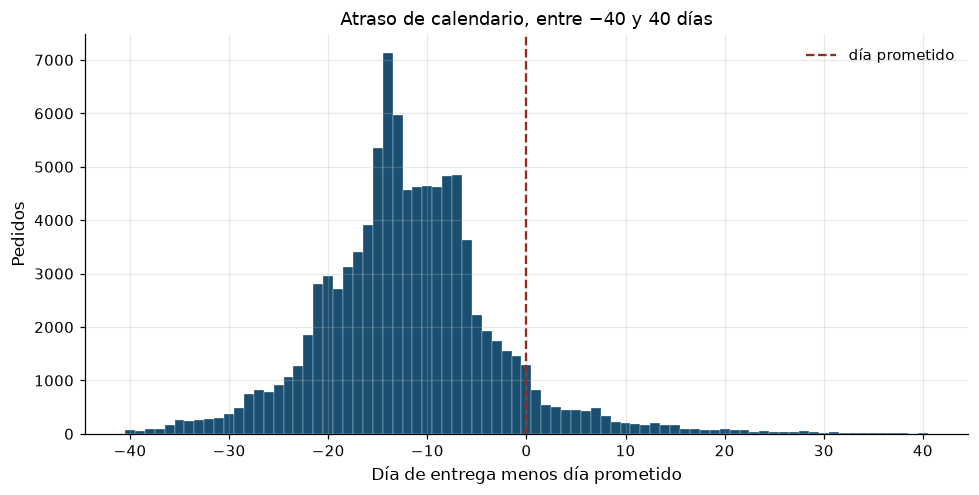

De **96,476** entregas fechadas, **91.9%** llegaron antes del día prometido, **1.3%** ese día y **6.8%** después. La mediana de todos los atrasos es **-12** días. Entre las **6,535** tardías, la mediana es **7** días, la media **10.6** y el percentil 90 es **22**. Fuera de la ventana del histograma quedan **532** pedidos a la izquierda y **194** a la derecha.

In [25]:
parte_antes = float(fechados["atraso_dias"].lt(0).mean())
parte_dia = float(fechados["atraso_dias"].eq(0).mean())
parte_tarde = float(fechados["tarde"].mean())
tarde = fechados.loc[fechados["tarde"]]
fuera_izq = int(fechados["atraso_dias"].lt(-40).sum())
fuera_der = int(fechados["atraso_dias"].gt(40).sum())

fig, ax = figura(
    "Atraso de calendario, entre −40 y 40 días",
    "Día de entrega menos día prometido",
    "Pedidos",
)
ax.hist(
    fechados.loc[fechados["atraso_dias"].between(-40, 40), "atraso_dias"],
    bins=np.arange(-40.5, 41.5, 1),
    color="#1b4f72",
    edgecolor="white",
    linewidth=0.2,
)
ax.axvline(0, color="#922b21", linestyle="--", label="día prometido")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

display(Markdown(
    f"De **{len(fechados):,}** entregas fechadas, **{parte_antes:.1%}** llegaron antes del día prometido, "
    f"**{parte_dia:.1%}** ese día y **{parte_tarde:.1%}** después. "
    f"La mediana de todos los atrasos es **{fechados['atraso_dias'].median():.0f}** días. "
    f"Entre las **{len(tarde):,}** tardías, la mediana es **{tarde['atraso_dias'].median():.0f}** días, "
    f"la media **{tarde['atraso_dias'].mean():.1f}** y el percentil 90 es **{tarde['atraso_dias'].quantile(0.9):.0f}**. "
    f"Fuera de la ventana del histograma quedan **{fuera_izq:,}** pedidos a la izquierda y **{fuera_der:,}** a la derecha."
))


#### ¿En qué tramo de la entrega se concentra el atraso?

La primera gráfica parte la espera en aprobación del pago, entrega al transportista y tránsito. Entra un pedido solo si esas tres fechas van en orden. El tramo largo está después de que el vendedor soltó el paquete. La mediana del tránsito en la tabla usa las filas en las que la compra precede al transportista y este al cliente.


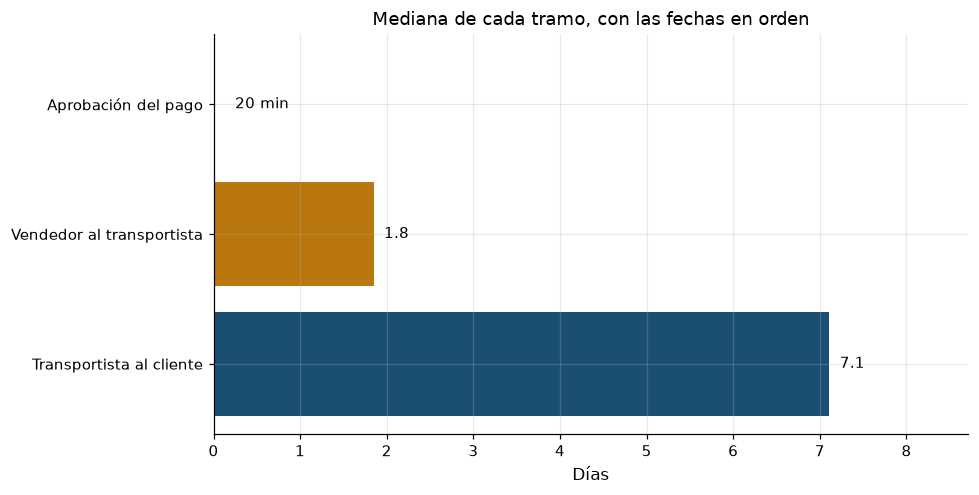

,pedidos,mediana_hasta_transportista,mediana_transito,mediana_espera,mediana_atraso
tarde,,,,,
En el día o antes,89755,2.15,6.95,9.82,-13.0
Tarde,6532,3.50,26.20,31.25,7.0


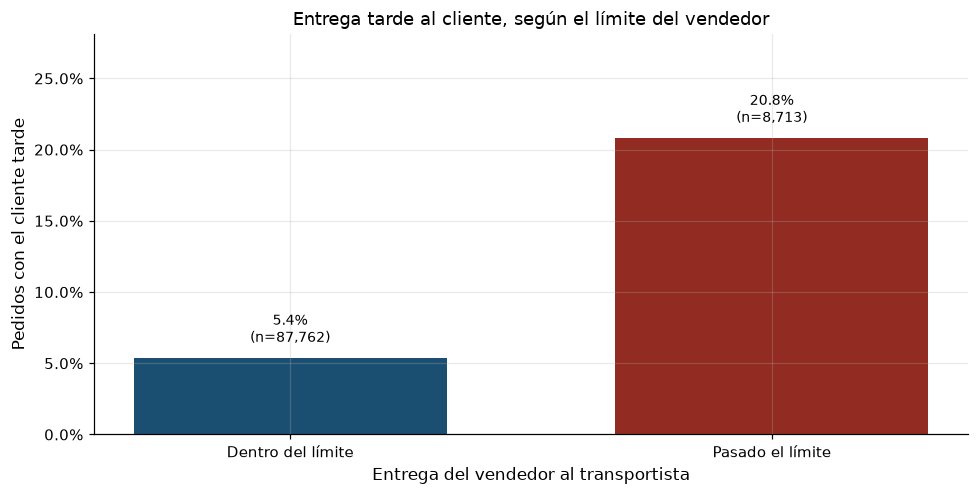

En **96,475** pedidos con límite y con entrega al transportista, el vendedor se pasa de ese límite en **9.0%**. Si lo cumplió, el cliente llega tarde el **5.4%** de las veces; si no lo cumplió, el **20.8%**. Entre los clientes que llegan tarde, el vendedor había cumplido el límite en **72%**. Las medianas de arriba dejan fuera **188** pedidos cuyo reloj no está en orden.

In [26]:
en_orden = fechados.loc[
    fechados["order_approved_at"].notna() & fechados["order_delivered_carrier_date"].notna()
].copy()
en_orden["tramo_aprobacion"] = (
    en_orden["order_approved_at"] - en_orden["order_purchase_timestamp"]
).dt.total_seconds() / 86400
en_orden["tramo_vendedor"] = (
    en_orden["order_delivered_carrier_date"] - en_orden["order_approved_at"]
).dt.total_seconds() / 86400
en_orden["tramo_transito"] = (
    en_orden["order_delivered_customer_date"] - en_orden["order_delivered_carrier_date"]
).dt.total_seconds() / 86400
en_orden = en_orden.loc[
    en_orden["tramo_aprobacion"].ge(0)
    & en_orden["tramo_vendedor"].ge(0)
    & en_orden["tramo_transito"].ge(0)
]
TRAMOS = ["tramo_aprobacion", "tramo_vendedor", "tramo_transito"]
NOMBRE_TRAMO = {
    "tramo_aprobacion": "Aprobación del pago",
    "tramo_vendedor": "Vendedor al transportista",
    "tramo_transito": "Transportista al cliente",
}
mediana_tramo = en_orden[TRAMOS].median().rename(index=NOMBRE_TRAMO).iloc[::-1]
fig, ax = figura("Mediana de cada tramo, con las fechas en orden", "Días", "")
barras = ax.barh(mediana_tramo.index, mediana_tramo, color=["#1b4f72", "#b9770e", "#0e6655"])
for barra, valor in zip(barras, mediana_tramo):
    if valor < 0.2:
        texto = f"{valor * 24 * 60:.0f} min"
        xpos = 0.25
    else:
        texto = f"{valor:.1f}"
        xpos = valor + 0.12
    ax.text(xpos, barra.get_y() + barra.get_height() / 2, texto, va="center", fontsize=10)
ax.set_xlim(0, mediana_tramo.max() + 1.6)
fig.tight_layout()
plt.show()

despacho = fechados[
    fechados["limite_despacho"].notna() & fechados["order_delivered_carrier_date"].notna()
].copy()
cronologico = despacho[
    despacho["order_delivered_carrier_date"].ge(despacho["order_purchase_timestamp"])
    & despacho["order_delivered_customer_date"].ge(despacho["order_delivered_carrier_date"])
].copy()
cronologico["transito_dias"] = (
    cronologico["order_delivered_customer_date"] - cronologico["order_delivered_carrier_date"]
).dt.total_seconds() / 86400
cronologico["hasta_transportista_dias"] = (
    cronologico["order_delivered_carrier_date"] - cronologico["order_purchase_timestamp"]
).dt.total_seconds() / 86400

resumen_tramo = cronologico.groupby("tarde").agg(
    pedidos=("order_id", "size"),
    mediana_hasta_transportista=("hasta_transportista_dias", "median"),
    mediana_transito=("transito_dias", "median"),
    mediana_espera=("espera_dias", "median"),
    mediana_atraso=("atraso_dias", "median"),
)
resumen_tramo.index = resumen_tramo.index.map({False: "En el día o antes", True: "Tarde"})
display(resumen_tramo.round(2))

tasa_vendedor = despacho.groupby("vendedor_tarde").agg(
    pedidos=("order_id", "size"),
    tasa_cliente_tarde=("tarde", "mean"),
)
tasa_vendedor.index = tasa_vendedor.index.map({False: "Dentro del límite", True: "Pasado el límite"})

fig, ax = figura(
    "Entrega tarde al cliente, según el límite del vendedor",
    "Entrega del vendedor al transportista",
    "Pedidos con el cliente tarde",
)
barras = ax.bar(
    tasa_vendedor.index.astype(str),
    tasa_vendedor["tasa_cliente_tarde"],
    color=["#1b4f72", "#922b21"],
    width=0.65,
)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_ylim(0, tasa_vendedor["tasa_cliente_tarde"].max() * 1.35)
for barra, (_, fila) in zip(barras, tasa_vendedor.iterrows()):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 0.008,
        f"{fila['tasa_cliente_tarde']:.1%}\n(n={int(fila['pedidos']):,})",
        ha="center",
        va="bottom",
        fontsize=9,
    )
fig.tight_layout()
plt.show()

parte_vendedor_tarde = float(despacho["vendedor_tarde"].mean())
vendedor_entre_clientes_tarde = float(despacho.loc[despacho["tarde"], "vendedor_tarde"].mean())
display(Markdown(
    f"En **{len(despacho):,}** pedidos con límite y con entrega al transportista, "
    f"el vendedor se pasa de ese límite en **{parte_vendedor_tarde:.1%}**. "
    f"Si lo cumplió, el cliente llega tarde el **{tasa_vendedor.loc['Dentro del límite', 'tasa_cliente_tarde']:.1%}** de las veces; "
    f"si no lo cumplió, el **{tasa_vendedor.loc['Pasado el límite', 'tasa_cliente_tarde']:.1%}**. "
    f"Entre los clientes que llegan tarde, el vendedor había cumplido el límite en **{1 - vendedor_entre_clientes_tarde:.0%}**. "
    f"Las medianas de arriba dejan fuera **{len(despacho) - len(cronologico):,}** pedidos cuyo reloj no está en orden."
))


#### ¿Cómo se reparte la nota según la entrega?

La nota va de 1 a 5. Las tres situaciones de abajo no se solapan. «Tarde» es un día posterior al prometido. «En el día o antes» incluye el día prometido.


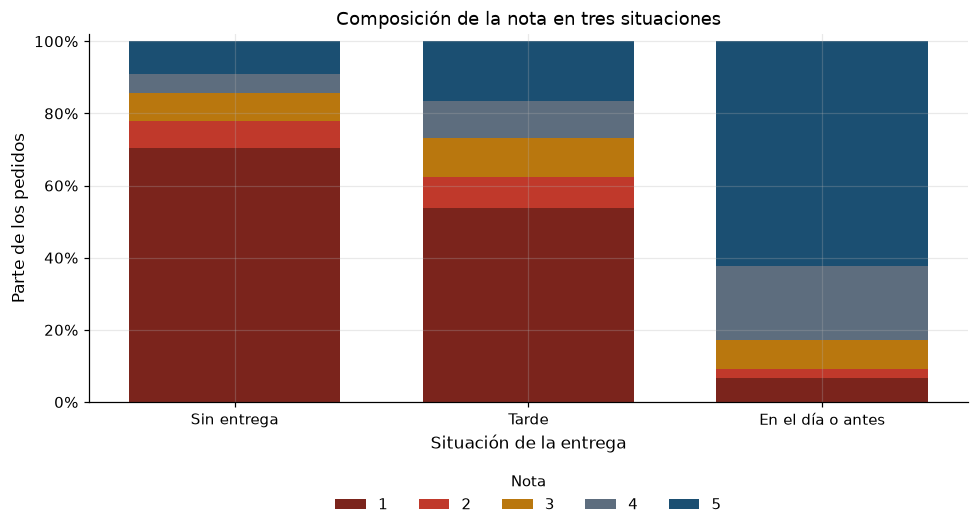

,pedidos,nota media,"notas 1 o 2, %","notas 5, %"
situación,,,,
Sin entrega,2835,1.75,77.9,9.0
Tarde,6382,2.27,62.3,16.6
En el día o antes,89448,4.29,9.3,62.3


Un pedido sin entrega promedia **1.75**. Uno tarde, **2.27**. Uno en el día prometido o antes, **4.29**. Las notas 1 y 2 son el **78%**, el **62%** y el **9%** de cada grupo.

El reloj llamaría tarde a las **1,280** entregas del día prometido. Su nota media es **4.04**, junto a las entregas anticipadas.

In [27]:
def distribucion(df):
    return df["nota"].value_counts(normalize=True).reindex([1, 2, 3, 4, 5]).fillna(0.0)


grupos_nota = [
    ("Sin entrega", sin_entrega),
    ("Tarde", con_nota.loc[con_nota["tarde"]]),
    ("En el día o antes", con_nota.loc[~con_nota["tarde"]]),
]
colores_nota = {1: "#7b241c", 2: "#c0392b", 3: "#b9770e", 4: "#5d6d7e", 5: "#1b4f72"}

fig, ax = figura(
    "Composición de la nota en tres situaciones",
    "Situación de la entrega",
    "Parte de los pedidos",
    alto=5.0,
)
fondo = np.zeros(len(grupos_nota))
posiciones = np.arange(len(grupos_nota))
for puntaje, color in colores_nota.items():
    alturas = [float(distribucion(df).loc[puntaje]) for _, df in grupos_nota]
    ax.bar(posiciones, alturas, bottom=fondo, color=color, width=0.72, label=str(puntaje))
    fondo = fondo + alturas
ax.set_xticks(posiciones)
ax.set_xticklabels([nombre for nombre, _ in grupos_nota])
ax.set_ylim(0, 1.02)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.legend(
    title="Nota", frameon=False, ncol=5,
    loc="upper center", bbox_to_anchor=(0.5, -0.16),
)
fig.tight_layout()
plt.show()

filas_grupos = []
for nombre, df in grupos_nota:
    filas_grupos.append({
        "situación": nombre,
        "pedidos": len(df),
        "nota_media": df["nota"].mean(),
        "nota_1_o_2": df["nota"].le(2).mean(),
        "nota_5": df["nota"].eq(5).mean(),
    })
tabla_grupos = pd.DataFrame(filas_grupos).set_index("situación")
display(tabla_grupos.assign(
    nota_media=lambda d: d["nota_media"].round(2),
    nota_1_o_2=lambda d: (d["nota_1_o_2"] * 100).round(1),
    nota_5=lambda d: (d["nota_5"] * 100).round(1),
).rename(columns={"nota_1_o_2": "notas 1 o 2, %", "nota_5": "notas 5, %", "nota_media": "nota media"}))

mismo_dia = con_nota.loc[con_nota["atraso_dias"].eq(0)]
display(Markdown(
    f"Un pedido sin entrega promedia **{tabla_grupos.loc['Sin entrega', 'nota_media']:.2f}**. "
    f"Uno tarde, **{tabla_grupos.loc['Tarde', 'nota_media']:.2f}**. "
    f"Uno en el día prometido o antes, **{tabla_grupos.loc['En el día o antes', 'nota_media']:.2f}**. "
    f"Las notas 1 y 2 son el **{tabla_grupos.loc['Sin entrega', 'nota_1_o_2']:.0%}**, "
    f"el **{tabla_grupos.loc['Tarde', 'nota_1_o_2']:.0%}** y el **{tabla_grupos.loc['En el día o antes', 'nota_1_o_2']:.0%}** de cada grupo.\n\n"
    f"El reloj llamaría tarde a las **{len(mismo_dia):,}** entregas del día prometido. "
    f"Su nota media es **{mismo_dia['nota'].mean():.2f}**, junto a las entregas anticipadas."
))


#### ¿La nota baja al pasar el día prometido?

La nota no cae de golpe en el primer día de adelanto. Cae al pasar el día prometido, y sigue más baja cuando el atraso ya se cuenta por semanas.


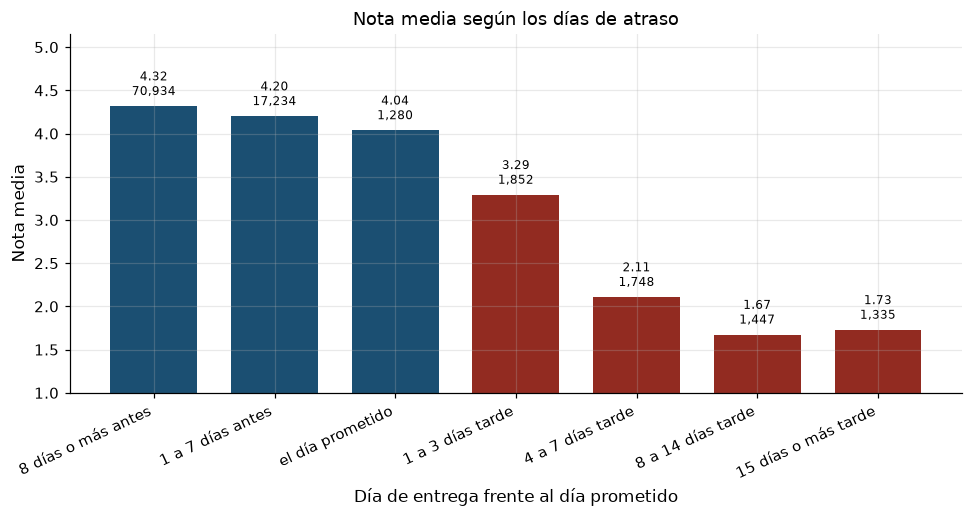

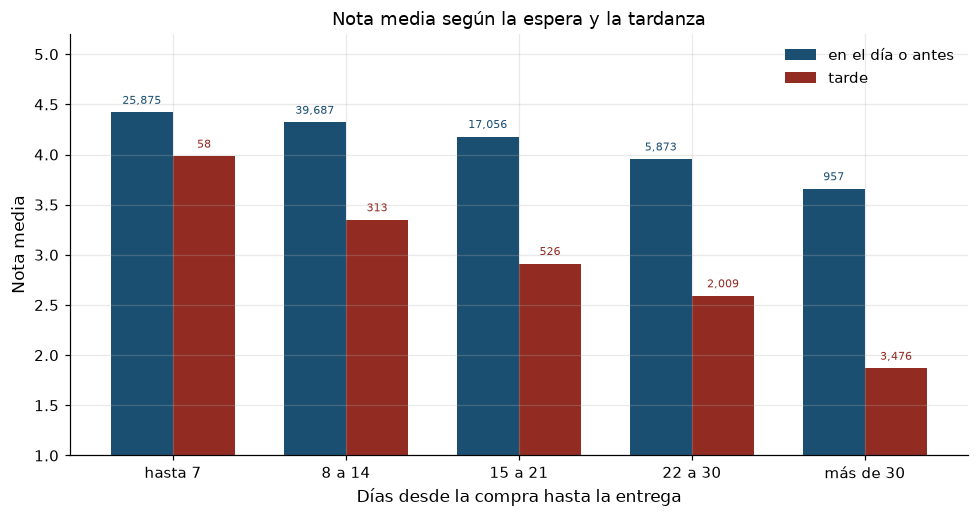

Ocho días o más de adelanto quedan en **4.32**. El día prometido, en **4.04**. Uno a tres días tarde, en **3.29**. De ocho días tarde en adelante, la media queda cerca de **1.67**.

Una espera de más de 30 días que cumple el día prometido promedia **3.66**. La misma espera, tarde, promedia **1.87**. La espera corta y a tiempo promedia **4.42**: esperar también mueve la nota. La barra tarde de la primera semana apoya en **58** pedidos. Una promesa de varias semanas casi no se vence en los primeros siete días.

In [28]:
por_tramo = con_nota.groupby("tramo_atraso", observed=True).agg(
    pedidos=("order_id", "size"),
    nota=("nota", "mean"),
)
por_tramo = por_tramo.reindex(ETIQ_ATRASO)

fig, ax = figura(
    "Nota media según los días de atraso",
    "Día de entrega frente al día prometido",
    "Nota media",
    alto=4.8,
)
colores_tramo = ["#1b4f72" if i < 3 else "#922b21" for i in range(len(por_tramo))]
barras = ax.bar(np.arange(len(por_tramo)), por_tramo["nota"], color=colores_tramo, width=0.72)
ax.set_xticks(np.arange(len(por_tramo)))
ax.set_xticklabels(por_tramo.index.astype(str), rotation=25, ha="right")
ax.set_ylim(1, 5.15)
for i, (_, fila) in enumerate(por_tramo.iterrows()):
    ax.text(i, fila["nota"] + 0.08, f"{fila['nota']:.2f}\n{int(fila['pedidos']):,}", ha="center", va="bottom", fontsize=8)
fig.tight_layout()
plt.show()

por_espera = con_nota.pivot_table(
    index="tramo_espera",
    columns="tarde",
    values="nota",
    aggfunc=["mean", "count"],
    observed=True,
).reindex(ETIQ_ESPERA)

fig, ax = figura(
    "Nota media según la espera y la tardanza",
    "Días desde la compra hasta la entrega",
    "Nota media",
    alto=4.8,
)
posiciones = np.arange(len(ETIQ_ESPERA))
ax.bar(posiciones - 0.18, por_espera[("mean", False)], width=0.36, color="#1b4f72", label="en el día o antes")
ax.bar(posiciones + 0.18, por_espera[("mean", True)], width=0.36, color="#922b21", label="tarde")
for i, tramo in enumerate(ETIQ_ESPERA):
    ax.text(i - 0.18, por_espera.loc[tramo, ("mean", False)] + 0.06, f"{int(por_espera.loc[tramo, ('count', False)]):,}", ha="center", va="bottom", fontsize=7, color="#1b4f72")
    ax.text(i + 0.18, por_espera.loc[tramo, ("mean", True)] + 0.06, f"{int(por_espera.loc[tramo, ('count', True)]):,}", ha="center", va="bottom", fontsize=7, color="#922b21")
ax.set_xticks(posiciones)
ax.set_xticklabels(ETIQ_ESPERA)
ax.set_ylim(1, 5.2)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

espera_larga_a_tiempo = float(por_espera.loc["más de 30", ("mean", False)])
espera_larga_tarde = float(por_espera.loc["más de 30", ("mean", True)])
espera_corta_a_tiempo = float(por_espera.loc["hasta 7", ("mean", False)])
display(Markdown(
    f"Ocho días o más de adelanto quedan en **{por_tramo.loc['8 días o más antes', 'nota']:.2f}**. "
    f"El día prometido, en **{por_tramo.loc['el día prometido', 'nota']:.2f}**. "
    f"Uno a tres días tarde, en **{por_tramo.loc['1 a 3 días tarde', 'nota']:.2f}**. "
    f"De ocho días tarde en adelante, la media queda cerca de **{por_tramo.loc['8 a 14 días tarde', 'nota']:.2f}**.\n\n"
    f"Una espera de más de 30 días que cumple el día prometido promedia **{espera_larga_a_tiempo:.2f}**. "
    f"La misma espera, tarde, promedia **{espera_larga_tarde:.2f}**. "
    f"La espera corta y a tiempo promedia **{espera_corta_a_tiempo:.2f}**: esperar también mueve la nota. "
    f"La barra tarde de la primera semana apoya en **{int(por_espera.loc['hasta 7', ('count', True)])}** pedidos. "
    "Una promesa de varias semanas casi no se vence en los primeros siete días."
))


#### ¿La encuesta llega mientras el paquete tarde sigue en camino?

`review_creation_date` es el día en que se envía la encuesta. `review_answer_timestamp` es el momento en que el cliente responde. En un pedido a tiempo, esa encuesta cae junto a la entrega. En un pedido tarde, cae junto al día prometido, antes de que el paquete llegue. La respuesta anterior a la entrega es la forma que toma el atraso en la nota, no un segundo fenómeno suelto.


,"encuesta menos entrega, días","encuesta menos promesa, días",respondió antes de la entrega
En el día o antes,1.0,-12.0,0.003
Tarde,-4.0,2.0,0.702


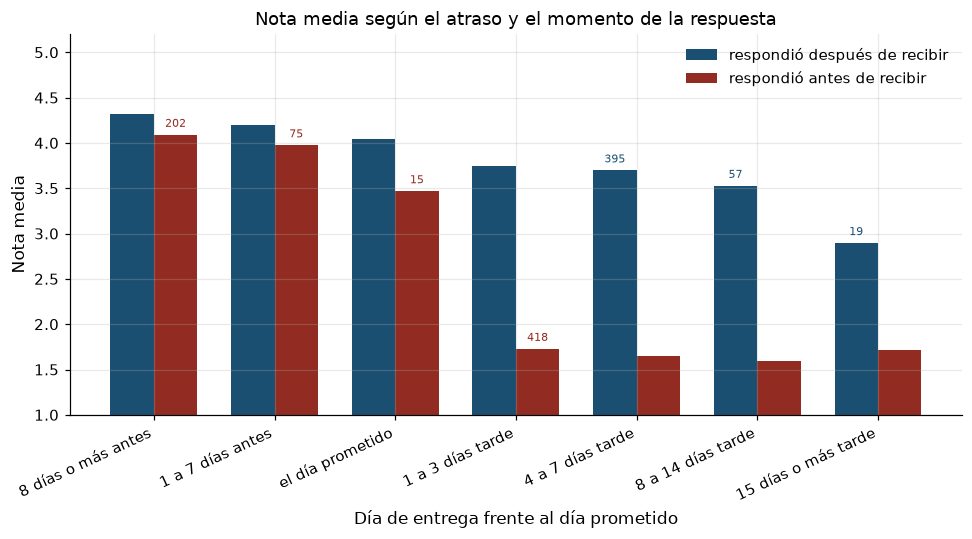

,"n, después","nota, después","n, antes","nota, antes"
tramo_atraso,,,,
8 días o más antes,70732,4.32,202,4.09
1 a 7 días antes,17159,4.20,75,3.97
el día prometido,1265,4.04,15,3.47
1 a 3 días tarde,1434,3.75,418,1.73
4 a 7 días tarde,395,3.70,1353,1.64
8 a 14 días tarde,57,3.53,1390,1.60
15 días o más tarde,19,2.89,1316,1.71


En un pedido a tiempo, la mediana de la encuesta queda **1 día después** de la entrega y **12 días antes** de la promesa. En un pedido tarde, queda **4 días antes** de la entrega y **2 días después** de la promesa. El número sobre una barra es la cantidad de pedidos cuando esa barra tiene menos de 500.

Responde antes de recibir el paquete el **70%** de los pedidos tarde y el **0.3%** de los que van en el día o antes. Esas respuestas tempranas, en el grupo tarde, promedian **1.66**. Las que llegan después del paquete tarde promedian **3.72**. En los atrasos de ocho días o más, la columna «después» queda en unas decenas de pedidos: casi todo el grupo ya contestó antes de recibir.

In [29]:
a_tiempo = con_nota.loc[~con_nota["tarde"]]
tarde_nota = con_nota.loc[con_nota["tarde"]]
mediana_encuesta = pd.DataFrame({
    "encuesta menos entrega, días": [
        a_tiempo["encuesta_menos_entrega"].median(),
        tarde_nota["encuesta_menos_entrega"].median(),
    ],
    "encuesta menos promesa, días": [
        a_tiempo["encuesta_menos_promesa"].median(),
        tarde_nota["encuesta_menos_promesa"].median(),
    ],
    "respondió antes de la entrega": [
        a_tiempo["respondio_antes"].mean(),
        tarde_nota["respondio_antes"].mean(),
    ],
}, index=["En el día o antes", "Tarde"])
display(mediana_encuesta.round(3))

por_respuesta = con_nota.groupby(["tramo_atraso", "respondio_antes"], observed=True).agg(
    pedidos=("order_id", "size"),
    nota=("nota", "mean"),
).reset_index()

fig, ax = figura(
    "Nota media según el atraso y el momento de la respuesta",
    "Día de entrega frente al día prometido",
    "Nota media",
    alto=5.0,
)
posiciones = np.arange(len(ETIQ_ATRASO))
for desplazamiento, valor, color, leyenda in (
    (-0.18, False, "#1b4f72", "respondió después de recibir"),
    (0.18, True, "#922b21", "respondió antes de recibir"),
):
    sub = por_respuesta.loc[por_respuesta["respondio_antes"].eq(valor)].set_index("tramo_atraso").reindex(ETIQ_ATRASO)
    ax.bar(posiciones + desplazamiento, sub["nota"], width=0.36, color=color, label=leyenda)
    for i, (cantidad, nota) in enumerate(zip(sub["pedidos"], sub["nota"])):
        if pd.notna(cantidad) and cantidad < 500 and pd.notna(nota):
            ax.text(i + desplazamiento, nota + 0.06, f"{int(cantidad)}", ha="center", va="bottom", fontsize=7, color=color)
ax.set_xticks(posiciones)
ax.set_xticklabels(ETIQ_ATRASO, rotation=25, ha="right")
ax.set_ylim(1, 5.2)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

tabla_respuesta = pd.DataFrame({
    "n, después": por_respuesta.loc[~por_respuesta["respondio_antes"].astype(bool)].set_index("tramo_atraso").reindex(ETIQ_ATRASO)["pedidos"],
    "nota, después": por_respuesta.loc[~por_respuesta["respondio_antes"].astype(bool)].set_index("tramo_atraso").reindex(ETIQ_ATRASO)["nota"],
    "n, antes": por_respuesta.loc[por_respuesta["respondio_antes"].astype(bool)].set_index("tramo_atraso").reindex(ETIQ_ATRASO)["pedidos"],
    "nota, antes": por_respuesta.loc[por_respuesta["respondio_antes"].astype(bool)].set_index("tramo_atraso").reindex(ETIQ_ATRASO)["nota"],
})
display(tabla_respuesta.assign(**{
    "nota, después": tabla_respuesta["nota, después"].round(2),
    "nota, antes": tabla_respuesta["nota, antes"].round(2),
}))

def en_dias(valor):
    entero = int(abs(valor))
    return f"{entero} día" if entero == 1 else f"{entero} días"


nota_tarde_antes = float(tarde_nota.loc[tarde_nota["respondio_antes"], "nota"].mean())
nota_tarde_despues = float(tarde_nota.loc[~tarde_nota["respondio_antes"], "nota"].mean())
display(Markdown(
    f"En un pedido a tiempo, la mediana de la encuesta queda **{en_dias(a_tiempo['encuesta_menos_entrega'].median())} después** "
    f"de la entrega y **{en_dias(a_tiempo['encuesta_menos_promesa'].median())} antes** de la promesa. "
    f"En un pedido tarde, queda **{en_dias(tarde_nota['encuesta_menos_entrega'].median())} antes** de la entrega "
    f"y **{en_dias(tarde_nota['encuesta_menos_promesa'].median())} después** de la promesa. "
    "El número sobre una barra es la cantidad de pedidos cuando esa barra tiene menos de 500.\n\n"
    f"Responde antes de recibir el paquete el **{tarde_nota['respondio_antes'].mean():.0%}** de los pedidos tarde "
    f"y el **{a_tiempo['respondio_antes'].mean():.1%}** de los que van en el día o antes. "
    f"Esas respuestas tempranas, en el grupo tarde, promedian **{nota_tarde_antes:.2f}**. "
    f"Las que llegan después del paquete tarde promedian **{nota_tarde_despues:.2f}**. "
    "En los atrasos de ocho días o más, la columna «después» queda en unas decenas de pedidos: "
    "casi todo el grupo ya contestó antes de recibir."
))


#### ¿Qué más baja la nota, y qué casi no la mueve?

Las brechas de abajo son diferencias de nota media. El flete y el precio se miran dentro de São Paulo, con un solo artículo y con la entrega en el día prometido o antes, para no mezclarlos con la distancia ni con el atraso. La categoría usa el nombre en inglés de la traducción y pide al menos 500 pedidos a tiempo. El diccionario es una criba de palabras, no una lectura del comentario.


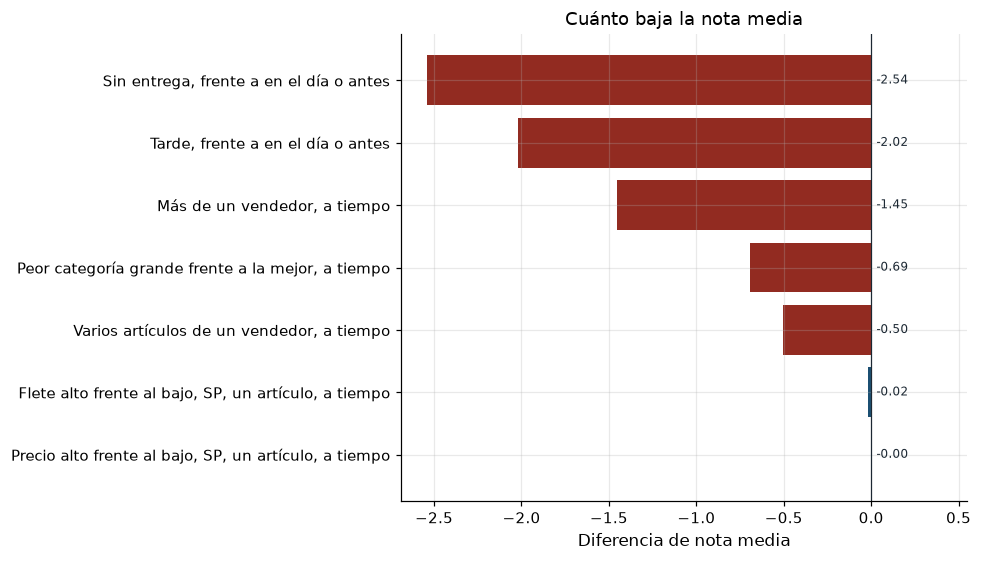

,correlación con la nota
"Espera, días",-0.334
"Atraso de calendario, días",-0.266
"Atraso, Spearman",-0.176
Artículos del pedido,-0.124
"Flete, BRL",-0.089
"Precio, BRL",-0.035


Más de un vendedor, con la entrega a tiempo, promedia **2.86** en **1,249** pedidos, frente a **4.31** con un solo vendedor. Su tasa de atraso es **1.0%**: la brecha no es el día prometido. La reseña es una sola para todo el pedido y no dice cuál vendedor falló.

Varios artículos de un mismo vendedor, a tiempo, promedian **3.85** (7,788 pedidos) frente a **4.36** de un solo artículo.

Entre las categorías con al menos 500 entregas a tiempo, **office furniture** promedia **3.77** y **luggage accessories** promedia **4.46**. En São Paulo, un artículo y a tiempo, el cuartil de flete más alto difiere del más bajo en **-0.02** puntos de nota, y el de precio en **-0.00**. Pearson del atraso con la nota es **-0.27** y Spearman **-0.18**. La correlación es más chica que el salto del gráfico anterior: la mayoría de los pedidos llega antes y ya tiene una nota alta.

In [30]:
sp = con_nota.loc[
    ~con_nota["tarde"]
    & con_nota["customer_state"].eq("SP")
    & con_nota["n_items"].eq(1)
    & con_nota["flete"].notna()
    & con_nota["precio"].notna()
].copy()
cuartil_flete = sp.groupby(pd.qcut(sp["flete"], 4), observed=True)["nota"].mean()
cuartil_precio = sp.groupby(pd.qcut(sp["precio"], 4), observed=True)["nota"].mean()
brecha_flete = float(cuartil_flete.iloc[-1] - cuartil_flete.iloc[0])
brecha_precio = float(cuartil_precio.iloc[-1] - cuartil_precio.iloc[0])

un_vendedor_un_item = con_nota.loc[~con_nota["tarde"] & con_nota["n_items"].eq(1) & con_nota["n_vendedores"].eq(1), "nota"]
varios_items = con_nota.loc[~con_nota["tarde"] & con_nota["n_items"].gt(1) & con_nota["n_vendedores"].eq(1), "nota"]
varios_vendedores = con_nota.loc[~con_nota["tarde"] & con_nota["n_vendedores"].gt(1), "nota"]
un_vendedor = con_nota.loc[~con_nota["tarde"] & con_nota["n_vendedores"].eq(1), "nota"]

categorias = (
    con_nota.loc[~con_nota["tarde"]]
    .groupby("categoria", observed=True)["nota"]
    .agg(["count", "mean"])
)
categorias = categorias.loc[categorias["count"].ge(500)].sort_values("mean")
peor_categoria = str(categorias.index[0]).replace("_", " ")
mejor_categoria = str(categorias.index[-1]).replace("_", " ")
brecha_categoria = float(categorias["mean"].iloc[0] - categorias["mean"].iloc[-1])

brechas = pd.Series({
    "Sin entrega, frente a en el día o antes": sin_entrega["nota"].mean() - a_tiempo["nota"].mean(),
    "Tarde, frente a en el día o antes": tarde_nota["nota"].mean() - a_tiempo["nota"].mean(),
    "Más de un vendedor, a tiempo": varios_vendedores.mean() - un_vendedor.mean(),
    "Varios artículos de un vendedor, a tiempo": varios_items.mean() - un_vendedor_un_item.mean(),
    "Peor categoría grande frente a la mejor, a tiempo": brecha_categoria,
    "Flete alto frente al bajo, SP, un artículo, a tiempo": brecha_flete,
    "Precio alto frente al bajo, SP, un artículo, a tiempo": brecha_precio,
}).sort_values()

fig, ax = figura(
    "Cuánto baja la nota media",
    "Diferencia de nota media",
    "",
    alto=5.2,
)
ordenado = brechas.sort_values(ascending=False)
colores = ["#922b21" if valor < -0.4 else "#1b4f72" for valor in ordenado]
ax.barh(ordenado.index.astype(str), ordenado.to_numpy(), color=colores)
for y, valor in enumerate(ordenado.to_numpy()):
    ax.text(0.03, y, f"{valor:+.2f}", va="center", ha="left", fontsize=8, color="#1c2833")
ax.axvline(0, color="#1c2833", linewidth=0.8)
ax.set_xlim(ordenado.min() - 0.15, 0.55)
fig.tight_layout()
plt.show()

correlaciones = pd.Series({
    "Espera, días": con_nota["espera_dias"].corr(con_nota["nota"]),
    "Atraso de calendario, días": con_nota["atraso_dias"].corr(con_nota["nota"]),
    "Atraso, Spearman": con_nota["atraso_dias"].corr(con_nota["nota"], method="spearman"),
    "Artículos del pedido": con_nota["n_items"].corr(con_nota["nota"]),
    "Flete, BRL": con_nota["flete"].corr(con_nota["nota"]),
    "Precio, BRL": con_nota["precio"].corr(con_nota["nota"]),
}, name="correlación con la nota")
display(correlaciones.round(3).to_frame())

display(Markdown(
    f"Más de un vendedor, con la entrega a tiempo, promedia **{varios_vendedores.mean():.2f}** "
    f"en **{len(varios_vendedores):,}** pedidos, frente a **{un_vendedor.mean():.2f}** con un solo vendedor. "
    f"Su tasa de atraso es **{con_nota.loc[con_nota['n_vendedores'].gt(1), 'tarde'].mean():.1%}**: "
    "la brecha no es el día prometido. La reseña es una sola para todo el pedido y no dice cuál vendedor falló.\n\n"
    f"Varios artículos de un mismo vendedor, a tiempo, promedian **{varios_items.mean():.2f}** "
    f"({len(varios_items):,} pedidos) frente a **{un_vendedor_un_item.mean():.2f}** de un solo artículo.\n\n"
    f"Entre las categorías con al menos 500 entregas a tiempo, "
    f"**{peor_categoria}** promedia **{categorias['mean'].iloc[0]:.2f}** y **{mejor_categoria}** promedia **{categorias['mean'].iloc[-1]:.2f}**. "
    f"En São Paulo, un artículo y a tiempo, el cuartil de flete más alto difiere del más bajo en **{brecha_flete:+.2f}** puntos de nota, "
    f"y el de precio en **{brecha_precio:+.2f}**. "
    f"Pearson del atraso con la nota es **{correlaciones.loc['Atraso de calendario, días']:.2f}** "
    f"y Spearman **{correlaciones.loc['Atraso, Spearman']:.2f}**. "
    "La correlación es más chica que el salto del gráfico anterior: la mayoría de los pedidos llega antes y ya tiene una nota alta."
))


#### ¿El texto de una nota baja habla del plazo o del producto?

El diccionario es una criba de palabras, no una lectura del comentario. Compara, entre grupos de nota, cuántos textos mencionan el atraso y cuántos el producto.


In [31]:
PAT_ATRASO = (
    r"atras|demor|nao chegou|nao recebi|nao entreg|"
    r"ainda nao|nao veio|nunca chegou|fora do prazo|depois do prazo"
)
PAT_PRODUCTO = (
    r"defeito|quebr|errad|faltand|faltou|incomplet|avaria|danific|"
    r"nao funciona|veio outro|produto errado|diferente do"
)


def sin_acentos(serie):
    return (
        serie.fillna("")
        .str.lower()
        .str.normalize("NFKD")
        .str.encode("ascii", "ignore")
        .str.decode("ascii")
    )


def marcar_texto(df):
    texto = sin_acentos(df["mensajes"]) + " " + sin_acentos(df["titulos"])
    salida = df.copy()
    salida["menciona_atraso"] = texto.str.contains(PAT_ATRASO, regex=True)
    salida["menciona_producto"] = texto.str.contains(PAT_PRODUCTO, regex=True)
    return salida


marcados = marcar_texto(con_nota)
sin_marcado = marcar_texto(sin_entrega)
baja_tarde = marcados.loc[marcados["tarde"] & marcados["nota"].le(2)]
baja_a_tiempo = marcados.loc[~marcados["tarde"] & marcados["nota"].le(2)]
baja_sin = sin_marcado.loc[sin_marcado["nota"].le(2)]
nota_cinco = marcados.loc[marcados["nota"].eq(5)]

filas_texto = []
for nombre, df in (
    ("Tarde y nota 1 o 2", baja_tarde),
    ("A tiempo y nota 1 o 2", baja_a_tiempo),
    ("Sin entrega y nota 1 o 2", baja_sin),
    ("Nota 5, con fecha", nota_cinco),
):
    filas_texto.append({
        "grupo": nombre,
        "pedidos": len(df),
        "con texto": df["tiene_texto"].mean(),
        "menciona el atraso": df["menciona_atraso"].mean(),
        "menciona el producto": df["menciona_producto"].mean(),
    })
tabla_texto = pd.DataFrame(filas_texto).set_index("grupo")
display(tabla_texto.assign(**{
    "con texto": (tabla_texto["con texto"] * 100).round(1),
    "menciona el atraso": (tabla_texto["menciona el atraso"] * 100).round(1),
    "menciona el producto": (tabla_texto["menciona el producto"] * 100).round(1),
}))


def ejemplo(df, columna):
    textos = (
        df.loc[df[columna], "mensajes"]
        .dropna()
        .astype(str)
        .map(lambda texto: " ".join(texto.split()))
    )
    textos = textos[textos.str.len().between(40, 160) & ~textos.str.contains("[äÃÂ�]", regex=True)]
    if textos.empty:
        return ""
    return textos.iloc[0]


display(Markdown(
    "Entre las notas 1 y 2 de un pedido tarde, el texto habla del plazo con más frecuencia que del producto. "
    "Entre las notas 1 y 2 de un pedido a tiempo, la relación se invierte. "
    f"En las notas 5 el diccionario de atraso se activa en el **{nota_cinco['menciona_atraso'].mean():.1%}**: "
    "esa cifra es una cota del ruido, porque una nota 5 también puede mencionar una demora de otro pedido "
    "o agradecer que llegó pronto.\n\n"
    f"Ejemplo tarde: «{ejemplo(baja_tarde, 'menciona_atraso')}»\n\n"
    f"Ejemplo a tiempo: «{ejemplo(baja_a_tiempo, 'menciona_producto')}»\n\n"
    "Más de la mitad de las reseñas no trae mensaje. La ausencia de la palabra no es la ausencia de la queja."
))

bajas = pd.concat([
    con_nota.loc[con_nota["nota"].le(2), ["order_id", "tarde"]],
    sin_entrega.loc[sin_entrega["nota"].le(2), ["order_id"]].assign(tarde=pd.NA),
], ignore_index=True)
bajas["grupo_baja"] = "a tiempo"
bajas.loc[bajas["tarde"].isna(), "grupo_baja"] = "sin entrega"
bajas.loc[bajas["tarde"].eq(True), "grupo_baja"] = "tarde"
parte_bajas = bajas["grupo_baja"].value_counts(normalize=True)
display(Markdown(
    f"De **{len(bajas):,}** notas 1 o 2 en los tres grupos, "
    f"**{parte_bajas.get('a tiempo', 0):.0%}** son entregas en el día o antes, "
    f"**{parte_bajas.get('tarde', 0):.0%}** son tardías y "
    f"**{parte_bajas.get('sin entrega', 0):.0%}** no tienen entrega. "
    "El atraso baja la nota con fuerza y, aun así, la mayoría de las notas bajas pertenece a pedidos que llegaron a tiempo: "
    "esos pedidos son casi todos."
))


,pedidos,con texto,menciona el atraso,menciona el producto
grupo,,,,
Tarde y nota 1 o 2,3979,69.8,42.5,1.6
A tiempo y nota 1 o 2,8287,79.0,15.9,18.9
Sin entrega y nota 1 o 2,2209,72.9,35.8,2.3
"Nota 5, con fecha",56761,38.1,0.8,0.4


Entre las notas 1 y 2 de un pedido tarde, el texto habla del plazo con más frecuencia que del producto. Entre las notas 1 y 2 de un pedido a tiempo, la relación se invierte. En las notas 5 el diccionario de atraso se activa en el **0.8%**: esa cifra es una cota del ruido, porque una nota 5 también puede mencionar una demora de otro pedido o agradecer que llegó pronto.

Ejemplo tarde: «Demora muito entregar. Já passou o prazo e ainda não recebi minha encomenda.»

Ejemplo a tiempo: «A cuba veio quebrada. Como efetuo barroca?»

Más de la mitad de las reseñas no trae mensaje. La ausencia de la palabra no es la ausencia de la queja.

De **14,475** notas 1 o 2 en los tres grupos, **57%** son entregas en el día o antes, **27%** son tardías y **15%** no tienen entrega. El atraso baja la nota con fuerza y, aun así, la mayoría de las notas bajas pertenece a pedidos que llegaron a tiempo: esos pedidos son casi todos.

#### ¿Dónde sube el atraso, baja la nota?

La serie mensual usa los pedidos fechados y con nota, y deja fuera los meses con menos de 500. El eje de la nota no empieza en cero: muestra el recorrido de las medias mensuales. El estado pide al menos 400 pedidos. El tamaño del punto sigue la cantidad de pedidos.


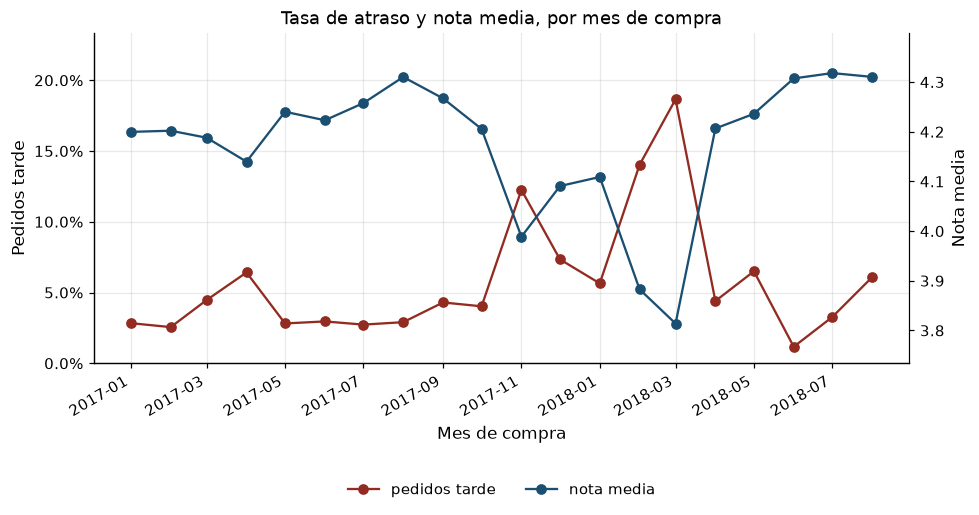

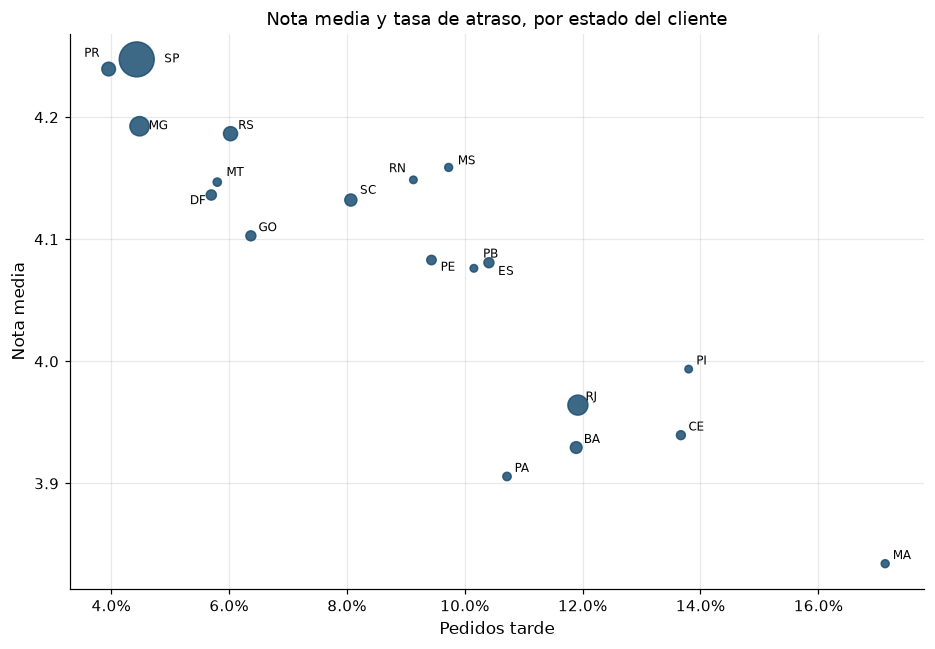

El mes con más atrasos es **2018-03** (**18.7%**, nota **3.81**). El de menos es **2018-06** (**1.2%**, nota **4.31**).

El día con más compras del extracto es el **24 de noviembre de 2017**. Del 23 al 26 de noviembre de 2017 la tardanza es **17.7%** (2,265 pedidos) y en el resto de ese mes es **9.8%**. La semana de compra con más atrasos, entre las de al menos 400 pedidos fechados, es la de **2018-02-26/2018-03-04** (**26.0%**, nota **3.58**).

En los **19** estados con al menos 400 pedidos, la correlación entre la tasa de atraso y la nota media es **-0.90**. **MA** tiene la tasa más alta (**17.1%**, nota **3.83**, espera mediana **19.1** días). **SP** está en **4.4%** de atrasos y nota **4.25**, con una espera mediana de **7.2** días. **RJ** espera **12.0** días, menos que varios estados del Norte y del Nordeste, y aun así su tardanza es **11.9%**.

In [32]:
por_mes = con_nota.groupby(con_nota["order_purchase_timestamp"].dt.to_period("M")).agg(
    pedidos=("order_id", "size"),
    tasa=("tarde", "mean"),
    nota=("nota", "mean"),
)
por_mes = por_mes.loc[por_mes["pedidos"].ge(500)].copy()
por_mes["fecha"] = por_mes.index.to_timestamp()

titulo_mes = "Tasa de atraso y nota media, por mes de compra"
FIGURAS.append(titulo_mes)
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.set_title(titulo_mes)
ax.plot(por_mes["fecha"], por_mes["tasa"], color="#922b21", marker="o", label="pedidos tarde")
ax.set_ylabel("Pedidos tarde")
ax.set_xlabel("Mes de compra")
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_ylim(0, max(0.22, float(por_mes["tasa"].max()) * 1.25))
ax2 = ax.twinx()
ax2.plot(por_mes["fecha"], por_mes["nota"], color="#1b4f72", marker="o", label="nota media")
ax2.set_ylabel("Nota media")
ax2.set_ylim(float(por_mes["nota"].min()) - 0.08, float(por_mes["nota"].max()) + 0.08)
ax2.grid(False)
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(True)
lineas_1, etiquetas_1 = ax.get_legend_handles_labels()
lineas_2, etiquetas_2 = ax2.get_legend_handles_labels()
ax.legend(
    lineas_1 + lineas_2,
    etiquetas_1 + etiquetas_2,
    frameon=False,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.32),
    ncol=2,
)
fig.autofmt_xdate()
fig.tight_layout()
fig.subplots_adjust(bottom=0.30)
plt.show()

noviembre = con_nota.loc[
    con_nota["order_purchase_timestamp"].between("2017-11-01", "2017-11-30 23:59:59")
]
puente = noviembre["order_purchase_timestamp"].between("2017-11-23", "2017-11-26 23:59:59")
dia_pico = pedidos["order_purchase_timestamp"].dt.normalize().value_counts().idxmax()
meses_es = ["enero", "febrero", "marzo", "abril", "mayo", "junio", "julio", "agosto", "septiembre", "octubre", "noviembre", "diciembre"]
dia_pico_texto = f"{dia_pico.day} de {meses_es[dia_pico.month - 1]} de {dia_pico.year}"
por_semana = con_nota.groupby(con_nota["order_purchase_timestamp"].dt.to_period("W-SUN")).agg(
    pedidos=("order_id", "size"),
    tasa=("tarde", "mean"),
    nota=("nota", "mean"),
)
por_semana = por_semana.loc[por_semana["pedidos"].ge(400)]
peor_semana = por_semana["tasa"].idxmax()

por_estado = con_nota.groupby("customer_state").agg(
    pedidos=("order_id", "size"),
    tasa=("tarde", "mean"),
    nota=("nota", "mean"),
    espera=("espera_dias", "median"),
)
por_estado = por_estado.loc[por_estado["pedidos"].ge(400)].copy()
correlacion_estado = float(por_estado["tasa"].corr(por_estado["nota"]))

fig, ax = figura(
    "Nota media y tasa de atraso, por estado del cliente",
    "Pedidos tarde",
    "Nota media",
    ancho=8.6,
    alto=6.0,
)
ax.scatter(
    por_estado["tasa"],
    por_estado["nota"],
    s=18 + por_estado["pedidos"] / 80,
    color="#1b4f72",
    alpha=0.85,
    zorder=3,
)
desplazamiento = {
    "SP": (18, -2), "PR": (-16, 8), "MG": (6, -2),
    "PB": (6, 7), "ES": (6, -8), "RN": (-16, 5), "MS": (6, 2),
    "DF": (-14, -6), "MT": (6, 4), "PE": (6, -7), "SC": (6, 4),
}
for estado, fila in por_estado.iterrows():
    ax.annotate(
        estado,
        (fila["tasa"], fila["nota"]),
        textcoords="offset points",
        xytext=desplazamiento.get(estado, (5, 3)),
        fontsize=8,
    )
ax.xaxis.set_major_formatter(PercentFormatter(1))
fig.tight_layout()
plt.show()

display(Markdown(
    f"El mes con más atrasos es **{por_mes['tasa'].idxmax()}** (**{por_mes['tasa'].max():.1%}**, nota **{por_mes.loc[por_mes['tasa'].idxmax(), 'nota']:.2f}**). "
    f"El de menos es **{por_mes['tasa'].idxmin()}** (**{por_mes['tasa'].min():.1%}**, nota **{por_mes.loc[por_mes['tasa'].idxmin(), 'nota']:.2f}**).\n\n"
    f"El día con más compras del extracto es el **{dia_pico_texto}**. "
    f"Del 23 al 26 de noviembre de 2017 la tardanza es **{noviembre.loc[puente, 'tarde'].mean():.1%}** "
    f"({int(puente.sum()):,} pedidos) y en el resto de ese mes es **{noviembre.loc[~puente, 'tarde'].mean():.1%}**. "
    f"La semana de compra con más atrasos, entre las de al menos 400 pedidos fechados, es la de **{peor_semana}** "
    f"(**{por_semana.loc[peor_semana, 'tasa']:.1%}**, nota **{por_semana.loc[peor_semana, 'nota']:.2f}**).\n\n"
    f"En los **{len(por_estado)}** estados con al menos 400 pedidos, la correlación entre la tasa de atraso y la nota media es **{correlacion_estado:.2f}**. "
    f"**{por_estado['tasa'].idxmax()}** tiene la tasa más alta (**{por_estado['tasa'].max():.1%}**, nota **{por_estado.loc[por_estado['tasa'].idxmax(), 'nota']:.2f}**, "
    f"espera mediana **{por_estado.loc[por_estado['tasa'].idxmax(), 'espera']:.1f}** días). "
    f"**SP** está en **{por_estado.loc['SP', 'tasa']:.1%}** de atrasos y nota **{por_estado.loc['SP', 'nota']:.2f}**, "
    f"con una espera mediana de **{por_estado.loc['SP', 'espera']:.1f}** días. "
    f"**RJ** espera **{por_estado.loc['RJ', 'espera']:.1f}** días, menos que varios estados del Norte y del Nordeste, "
    f"y aun así su tardanza es **{por_estado.loc['RJ', 'tasa']:.1%}**."
))


### Precio, flete y vendedores (`Proyecto_JM.ipynb`)

Las gráficas de esta subsección usan fondo oscuro. El estilo no queda activo al salir de cada celda.

**Preguntas:**

1. ¿Cómo se distribuyen el precio y el costo de envío de los artículos? ¿Son simétricos o hay muchos artículos baratos y pocos muy caros?
2. ¿Cuántos artículos vende un vendedor típico? ¿Las ventas se reparten entre muchos vendedores o se concentran en pocos?
3. ¿Cambian el precio y el costo de envío promedio según el estado del vendedor?
4. ¿Cuál es el precio promedio por artículo y por pedido, y cómo varía según el estado del vendedor?

**¿Los datos son adecuados para dicho análisis?**

- `order_items` tiene, a nivel de cada artículo, las dos variables numéricas centrales (`price` y `freight_value`) y el vendedor que lo vendió, lo que permite calcular medidas de tendencia central, dispersión y posición.
- `sellers` aporta la dimensión geográfica (estado y ciudad), que permite **comparar grupos o segmentos** de vendedores.
- La llave `seller_id` une ambas tablas sin pérdida de información (lo verificamos al revisar las llaves).
- Son datos reales de operación con un volumen grande (más de 100 mil artículos), por lo que los resultados son representativos de la actividad del marketplace en el periodo 2016–2018.

**¿Hay limitaciones con la información?** Sí, porque los datos solo cubren un periodo y solo a los vendedores de Olist.


#### Pregunta 1. ¿Cómo se distribuyen el precio y el costo de envío de los artículos? ¿Son simétricos o hay muchos artículos baratos y pocos muy caros?


In [33]:
vars_num = ["price", "freight_value"]
datos = items_sellers[vars_num]

resumen = datos.describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).T
resumen["moda"] = datos.mode().iloc[0]
resumen["rango"] = resumen["max"] - resumen["min"]
resumen["IQR"] = resumen["75%"] - resumen["25%"]
resumen["coef_variacion"] = resumen["std"] / resumen["mean"]
resumen["asimetria"] = datos.skew()
display(resumen.round(2))


,count,mean,std,min,5%,25%,50%,75%,95%,max,moda,rango,IQR,coef_variacion,asimetria
price,112650.0,120.65,183.63,0.85,17.00,39.90,74.99,134.90,349.90,6735.00,59.9,6734.15,95.00,1.52,7.92
freight_value,112650.0,20.03,16.02,0.00,7.78,13.08,16.27,21.15,45.23,409.68,15.1,409.68,8.07,0.80,5.79


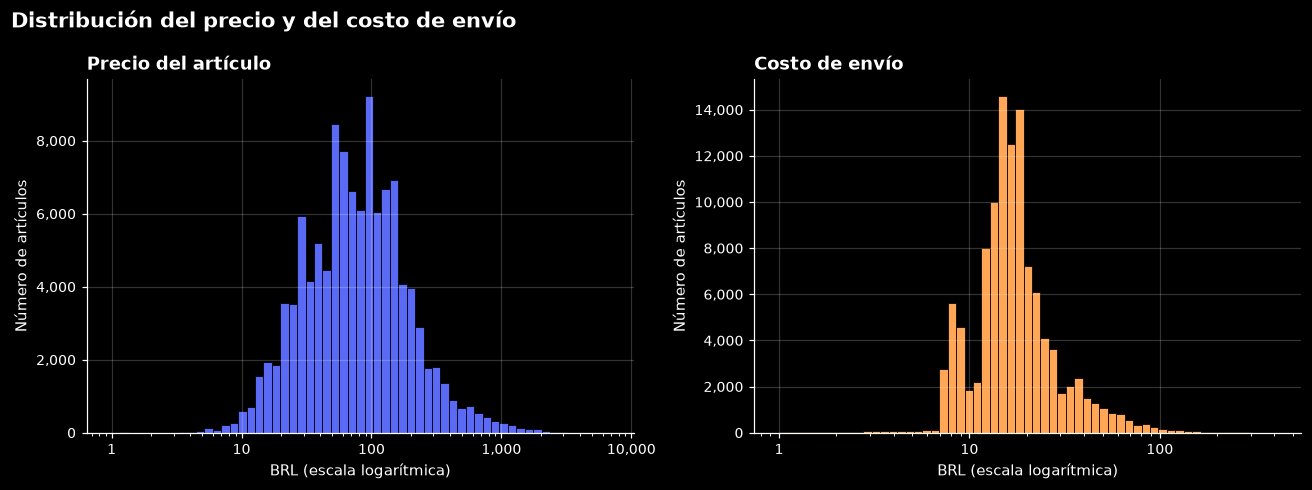

In [34]:
with plt.style.context("dark_background"):
    variables = [("price", "Precio del artículo", COL["azul"]),
                 ("freight_value", "Costo de envío", COL["naranja"])]

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    for ax, (col, titulo, color) in zip(axes, variables):
        vista = items_sellers.loc[items_sellers[col] >= 1, col]  # la escala log no admite ceros
        bins = np.logspace(0, np.log10(vista.max()), 60)
        ax.hist(vista, bins=bins, color=color, edgecolor="black", linewidth=0.5)
        ax.set_xscale("log")
        ax.set_title(titulo, fontsize=12, fontweight="bold", loc="left")
        ax.set_xlabel("BRL (escala logarítmica)", fontsize=10)
        ax.set_ylabel("Número de artículos", fontsize=10)
        ax.tick_params(labelsize=9)
        ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
        ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
        ax.grid(alpha=0.2)

    fig.suptitle("Distribución del precio y del costo de envío", fontsize=14, fontweight="bold",
                 x=0.01, ha="left")
    mostrar(fig, "3_1a_histogramas")


#### Pregunta 2. ¿Cuántos artículos vende un vendedor normalmente? ¿Las ventas se concentran en un grupo especifico de vendedores?


In [35]:
por_vendedor = (items_sellers.groupby("seller_id")
                .agg(articulos=("order_item_id", "size"),
                     pedidos=("order_id", "nunique"),
                     ventas_brl=("price", "sum"),
                     estado=("seller_state", "first")))

cols = ["articulos", "pedidos", "ventas_brl"]
res_v = por_vendedor[cols].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]).T
res_v["asimetria"] = por_vendedor[cols].skew()
display(res_v.round(2))


,count,mean,std,min,25%,50%,75%,90%,99%,max,asimetria
articulos,3095.0,36.40,119.19,1.0,2.00,8.00,24.00,80.00,431.24,2033.00,9.79
pedidos,3095.0,32.31,105.14,1.0,2.00,6.00,21.50,69.60,402.24,1854.00,9.64
ventas_brl,3095.0,4391.48,13922.00,3.5,208.85,821.48,3280.83,9525.32,55108.72,229472.63,9.05


In [36]:
orden = por_vendedor.sort_values("ventas_brl", ascending=False)
participacion = orden["ventas_brl"].cumsum() / orden["ventas_brl"].sum()
n = len(orden)

for pct in [0.01, 0.10, 0.20]:
    k = int(round(n * pct))
    print(f"El {pct:.0%} de los vendedores ({k:,}) genera el "
          f"{participacion.iloc[k - 1]:.1%} de las ventas")

for meta in [0.5, 0.8]:
    k = (participacion < meta).sum() + 1
    print(f"{k:,} vendedores ({k / n:.1%}) generan el {meta:.0%} de las ventas")


El 1% de los vendedores (31) genera el 26.1% de las ventas
El 10% de los vendedores (310) genera el 67.6% de las ventas
El 20% de los vendedores (619) genera el 82.7% de las ventas
130 vendedores (4.2%) generan el 50% de las ventas
544 vendedores (17.6%) generan el 80% de las ventas


In [37]:
cortes = [0, 1, 5, 20, 100, np.inf]
etiquetas = ["1 artículo", "2 a 5", "6 a 20", "21 a 100", "más de 100"]
por_vendedor["segmento"] = pd.cut(por_vendedor["articulos"], bins=cortes, labels=etiquetas)

seg = (por_vendedor.groupby("segmento", observed=True)
       .agg(vendedores=("articulos", "size"), ventas_brl=("ventas_brl", "sum")))
seg["%_vendedores"] = seg["vendedores"] / seg["vendedores"].sum() * 100
seg["%_ventas"] = seg["ventas_brl"] / seg["ventas_brl"].sum() * 100
display(seg.round(1))


,vendedores,ventas_brl,%_vendedores,%_ventas
segmento,,,,
1 artículo,509,115167.5,16.4,0.8
2 a 5,834,527065.8,26.9,3.9
6 a 20,882,1698275.4,28.5,12.5
21 a 100,634,4024854.2,20.5,29.6
más de 100,236,7226280.7,7.6,53.2


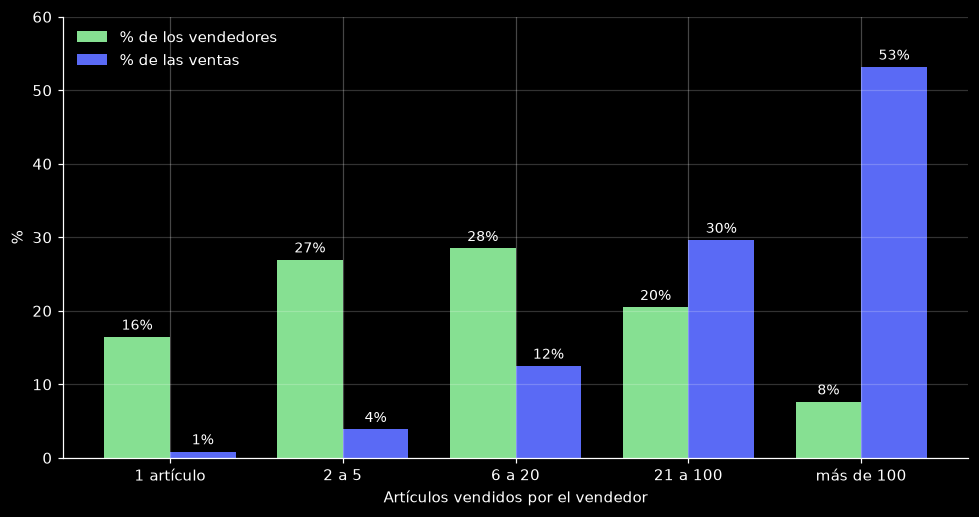

In [38]:
with plt.style.context("dark_background"):
    fig, ax = plt.subplots(figsize=(9, 4.8))

    pos = np.arange(len(seg))
    ancho = 0.38
    ax.bar(pos - ancho / 2, seg["%_vendedores"], ancho, color=COL["verde"], label="% de los vendedores")
    ax.bar(pos + ancho / 2, seg["%_ventas"], ancho, color=COL["azul"], label="% de las ventas")

    for i in range(len(seg)):
        valor_vendedores = seg["%_vendedores"].iloc[i]
        valor_ventas = seg["%_ventas"].iloc[i]
        ax.text(i - ancho / 2, valor_vendedores + 1, f"{valor_vendedores:.0f}%", ha="center", fontsize=9)
        ax.text(i + ancho / 2, valor_ventas + 1, f"{valor_ventas:.0f}%", ha="center", fontsize=9)

    ax.set_xticks(pos, seg.index)
    ax.set_ylim(0, 60)
    ax.set_xlabel("Artículos vendidos por el vendedor", fontsize=10)
    ax.set_ylabel("%", fontsize=10)
    ax.legend(loc="upper left", frameon=False)
    ax.grid(axis="y", alpha=0.2)

    mostrar(fig, "3_2_segmentos_vendedores")


#### Pregunta 3. ¿Cambia el precio y el costo de envío promedio de acuerdo con el estado del vendedor?


In [39]:
por_estado_vendedor = (items_sellers.groupby("grupo_estado")
              .agg(vendedores=("seller_id", "nunique"), articulos=("price", "size"),
                   precio_mediana=("price", "median"), precio_media=("price", "mean"),
                   flete_mediana=("freight_value", "median"), flete_media=("freight_value", "mean"),
                   flete_sobre_precio_mediana=("flete_sobre_precio", "median"))
              .sort_values("flete_mediana"))
display(por_estado_vendedor.round(2))


,vendedores,articulos,precio_mediana,precio_media,flete_mediana,flete_media,flete_sobre_precio_mediana
grupo_estado,,,,,,,
SP,1849,80342,69.0,108.95,15.38,18.50,0.24
RJ,171,4818,105.0,175.17,16.70,19.47,0.16
PR,349,8671,98.9,145.53,17.78,22.72,0.20
DF,30,899,69.9,108.73,17.80,20.57,0.26
MG,244,8827,84.9,114.60,18.06,24.16,0.26
SC,190,4075,89.0,155.20,18.78,26.15,0.24
RS,129,2199,105.0,172.15,19.33,26.08,0.21
GO,40,520,89.9,127.69,21.12,24.16,0.25
Otros,70,1927,149.9,258.43,25.54,30.60,0.17


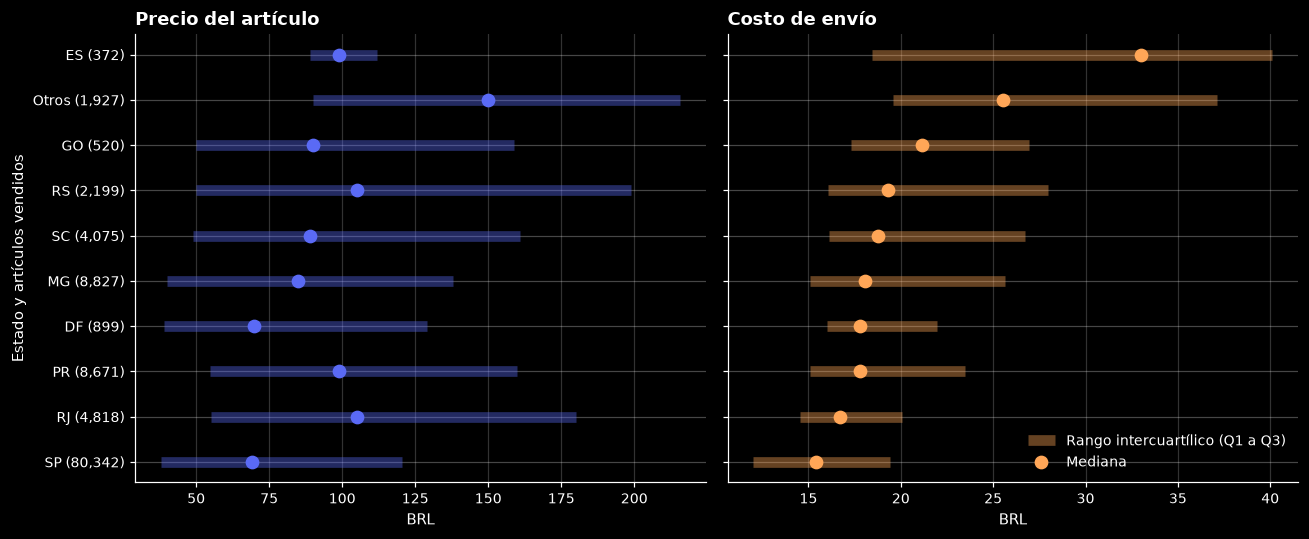

In [40]:
with plt.style.context("dark_background"):
    variables = [("price", "Precio del artículo", COL["azul"]),
                 ("freight_value", "Costo de envío", COL["naranja"])]

    cuartiles = (items_sellers.groupby("grupo_estado")[["price", "freight_value"]]
                 .quantile([0.25, 0.5, 0.75]).unstack())

    orden_estados = por_estado_vendedor.index
    etiquetas_estado = [f"{estado} ({por_estado_vendedor.loc[estado, 'articulos']:,})" for estado in orden_estados]

    fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
    for ax, (col, titulo, color) in zip(axes, variables):
        q = cuartiles[col].loc[orden_estados]
        y = np.arange(len(q))
        ax.hlines(y, q[0.25], q[0.75], color=color, lw=7, alpha=0.4, label="Rango intercuartílico (Q1 a Q3)")
        ax.plot(q[0.5], y, "o", color=color, markersize=8, label="Mediana")
        ax.set_title(titulo, fontsize=12, fontweight="bold", loc="left")
        ax.set_xlabel("BRL", fontsize=10)
        ax.tick_params(labelsize=9)
        ax.grid(axis="x", alpha=0.2)

    axes[0].set_yticks(np.arange(len(orden_estados)), etiquetas_estado)
    axes[0].set_ylabel("Estado y artículos vendidos", fontsize=10)
    axes[1].legend(loc="lower right", fontsize=9, frameon=False)

    mostrar(fig, "3_3_precio_flete_por_estado_vendedor")


#### Pregunta 4. ¿Cuál es el precio promedio por artículo y por pedido, y cómo varía según el estado del vendedor?


In [41]:
pedidos_vendedor = (items_sellers.groupby(["order_id", "seller_id", "grupo_estado"])
                    .agg(articulos=("price", "size"), ticket=("price", "sum"))
                    .reset_index())
pedidos_multivendedor = (items_sellers.groupby("order_id")["seller_id"].nunique() > 1).sum()
print(f"Pedidos con artículos de más de un vendedor: {pedidos_multivendedor:,} "
      f"({pedidos_multivendedor / items_sellers['order_id'].nunique():.1%})")

general = pd.DataFrame({
    "media": [items_sellers["price"].mean(), pedidos_vendedor["ticket"].mean(),
              pedidos_vendedor["articulos"].mean()],
    "mediana": [items_sellers["price"].median(), pedidos_vendedor["ticket"].median(),
                pedidos_vendedor["articulos"].median()],
}, index=["Ticket por artículo (BRL)", "Ticket por pedido (BRL)", "Artículos por pedido"])
display(general.round(2))
print(f"Pedidos con un solo artículo del vendedor: {(pedidos_vendedor['articulos'] == 1).mean():.1%}")

ticket_estado = (pedidos_vendedor.groupby("grupo_estado")
                 .agg(pedidos=("ticket", "size"), ticket_pedido_mediana=("ticket", "median"),
                      ticket_pedido_media=("ticket", "mean"), articulos_por_pedido=("articulos", "mean")))
ticket_estado["ticket_articulo_mediana"] = por_estado_vendedor["precio_mediana"]
ticket_estado["ticket_articulo_media"] = por_estado_vendedor["precio_media"]
ticket_estado = ticket_estado.sort_values("ticket_pedido_mediana")
display(ticket_estado.round(2))


Pedidos con artículos de más de un vendedor: 1,278 (1.3%)


,media,mediana
Ticket por artículo (BRL),120.65,74.99
Ticket por pedido (BRL),135.90,84.99
Artículos por pedido,1.13,1.00


Pedidos con un solo artículo del vendedor: 91.1%


,pedidos,ticket_pedido_mediana,ticket_pedido_media,articulos_por_pedido,ticket_articulo_mediana,ticket_articulo_media
grupo_estado,,,,,,
DF,824,75.00,118.63,1.09,69.9,108.73
SP,70950,78.00,123.37,1.13,69.0,108.95
MG,7942,89.99,127.37,1.11,84.9,114.60
GO,463,98.99,143.41,1.12,89.9,127.69
ES,318,99.00,149.97,1.17,99.0,128.20
PR,7717,99.99,163.52,1.12,98.9,145.53
SC,3672,104.00,172.23,1.11,89.0,155.20
RJ,4355,117.70,193.80,1.11,105.0,175.17
RS,1991,119.90,190.14,1.10,105.0,172.15


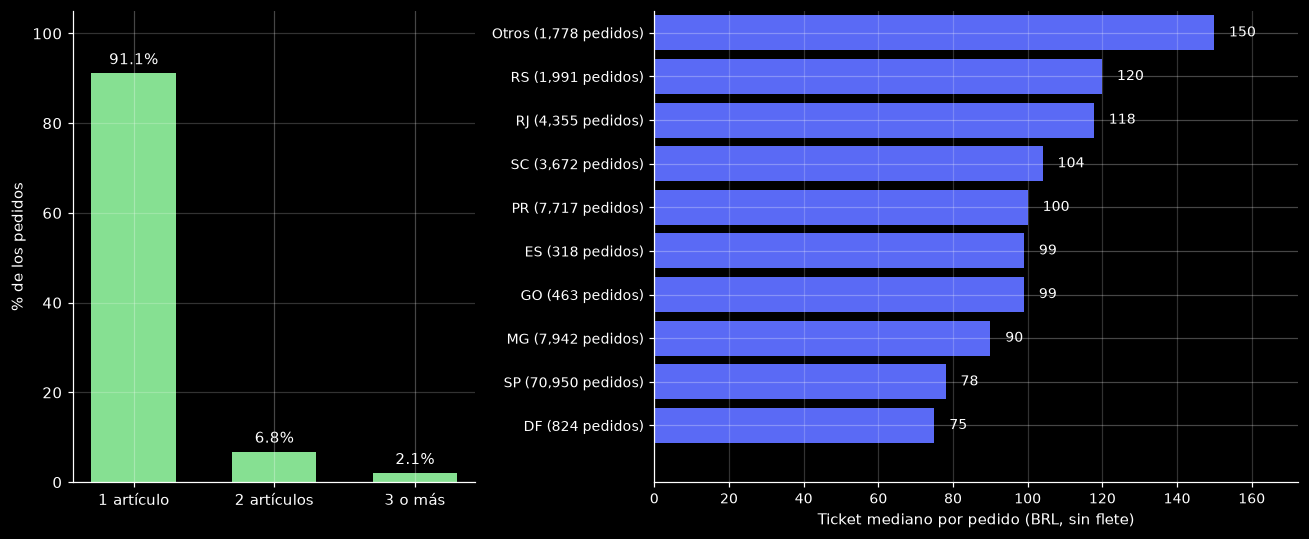

In [42]:
with plt.style.context("dark_background"):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={"width_ratios": [1, 1.6]})

    num_articulos = pedidos_vendedor["articulos"].clip(upper=3)
    reparto = num_articulos.value_counts(normalize=True).sort_index() * 100
    etiquetas = ["1 artículo", "2 artículos", "3 o más"]

    ax1.bar(etiquetas, reparto, color=COL["verde"], width=0.6)
    for i in range(len(reparto)):
        ax1.text(i, reparto.iloc[i] + 2, f"{reparto.iloc[i]:.1f}%", ha="center", fontsize=10)
    ax1.set_ylim(0, 105)
    ax1.set_ylabel("% de los pedidos", fontsize=10)
    ax1.grid(axis="y", alpha=0.2)

    orden = ticket_estado.sort_values("ticket_pedido_mediana")
    etiquetas_estado = [f"{estado} ({orden.loc[estado, 'pedidos']:,} pedidos)" for estado in orden.index]

    ax2.barh(etiquetas_estado, orden["ticket_pedido_mediana"], color=COL["azul"])
    for i in range(len(orden)):
        valor = orden["ticket_pedido_mediana"].iloc[i]
        ax2.text(valor + 4, i, f"{valor:,.0f}", va="center", fontsize=9)

    mediana_general = pedidos_vendedor["ticket"].median()
    ax2.set_ylim(-1.3, len(orden) - 0.5)
    ax2.set_xlim(0, orden["ticket_pedido_mediana"].max() * 1.15)
    ax2.set_xlabel("Ticket mediano por pedido (BRL, sin flete)", fontsize=10)
    ax2.tick_params(labelsize=9)
    ax2.grid(axis="x", alpha=0.2)

    mostrar(fig, "3_4_ticket_por_estado_vendedor")


### Órdenes, pagos y productos (`Proyecto_Angel.ipynb`)

Preguntas que el script de R alcanza a responder, y las gráficas del tablero que salen de las tablas ya construidas:

- ¿La base de órdenes está completa y hay identificadores duplicados? ¿Cómo se reparten los estatus?
- ¿Cuál es el tiempo estimado, el tiempo real y los días de retraso? ¿Cómo cambian, en promedio simple y ponderado por el importe, según la fecha de compra?
- ¿El importe pagado coincide con el precio más el envío? ¿Qué órdenes no tienen pago o no tienen costo, y con qué medio y plazo se pagaron las que no cuadran?
- ¿Qué tan completa está la categoría y cómo se agrupan?
- ¿Cómo se reparten los artículos entre regiones? ¿El peso se relaciona con el flete? ¿Qué distancia lineal hay entre cliente y vendedor?

En el tablero el eje dice «Suma de…» porque Power BI suma un campo que ya está agregado por día. Con el eje en días, esa suma es el valor del día.


In [43]:
plt.rcParams.update(ESTILO_ANGEL)


#### Estatus de la orden


,order_status,ordenes,porcentaje
3,delivered,96478,97.020344
6,shipped,1107,1.113223
1,canceled,625,0.628513
7,unavailable,609,0.612423
4,invoiced,314,0.315765
5,processing,301,0.302692
2,created,5,0.005028
0,approved,2,0.002011


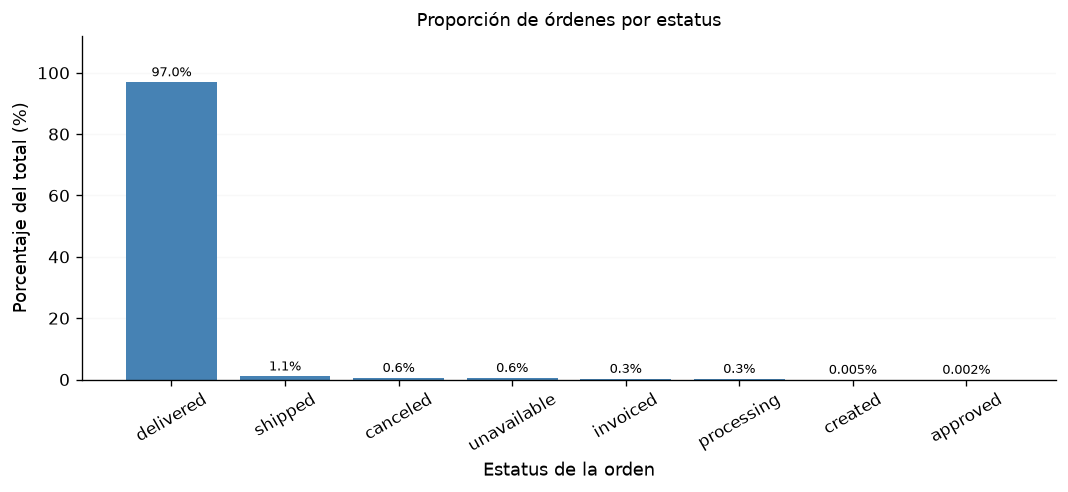

In [44]:
proporcion_estatus = (
    ordenes.groupby("order_status", as_index=False)
    .size()
    .rename(columns={"size": "ordenes"})
)
proporcion_estatus["porcentaje"] = proporcion_estatus["ordenes"] / len(ordenes) * 100
proporcion_estatus = proporcion_estatus.sort_values("porcentaje", ascending=False)
display(proporcion_estatus)

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.bar(
    proporcion_estatus["order_status"],
    proporcion_estatus["porcentaje"],
    color="steelblue",
)
for etiqueta, altura in zip(proporcion_estatus["order_status"], proporcion_estatus["porcentaje"]):
    if altura >= 1:
        texto = f"{altura:.1f}%"
    elif altura >= 0.1:
        texto = f"{altura:.1f}%"
    else:
        texto = f"{altura:.3f}%"
    ax.text(etiqueta, altura + 0.8, texto, ha="center", va="bottom", fontsize=8)
ax.set_ylim(0, 112)
ax.set_ylabel("Porcentaje del total (%)")
ax.set_xlabel("Estatus de la orden")
ax.set_title("Proporción de órdenes por estatus")
ax.tick_params(axis="x", rotation=30)
ax.yaxis.grid(True, color="#E6E6E6")
ax.set_axisbelow(True)
fig.tight_layout()
display(fig)
plt.close(fig)


#### Tiempos de entrega

La serie cuenta órdenes entregadas. El 24 de noviembre de 2017 marca 1,147 porque esas son las compras de ese día que terminaron en `delivered`, no las 1,176 compras de cualquier estatus. Los tramos rectos de finales de 2016 unen días entre los que no hubo ninguna orden entregada. Noviembre de 2016 no aporta puntos.

La línea clara es el tiempo real. La línea oscura es el tiempo prometido. Durante casi todo el periodo la promesa está por encima de la entrega observada.

El desplome de las dos series después de julio de 2018 no se lee como una mejora súbita de la logística. El extracto termina a finales de agosto de 2018 y la serie solo conserva órdenes ya entregadas, así que al final solo quedan las entregas cortas.


In [45]:
display(resumen_global.round(2).to_frame("dias"))
print("Días con al menos una orden entregada:", len(serie))
print(
    "24 nov 2017, entregadas:",
    int(serie.loc[pd.Timestamp("2017-11-24"), "conteo"]),
    "| compras de cualquier estatus:",
    int((ordenes["order_purchase_timestamp"].dt.normalize() == "2017-11-24").sum()),
)


,dias
media_simple_estimada,24.37
media_ponderada_estimada,25.53
media_simple_real,12.50
media_ponderada_real,13.41
media_retraso_censurado,0.72
media_retraso_con_signo,-11.88


Días con al menos una orden entregada: 612
24 nov 2017, entregadas: 1147 | compras de cualquier estatus: 1176


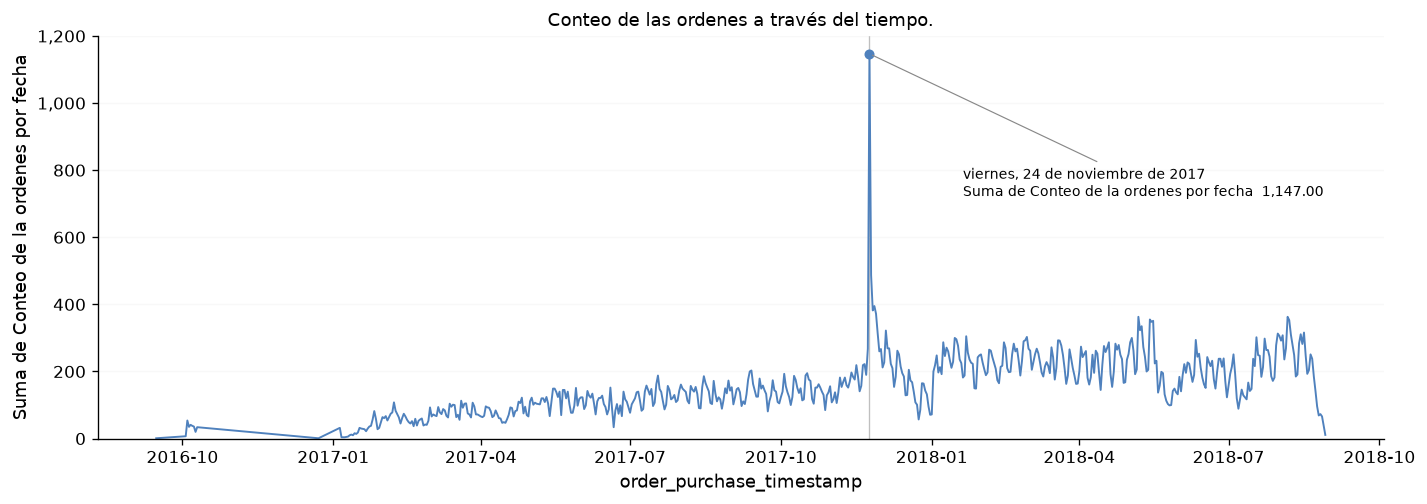

In [46]:
fig, ax = plt.subplots(figsize=(12, 4.3))
ax.plot(serie.index, serie["conteo"], color="#4F81BD", lw=1.15)
pico = pd.Timestamp("2017-11-24")
valor_pico = float(serie.loc[pico, "conteo"])
ax.plot(pico, valor_pico, "o", color="#4F81BD", ms=5, zorder=3)
ax.axvline(pico, color="#BFBFBF", lw=0.8, zorder=0)
ax.annotate(
    f"viernes, 24 de noviembre de 2017\nSuma de Conteo de la ordenes por fecha  {valor_pico:,.2f}",
    xy=(pico, valor_pico),
    xytext=(pd.Timestamp("2018-01-20"), 760),
    fontsize=8.5,
    arrowprops=dict(arrowstyle="-", color="#888888", lw=0.7),
    va="center",
)
ax.set_ylim(0, 1200)
ax.set_yticks([0, 200, 400, 600, 800, 1000, 1200])
ax.yaxis.set_major_formatter(FuncFormatter(lambda valor, _pos: f"{valor:,.0f}"))
ax.set_title("Conteo de las ordenes a través del tiempo.")
ax.set_xlabel("order_purchase_timestamp")
ax.set_ylabel("Suma de Conteo de la ordenes por fecha")
ax.yaxis.grid(True, color="#E6E6E6")
ax.set_axisbelow(True)
fig.tight_layout()
display(fig)
plt.close(fig)


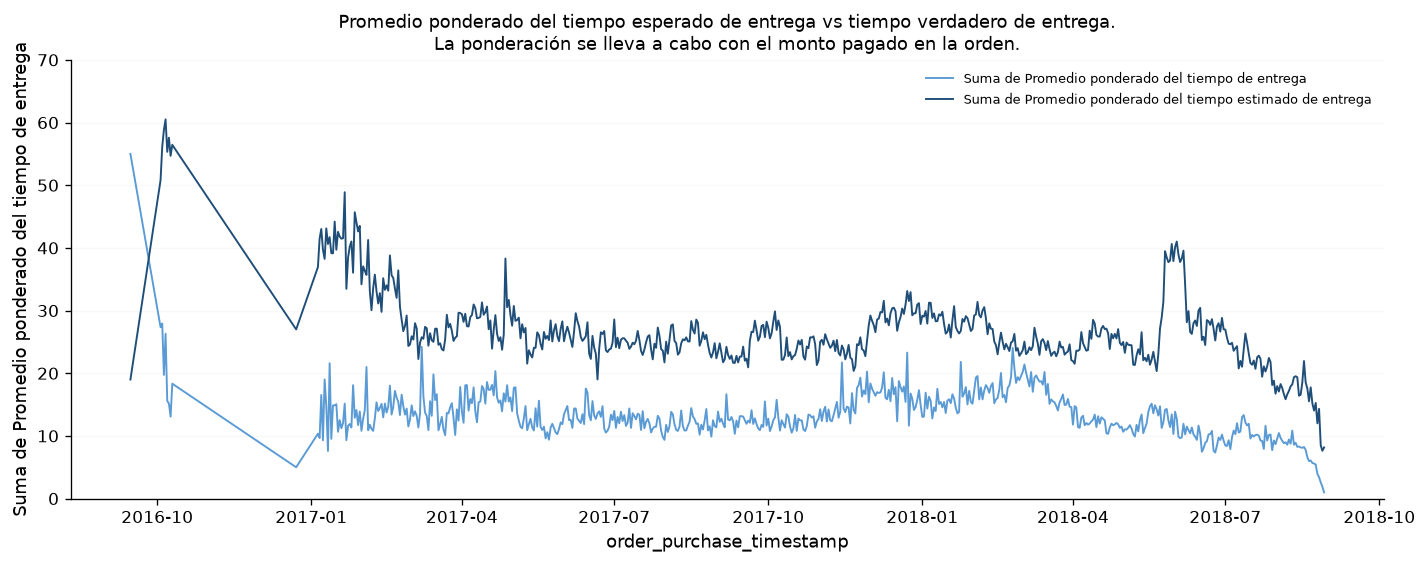

Máximo del tiempo estimado ponderado entre mayo y junio de 2018: 41.0 días el 2018-06-02
Último día de la serie 2018-08-29 | real 1.0 | estimado 8.2


In [47]:
fig, ax = plt.subplots(figsize=(12, 4.8))
ax.plot(
    serie.index,
    serie["promedio_ponderado_entrega"],
    color="#5B9BD5",
    lw=1.15,
    label="Suma de Promedio ponderado del tiempo de entrega",
)
ax.plot(
    serie.index,
    serie["promedio_ponderado_estimado"],
    color="#1F4E79",
    lw=1.15,
    label="Suma de Promedio ponderado del tiempo estimado de entrega",
)
ax.set_ylim(0, 70)
ax.set_yticks(range(0, 71, 10))
ax.set_title(
    "Promedio ponderado del tiempo esperado de entrega vs tiempo verdadero de entrega.\n"
    "La ponderación se lleva a cabo con el monto pagado en la orden."
)
ax.set_xlabel("order_purchase_timestamp")
ax.set_ylabel("Suma de Promedio ponderado del tiempo de entrega")
ax.legend(frameon=False, loc="upper right", fontsize=8)
ax.yaxis.grid(True, color="#E6E6E6")
ax.set_axisbelow(True)
fig.tight_layout()
display(fig)
plt.close(fig)

recorte_2018 = serie.loc["2018-05-01":"2018-06-30", "promedio_ponderado_estimado"]
print(
    "Máximo del tiempo estimado ponderado entre mayo y junio de 2018:",
    f"{recorte_2018.max():.1f} días el {recorte_2018.idxmax().date()}",
)
print(
    "Último día de la serie",
    serie.index.max().date(),
    f"| real {serie['promedio_ponderado_entrega'].iloc[-1]:.1f}",
    f"| estimado {serie['promedio_ponderado_estimado'].iloc[-1]:.1f}",
)


#### Pago contra costo, plazos y medio de pago

La población de las donas de pago y de plazos es el subconjunto cuya diferencia redondeada es distinta de cero: 318 órdenes. Una orden puede tener más de un registro de pago.

El tablero cuenta órdenes distintas por tipo y, por separado, órdenes distintas por plazo. Una orden con tarjeta y vale entra en los dos tipos; una orden con dos plazos distintos entra en los dos plazos. Por eso los gajos suman 326 y 328, no 318. Los porcentajes usan esa suma como denominador.

El corte de plazos es el del tablero: 1 cuota, 2 cuotas, 3 a 5 (etiqueta «De 2 a 5 pagos»), 6 a 10, 11 a 15, 16 a 20 y 21 a 24. Las 2 cuotas no entran en «De 2 a 5 pagos».


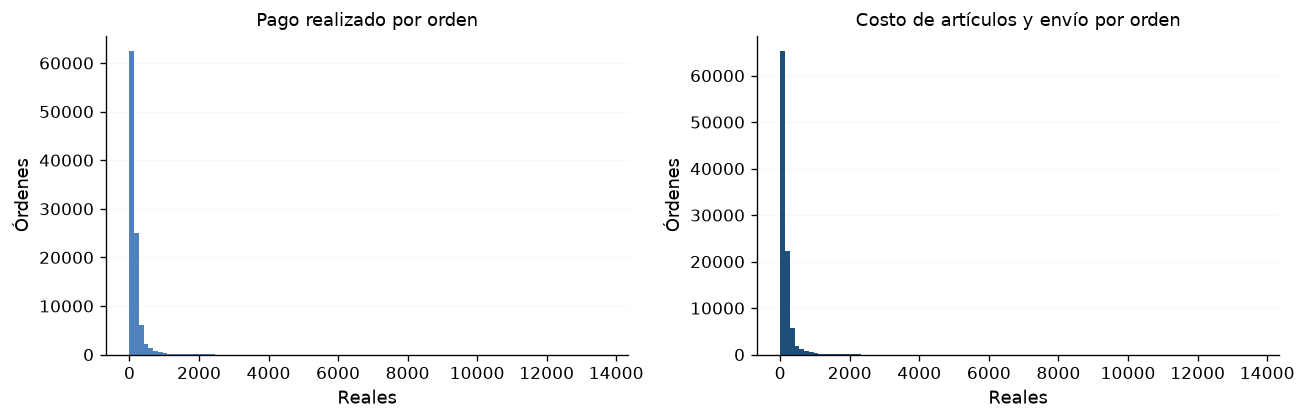

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(pago_por_orden["pago_realizado"], bins=100, color="#4F81BD")
axes[0].set_title("Pago realizado por orden")
axes[0].set_xlabel("Reales")
axes[0].set_ylabel("Órdenes")
axes[1].hist(costo_por_orden["costo"], bins=100, color="#1F4E79")
axes[1].set_title("Costo de artículos y envío por orden")
axes[1].set_xlabel("Reales")
axes[1].set_ylabel("Órdenes")
for eje in axes:
    eje.yaxis.grid(True, color="#E6E6E6")
    eje.set_axisbelow(True)
fig.tight_layout()
display(fig)
plt.close(fig)


Base de la dona de estatus (diferencia no calculable): 776
De ellas, sin costo: 775 | sin pago y con costo: 1


,ordenes
bandera,
Sin diferencias,98347
Con diferencias,1094


,ordenes
bandera_detalle,
Con valores faltantes,776
Con diferencias,318


,ordenes_sin_diferencia_calculable
order_status,
canceled,164
created,5
delivered,1
invoiced,2
shipped,1
unavailable,603


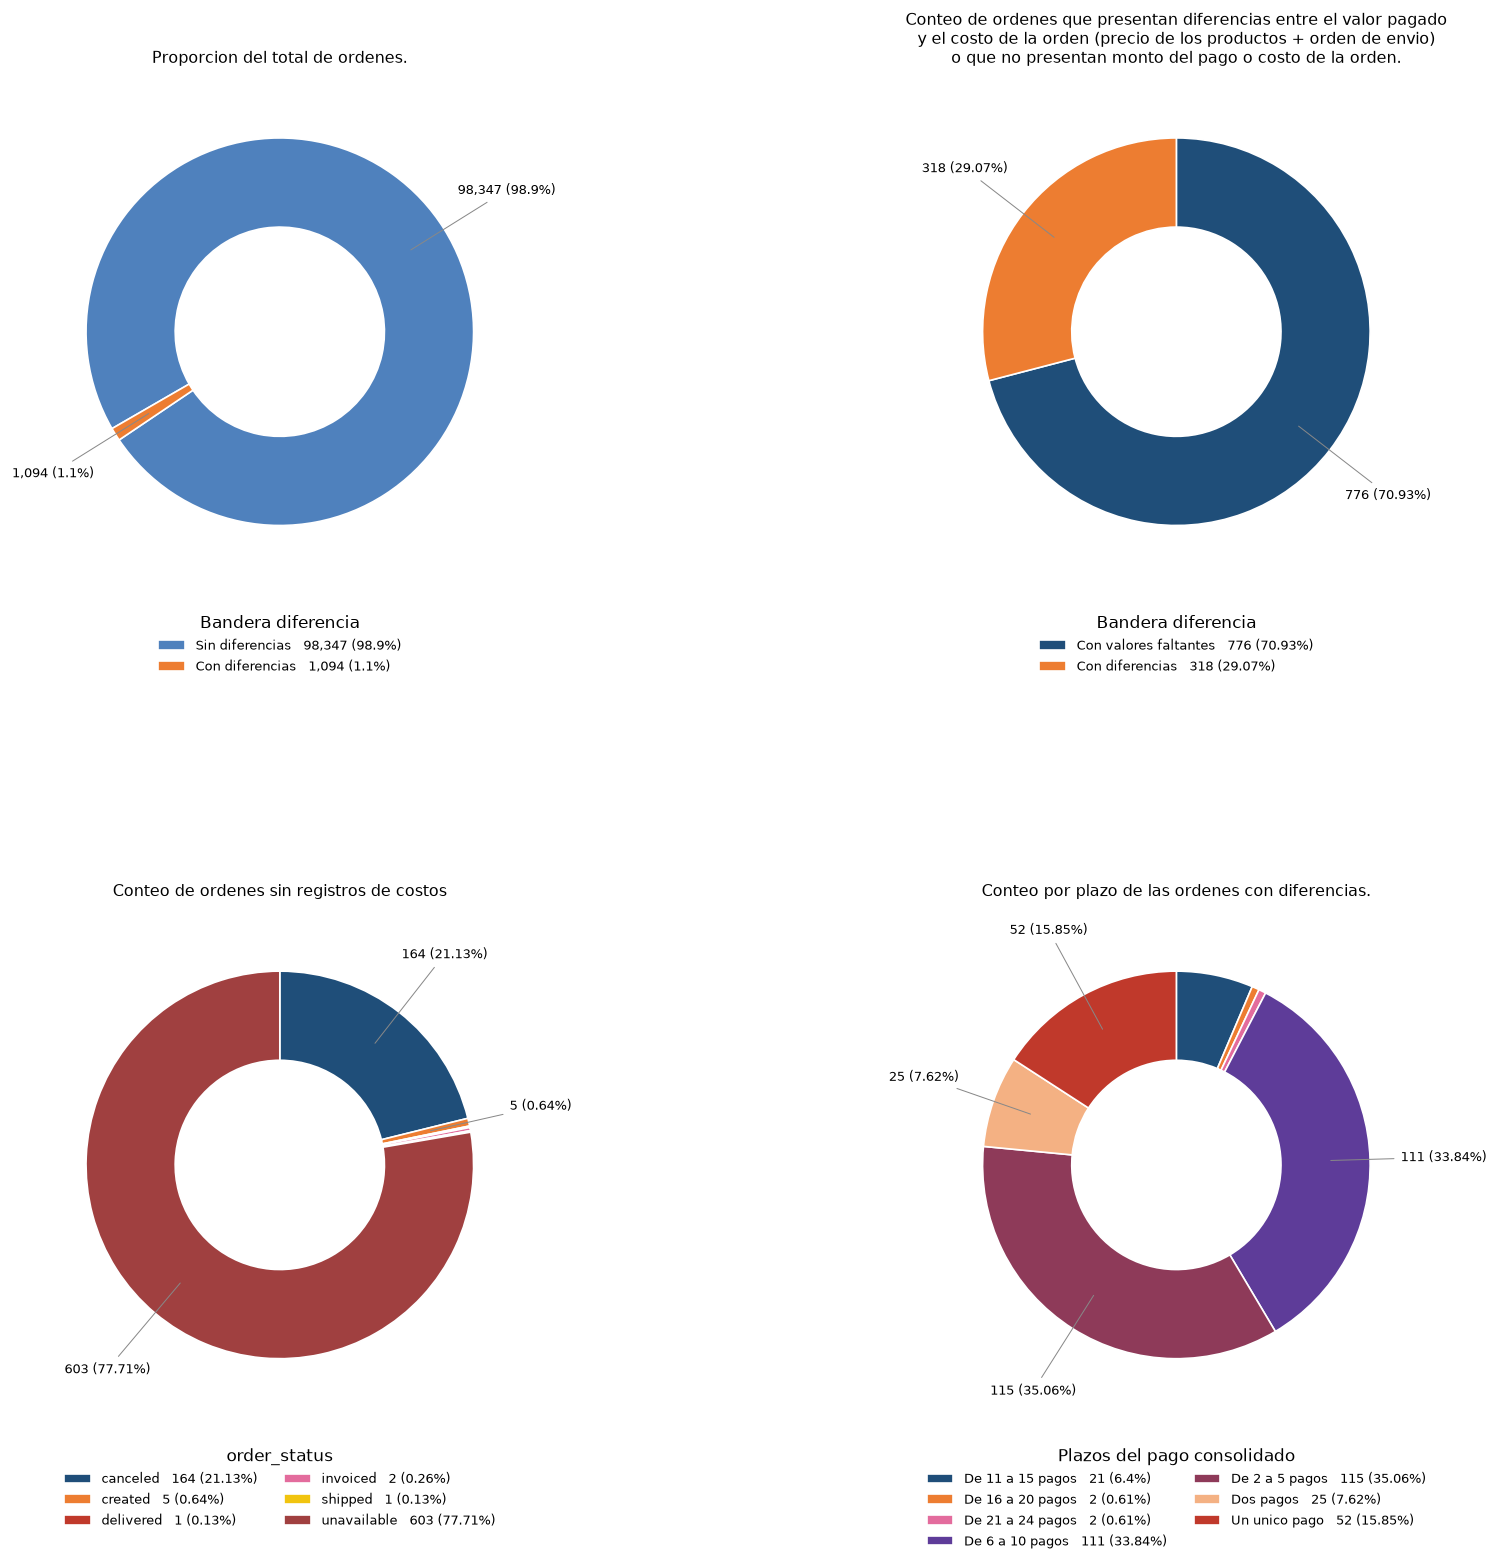

,ordenes_distintas
plazo,
De 11 a 15 pagos,21
De 16 a 20 pagos,2
De 21 a 24 pagos,2
De 6 a 10 pagos,111
De 2 a 5 pagos,115
Dos pagos,25
Un unico pago,52


Órdenes con diferencia redondeada: 318 | gajos de plazo (una orden puede caer en dos): 328


In [49]:
fig, axes = plt.subplots(2, 2, figsize=(14.8, 12.2))
grafica_dona(
    axes[0, 0], conteo_bandera, colores_bandera,
    "Proporcion del total de ordenes.", "Bandera diferencia",
    min_pct=0.5, startangle=210,
)
grafica_dona(
    axes[0, 1], conteo_detalle, colores_detalle,
    "Conteo de ordenes que presentan diferencias entre el valor pagado\n"
    "y el costo de la orden (precio de los productos + orden de envio)\n"
    "o que no presentan monto del pago o costo de la orden.",
    "Bandera diferencia", min_pct=0.5,
)
grafica_dona(
    axes[1, 0], conteo_status, colores_status,
    "Conteo de ordenes sin registros de costos", "order_status", min_pct=0.4,
)
print("Base de la dona de estatus (diferencia no calculable):", int(conteo_status.sum()))
print("De ellas, sin costo:", int(comparacion_ordenes["costo"].isna().sum()),
      "| sin pago y con costo:", int((comparacion_ordenes["pago_realizado"].isna() & comparacion_ordenes["costo"].notna()).sum()))
display(conteo_bandera.to_frame("ordenes"))
display(conteo_detalle.to_frame("ordenes"))
display(conteo_status.to_frame("ordenes_sin_diferencia_calculable"))

grafica_dona(
    axes[1, 1], conteo_plazos, colores_plazo,
    "Conteo por plazo de las ordenes con diferencias.",
    "Plazos del pago consolidado", min_pct=7,
)
fig.subplots_adjust(left=0.04, right=0.98, top=0.94, bottom=0.04, hspace=0.72, wspace=0.16)
display(fig)
plt.close(fig)
display(conteo_plazos.to_frame("ordenes_distintas"))
print(
    "Órdenes con diferencia redondeada:",
    con_diferencia["order_id"].nunique(),
    "| gajos de plazo (una orden puede caer en dos):",
    int(conteo_plazos.sum()),
)


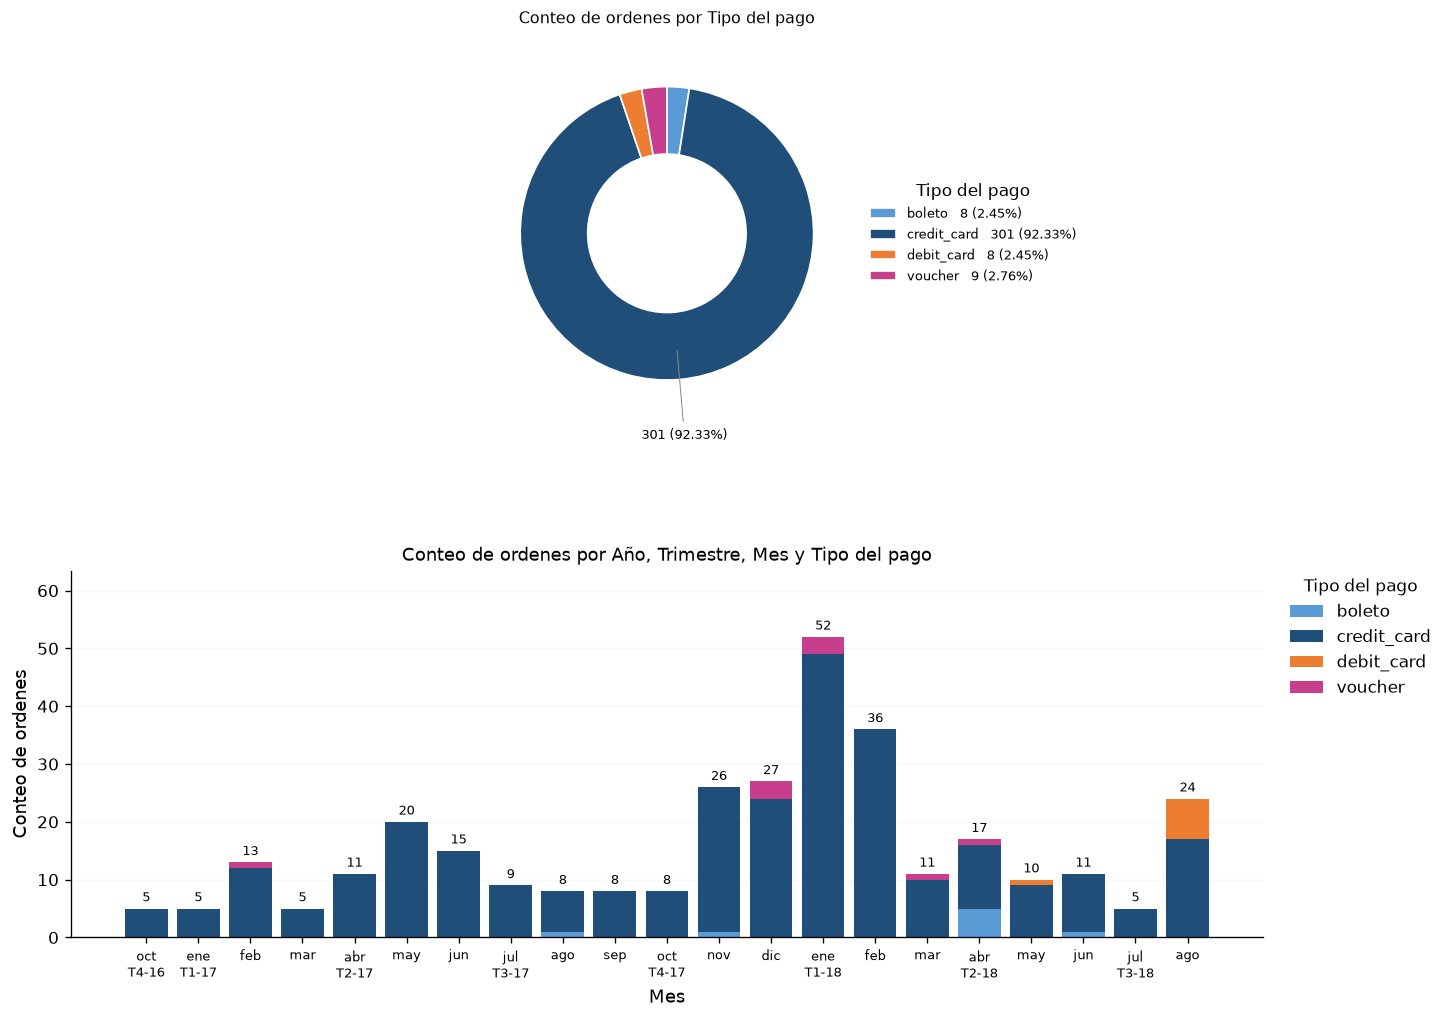

,ordenes_distintas
payment_type,
boleto,8
credit_card,301
debit_card,8
voucher,9


payment_type,boleto,credit_card,debit_card,voucher,total
mes,,,,,
2016-10,0,5,0,0,5
2017-01,0,5,0,0,5
2017-02,0,12,0,1,13
2017-03,0,5,0,0,5
2017-04,0,11,0,0,11
2017-05,0,20,0,0,20
2017-06,0,15,0,0,15
2017-07,0,9,0,0,9
2017-08,1,7,0,0,8


Gajos de tipo de pago: 326 | órdenes distintas: 318


In [50]:
fig = plt.figure(figsize=(13.8, 8.6))
ax_dona = fig.add_subplot(2, 1, 1)
ax_barras = fig.add_subplot(2, 1, 2)
grafica_dona(
    ax_dona, conteo_tipo, colores_tipo,
    "Conteo de ordenes por Tipo del pago", "Tipo del pago",
    min_pct=10, leyenda="derecha",
)

x = np.arange(len(mensual))
fondo = np.zeros(len(mensual))
for tipo in orden_tipos:
    valores = mensual[tipo].to_numpy(dtype=float)
    ax_barras.bar(x, valores, bottom=fondo, width=0.82, color=colores_tipo[tipo], label=tipo)
    fondo = fondo + valores
for posicion, total in enumerate(fondo):
    ax_barras.text(posicion, total + 0.7, f"{int(total)}", ha="center", va="bottom", fontsize=8)

etiquetas = []
trimestre_previo = None
for periodo in mensual.index:
    trimestre = f"T{(periodo.month - 1) // 3 + 1} {periodo.year}"
    mes = MESES[periodo.month - 1]
    if trimestre != trimestre_previo:
        etiquetas.append(f"{mes}\nT{(periodo.month - 1) // 3 + 1}-{str(periodo.year)[2:]}")
        trimestre_previo = trimestre
    else:
        etiquetas.append(mes)
ax_barras.set_xticks(x)
ax_barras.set_xticklabels(etiquetas, fontsize=8)
ax_barras.set_ylim(0, max(fondo) * 1.22)
ax_barras.set_ylabel("Conteo de ordenes")
ax_barras.set_xlabel("Mes")
ax_barras.set_title("Conteo de ordenes por Año, Trimestre, Mes y Tipo del pago")
ax_barras.legend(
    title="Tipo del pago", frameon=False,
    loc="upper left", bbox_to_anchor=(1.01, 1.02),
)
ax_barras.yaxis.grid(True, color="#E6E6E6")
ax_barras.set_axisbelow(True)
fig.subplots_adjust(left=0.06, right=0.78, top=0.94, bottom=0.08, hspace=0.42)
display(fig)
plt.close(fig)

display(conteo_tipo.to_frame("ordenes_distintas"))
display(mensual.assign(total=mensual.sum(axis=1)))
print(
    "Gajos de tipo de pago:",
    int(conteo_tipo.sum()),
    "| órdenes distintas:",
    int(tipo_orden["order_id"].nunique()),
)


#### Productos, región, peso y distancia

El conteo regional es de artículos integrados, no de órdenes: una orden con tres productos suma tres. La distancia lineal ordena pares de códigos postales y no mide kilómetros de carretera.


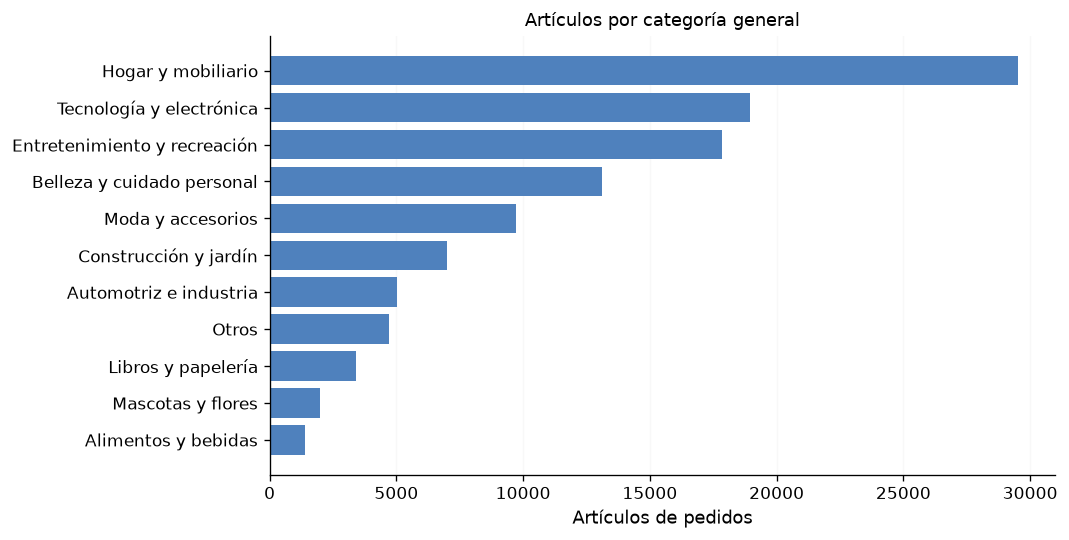

In [51]:
fig, ax = plt.subplots(figsize=(9, 4.6))
ordenado = conteo_categorias.sort_values("articulos")
ax.barh(ordenado["categoria_general"], ordenado["articulos"], color="#4F81BD")
ax.set_xlabel("Artículos de pedidos")
ax.set_title("Artículos por categoría general")
ax.xaxis.grid(True, color="#E6E6E6")
ax.set_axisbelow(True)
fig.tight_layout()
display(fig)
plt.close(fig)


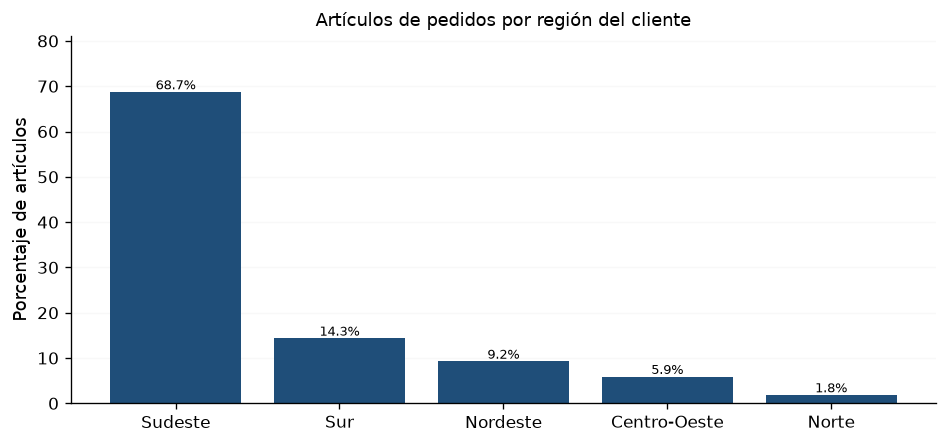

In [52]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(conteo_region["region"], conteo_region["porcentaje"], color="#1F4E79")
for region, porcentaje in zip(conteo_region["region"], conteo_region["porcentaje"]):
    ax.text(region, porcentaje + 0.6, f"{porcentaje:.1f}%", ha="center", fontsize=8)
ax.set_ylim(0, conteo_region["porcentaje"].max() * 1.18)
ax.set_ylabel("Porcentaje de artículos")
ax.set_title("Artículos de pedidos por región del cliente")
ax.yaxis.grid(True, color="#E6E6E6")
ax.set_axisbelow(True)
fig.tight_layout()
display(fig)
plt.close(fig)


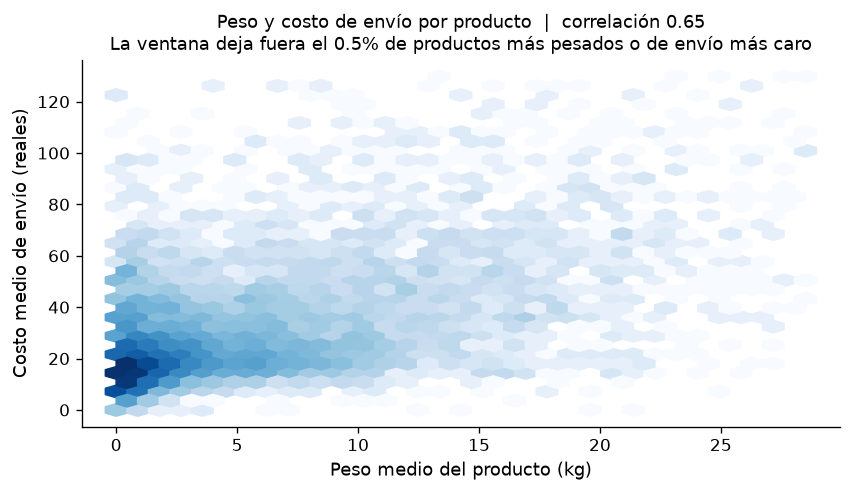

In [53]:
fig, ax = plt.subplots(figsize=(7.2, 4.2))
completos = relacion_peso.dropna()
peso_kg = completos["peso"] / 1000
flete = completos["flete"]
ventana = (peso_kg <= peso_kg.quantile(0.995)) & (flete <= flete.quantile(0.995))
ax.hexbin(peso_kg[ventana], flete[ventana], gridsize=32, cmap="Blues", mincnt=1, bins="log")
ax.set_xlabel("Peso medio del producto (kg)")
ax.set_ylabel("Costo medio de envío (reales)")
ax.set_title(
    f"Peso y costo de envío por producto  |  correlación {correlacion_peso:.2f}\n"
    "La ventana deja fuera el 0.5% de productos más pesados o de envío más caro"
)
fig.tight_layout()
display(fig)
plt.close(fig)


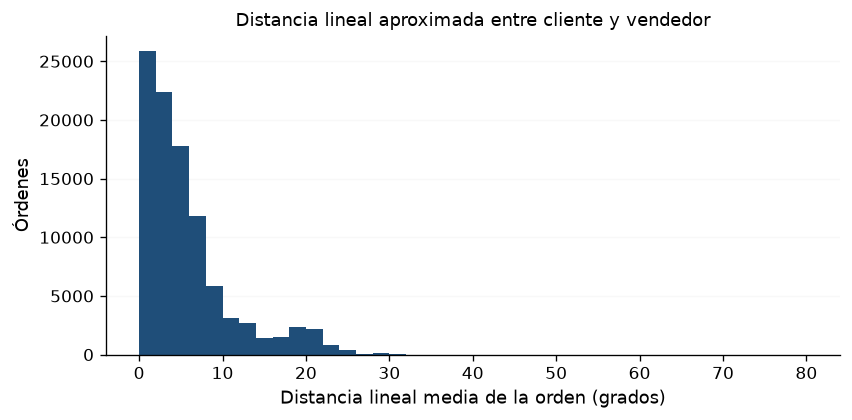

In [54]:
fig, ax = plt.subplots(figsize=(7.2, 3.6))
ax.hist(distancia_pedido["distancia"], bins=40, color="#1F4E79")
ax.set_xlabel("Distancia lineal media de la orden (grados)")
ax.set_ylabel("Órdenes")
ax.set_title("Distancia lineal aproximada entre cliente y vendedor")
ax.yaxis.grid(True, color="#E6E6E6")
ax.set_axisbelow(True)
fig.tight_layout()
display(fig)
plt.close(fig)


In [55]:
plt.rcParams.update(ESTILO_BASE)


## Conclusión

La comprobación recorre las cifras de las tres subsecciones. Los resultados redactan cada pregunta con esas cifras. El alcance fija lo que el extracto no alcanza a decir.


### Comprobación

El primer bloque recorre el tamaño del extracto, la definición de tarde y las brechas de la reseña. El segundo comprueba precio, flete, concentración y estado del vendedor. El tercero comprueba las cifras de órdenes, pagos y el tablero. Si una afirmación deja de cumplirse, la celda se detiene.


In [56]:
assert pedidos["order_id"].is_unique
assert clientes["customer_id"].is_unique
assert productos["product_id"].is_unique
assert traduccion["product_category_name"].is_unique
assert len(base) == len(pedidos) == 99441
assert base["order_id"].is_unique
assert base["customer_state"].notna().all()
assert set(pedidos["order_estimated_delivery_date"].dt.hour.unique()) == {0}
assert set(resenas["review_score"].unique()) <= {1, 2, 3, 4, 5}
assert articulos["shipping_limit_date"].dt.hour.nunique() > 1
assert grupos_id["notas_distintas"].eq(1).all()
assert grupos_id["pedidos_distintos"].gt(1).all()
assert int(calidad_resena.loc["Pedidos con más de una reseña"]) > 400
assert int(calidad_resena.loc["Pedidos con notas distintas"]) > 100
assert int(calidad_resena.loc["Reseñas sin pedido"]) == 0
assert 1 <= n_delivered_sin_fecha <= 20
assert n_fechados_otro_estado < 30
assert fechados["tarde"].notna().all()
assert base.loc[base["dia_entrega"].isna(), "tarde"].isna().all()
assert fechados["espera_dias"].min() > 0
assert (fechados["atraso_dias"].lt(0)).mean() > 0.90
assert 0.06 < fechados["tarde"].mean() < 0.08

desacuerdo = fechados["tarde"].ne(fechados["tarde_reloj"])
assert int(desacuerdo.sum()) == int(fechados["atraso_dias"].eq(0).sum())
assert fechados.loc[fechados["atraso_dias"].eq(0), "tarde_reloj"].all()
assert mismo_dia["nota"].mean() > 3.8
assert tarde_nota["nota"].mean() < 2.5
assert a_tiempo["nota"].mean() > 4.1
assert a_tiempo["nota"].mean() - tarde_nota["nota"].mean() > 1.8
assert sin_entrega["nota"].mean() < 2.0
assert sin_entrega["nota"].le(2).mean() > 0.70
assert tarde_nota["nota"].le(2).mean() > 0.55
assert a_tiempo["nota"].le(2).mean() < 0.12

assert por_tramo.loc["8 días o más antes", "nota"] > por_tramo.loc["el día prometido", "nota"]
assert por_tramo.loc["el día prometido", "nota"] > por_tramo.loc["1 a 3 días tarde", "nota"]
assert por_tramo.loc["1 a 3 días tarde", "nota"] > por_tramo.loc["8 a 14 días tarde", "nota"]
assert por_tramo["nota"].max() - por_tramo["nota"].min() > 2
assert espera_larga_a_tiempo > espera_larga_tarde + 1
assert espera_corta_a_tiempo > espera_larga_a_tiempo

assert resumen_tramo.loc["Tarde", "mediana_transito"] > resumen_tramo.loc["En el día o antes", "mediana_transito"] + 10
assert tasa_vendedor.loc["Pasado el límite", "tasa_cliente_tarde"] > 3 * tasa_vendedor.loc["Dentro del límite", "tasa_cliente_tarde"]
assert vendedor_entre_clientes_tarde < 0.40
assert 0.05 < parte_vendedor_tarde < 0.12

assert tarde_nota["respondio_antes"].mean() > 0.65
assert a_tiempo["respondio_antes"].mean() < 0.01
assert nota_tarde_antes < 2.0
assert nota_tarde_despues > 3.4
assert nota_tarde_despues < a_tiempo["nota"].mean() - 0.4
assert a_tiempo["encuesta_menos_entrega"].median() >= 0
assert tarde_nota["encuesta_menos_entrega"].median() < 0
assert tarde_nota["encuesta_menos_promesa"].median() > 0

assert varios_vendedores.mean() < un_vendedor.mean() - 1
assert varios_items.mean() < un_vendedor_un_item.mean() - 0.3
assert varios_items.mean() > un_vendedor_un_item.mean() - 1
assert -1.0 < brecha_categoria < -0.4
assert abs(brecha_flete) < 0.08
assert abs(brecha_precio) < 0.08
assert correlaciones.loc["Atraso de calendario, días"] < -0.20
assert abs(correlaciones.loc["Precio, BRL"]) < 0.08
assert abs(correlaciones.loc["Flete, BRL"]) < abs(correlaciones.loc["Atraso de calendario, días"]) / 2
assert baja_tarde["menciona_atraso"].mean() > baja_tarde["menciona_producto"].mean()
assert baja_a_tiempo["menciona_producto"].mean() > baja_a_tiempo["menciona_atraso"].mean()
assert nota_cinco["menciona_atraso"].mean() < 0.02
assert parte_bajas.get("a tiempo", 0) > 0.50
assert 0.20 < parte_bajas.get("tarde", 0) < 0.40

ids_dup = set(resenas.loc[resenas["review_id"].duplicated(keep=False), "order_id"])
sensibles = con_nota.loc[~con_nota["order_id"].isin(ids_dup)]
assert sensibles.loc[~sensibles["tarde"], "nota"].mean() - sensibles.loc[sensibles["tarde"], "nota"].mean() > 1.8
assert con_nota.loc[~con_nota["tarde"], "nota_min"].mean() - con_nota.loc[con_nota["tarde"], "nota_min"].mean() > 1.5

assert por_mes["tasa"].idxmax() == pd.Period("2018-03", freq="M")
assert por_mes["tasa"].idxmin() == pd.Period("2018-06", freq="M")
assert por_mes.loc[pd.Period("2018-03", freq="M"), "nota"] < por_mes.loc[pd.Period("2018-06", freq="M"), "nota"]
assert dia_pico == pd.Timestamp("2017-11-24")
assert noviembre.loc[puente, "tarde"].mean() > noviembre.loc[~puente, "tarde"].mean()
assert correlacion_estado < -0.80
assert por_estado["tasa"].idxmax() == "MA"
assert por_estado.loc["SP", "tasa"] < por_estado.loc["RJ", "tasa"] < por_estado.loc["MA", "tasa"]
assert por_estado.loc["SP", "nota"] > por_estado.loc["MA", "nota"]
assert por_estado.loc["RJ", "espera"] < por_estado.loc["MA", "espera"]

assert len(FIGURAS) == 10
print("VALIDACIÓN: las comprobaciones de este cuaderno se cumplieron.")
print("Figuras:", len(FIGURAS))
for titulo in FIGURAS:
    print("-", titulo)


VALIDACIÓN: las comprobaciones de este cuaderno se cumplieron.
Figuras: 10
- Atraso de calendario, entre −40 y 40 días
- Mediana de cada tramo, con las fechas en orden
- Entrega tarde al cliente, según el límite del vendedor
- Composición de la nota en tres situaciones
- Nota media según los días de atraso
- Nota media según la espera y la tardanza
- Nota media según el atraso y el momento de la respuesta
- Cuánto baja la nota media
- Tasa de atraso y nota media, por mes de compra
- Nota media y tasa de atraso, por estado del cliente


In [57]:
assert round(float(items_sellers["price"].median()), 2) == 74.99
assert round(float(items_sellers["price"].mean()), 2) == 120.65
assert round(float(items_sellers["freight_value"].median()), 2) == 16.27
assert float(por_vendedor["articulos"].median()) == 8

assert abs(float(seg.loc["más de 100", "%_vendedores"]) - 7.63) < 0.1
assert abs(float(seg.loc["más de 100", "%_ventas"]) - 53.17) < 0.1
pocos = seg.loc[["1 artículo", "2 a 5"]]
assert abs(float(pocos["%_vendedores"].sum()) - 43.40) < 0.15
assert abs(float(pocos["%_ventas"].sum()) - 4.73) < 0.15

assert int((sellers["seller_state"] == "BA").sum()) == 19
assert "BA" not in set(estados_grandes.astype(str))
assert abs(float((sellers["seller_state"] == "SP").mean()) - 0.597) < 0.005
assert abs(float((items_sellers["seller_state"] == "SP").mean()) - 0.713) < 0.005
assert abs(float(por_estado_vendedor.loc["SP", "precio_mediana"]) - 69) < 0.01
assert abs(float(por_estado_vendedor.loc["SP", "flete_mediana"]) - 15.38) < 0.02
assert por_estado_vendedor["flete_mediana"].idxmax() == "ES"
assert abs(float(por_estado_vendedor.loc["ES", "flete_mediana"]) - 33.03) < 0.02

assert round(float(pedidos_vendedor["ticket"].median()), 2) == 84.99
assert abs(float((pedidos_vendedor["articulos"] == 1).mean()) - 0.911) < 0.005
assert abs(float(ticket_estado.loc["DF", "ticket_pedido_mediana"]) - 75) < 0.01
assert abs(float(ticket_estado.loc["SP", "ticket_pedido_mediana"]) - 78) < 0.01
assert bool(items_sellers["seller_id"].notna().all())
assert int((items_raw["freight_value"] == 0).sum()) == 383
print("VALIDACIÓN: precio, flete y vendedores coinciden con las tablas.")


VALIDACIÓN: precio, flete y vendedores coinciden con las tablas.


In [58]:
comprobaciones = []


def esperar(nombre, obtenido, esperado):
    comprobaciones.append((nombre, esperado, obtenido, obtenido == esperado))
    if obtenido != esperado:
        raise AssertionError(f"{nombre}: esperado {esperado}, obtenido {obtenido}")


esperar("ordenes", len(ordenes), 99441)
esperar("order_id duplicados", int(ordenes["order_id"].duplicated().sum()), 0)
esperar("customer_id duplicados", int(ordenes["customer_id"].duplicated().sum()), 0)
esperar(
    "entregadas el 24 nov 2017",
    int(serie.loc[pd.Timestamp("2017-11-24"), "conteo"]),
    1147,
)
esperar("conteo de la serie igual a entregadas", int(serie["conteo"].sum()), 96478)
esperar("sin diferencias", int(conteo_bandera["Sin diferencias"]), 98347)
esperar("con diferencias o faltantes", int(conteo_bandera["Con diferencias"]), 1094)
esperar("diferencia redondeada distinta de cero", int(conteo_detalle["Con diferencias"]), 318)
esperar("valores faltantes", int(conteo_detalle["Con valores faltantes"]), 776)
esperar("sin costo", int(comparacion["costo"].isna().sum()), 775)
esperar("sin pago", int(comparacion["pago_realizado"].isna().sum()), 1)
esperar("unavailable entre faltantes", int(conteo_status["unavailable"]), 603)
esperar("canceled entre faltantes", int(conteo_status["canceled"]), 164)
esperar("created entre faltantes", int(conteo_status["created"]), 5)
esperar("invoiced entre faltantes", int(conteo_status["invoiced"]), 2)
esperar("shipped entre faltantes", int(conteo_status["shipped"]), 1)
esperar("delivered entre faltantes", int(conteo_status["delivered"]), 1)
esperar("credit_card en ordenes con diferencia", int(conteo_tipo["credit_card"]), 301)
esperar("boleto en ordenes con diferencia", int(conteo_tipo["boleto"]), 8)
esperar("debit_card en ordenes con diferencia", int(conteo_tipo["debit_card"]), 8)
esperar("voucher en ordenes con diferencia", int(conteo_tipo["voucher"]), 9)
esperar("gajos de tipo de pago", int(conteo_tipo.sum()), 326)
esperar("Un unico pago", int(conteo_plazos["Un unico pago"]), 52)
esperar("Dos pagos", int(conteo_plazos["Dos pagos"]), 25)
esperar("De 2 a 5 pagos", int(conteo_plazos["De 2 a 5 pagos"]), 115)
esperar("De 6 a 10 pagos", int(conteo_plazos["De 6 a 10 pagos"]), 111)
esperar("De 11 a 15 pagos", int(conteo_plazos["De 11 a 15 pagos"]), 21)
esperar("De 16 a 20 pagos", int(conteo_plazos["De 16 a 20 pagos"]), 2)
esperar("De 21 a 24 pagos", int(conteo_plazos["De 21 a 24 pagos"]), 2)
esperar("gajos de plazo", int(conteo_plazos.sum()), 328)
esperar("articulos sin categoria", int(revision_productos["product_category_name"].isna().sum()), 1603)
esperar("articulos sin estado", int(integrada["customer_state"].isna().sum()), 0)

esperado_meses = {
    "2016-10": 5, "2017-01": 5, "2017-02": 13, "2017-03": 5, "2017-04": 11,
    "2017-05": 20, "2017-06": 15, "2017-07": 9, "2017-08": 8, "2017-09": 8,
    "2017-10": 8, "2017-11": 26, "2017-12": 27, "2018-01": 52, "2018-02": 36,
    "2018-03": 11, "2018-04": 17, "2018-05": 10, "2018-06": 11, "2018-07": 5,
    "2018-08": 24,
}
totales_mes = mensual.sum(axis=1)
for periodo, valor in esperado_meses.items():
    esperar(f"mes {periodo}", int(totales_mes.loc[pd.Period(periodo, freq="M")]), valor)
esperar("meses del tablero", len(totales_mes), len(esperado_meses))

porcentajes = {
    "sin diferencias, 1 decimal": (round(100 * 98347 / 99441, 1), 98.9),
    "con diferencias o faltantes, 1 decimal": (round(100 * 1094 / 99441, 1), 1.1),
    "faltantes dentro de las 1094": (round(100 * 776 / 1094, 2), 70.93),
    "diferencias dentro de las 1094": (round(100 * 318 / 1094, 2), 29.07),
    "unavailable sobre 776": (round(100 * 603 / 776, 2), 77.71),
    "canceled sobre 776": (round(100 * 164 / 776, 2), 21.13),
    "created sobre 776": (round(100 * 5 / 776, 2), 0.64),
    "credit_card sobre 326": (round(100 * conteo_tipo["credit_card"] / conteo_tipo.sum(), 2), 92.33),
    "boleto sobre 326": (round(100 * conteo_tipo["boleto"] / conteo_tipo.sum(), 2), 2.45),
    "debit_card sobre 326": (round(100 * conteo_tipo["debit_card"] / conteo_tipo.sum(), 2), 2.45),
    "unico pago sobre 328": (round(100 * conteo_plazos["Un unico pago"] / conteo_plazos.sum(), 2), 15.85),
    "dos pagos sobre 328": (round(100 * conteo_plazos["Dos pagos"] / conteo_plazos.sum(), 2), 7.62),
    "de 2 a 5 sobre 328": (round(100 * conteo_plazos["De 2 a 5 pagos"] / conteo_plazos.sum(), 2), 35.06),
    "de 6 a 10 sobre 328": (round(100 * conteo_plazos["De 6 a 10 pagos"] / conteo_plazos.sum(), 2), 33.84),
    "de 11 a 15 sobre 328": (round(100 * conteo_plazos["De 11 a 15 pagos"] / conteo_plazos.sum(), 2), 6.40),
    "de 21 a 24 sobre 328": (round(100 * conteo_plazos["De 21 a 24 pagos"] / conteo_plazos.sum(), 2), 0.61),
}
for nombre, (obtenido, esperado) in porcentajes.items():
    esperar(nombre, float(obtenido), float(esperado))

primer_dia = serie.index.min()
esperar("primer tiempo real ponderado", round(float(serie.loc[primer_dia, "promedio_ponderado_entrega"]), 0), 55)
assert float(serie.loc["2016-10-01":"2016-10-31", "promedio_ponderado_estimado"].max()) > 60
assert float(serie.loc["2018-05-01":"2018-06-30", "promedio_ponderado_estimado"].max()) > 38
assert float(serie["promedio_ponderado_entrega"].iloc[-1]) < 5
assert float(serie["promedio_ponderado_estimado"].iloc[-1]) < 16
dias_promesa_mayor = float((serie["promedio_ponderado_estimado"] > serie["promedio_ponderado_entrega"]).mean())
assert dias_promesa_mayor > 0.95

tabla = pd.DataFrame(comprobaciones, columns=["comprobacion", "esperado", "obtenido", "cumple"])
display(tabla)
assert bool(tabla["cumple"].all())
print(f"Validación completa: {len(tabla)} comprobaciones cumplidas.")


,comprobacion,esperado,obtenido,cumple
0,ordenes,99441.00,99441.00,True
1,order_id duplicados,0.00,0.00,True
2,customer_id duplicados,0.00,0.00,True
3,entregadas el 24 nov 2017,1147.00,1147.00,True
4,conteo de la serie igual a entregadas,96478.00,96478.00,True
...,...,...,...,...
66,de 2 a 5 sobre 328,35.06,35.06,True
67,de 6 a 10 sobre 328,33.84,33.84,True
68,de 11 a 15 sobre 328,6.40,6.40,True
69,de 21 a 24 sobre 328,0.61,0.61,True


Validación completa: 71 comprobaciones cumplidas.


### Resultados


#### Entregas tardías y nota de la reseña


In [59]:
display(Markdown(
    f"La fecha prometida es un día, guardado a medianoche en los **{len(pedidos):,}** pedidos. "
    f"De **{len(fechados):,}** entregas con fecha, **{parte_antes:.1%}** llega antes de ese día, "
    f"**{parte_dia:.1%}** llega ese día y **{parte_tarde:.1%}** llega después. "
    f"El grupo tarde no se pasa por unas horas: la mediana son **{tarde['atraso_dias'].median():.0f}** días "
    f"y el percentil 90 son **{tarde['atraso_dias'].quantile(0.9):.0f}**. "
    f"Ese tiempo está en el tránsito. Con el reloj en orden, la mediana del tránsito pasa de "
    f"**{resumen_tramo.loc['En el día o antes', 'mediana_transito']:.1f}** días a "
    f"**{resumen_tramo.loc['Tarde', 'mediana_transito']:.1f}**, y la mediana hasta el transportista pasa de "
    f"**{resumen_tramo.loc['En el día o antes', 'mediana_hasta_transportista']:.1f}** a "
    f"**{resumen_tramo.loc['Tarde', 'mediana_hasta_transportista']:.1f}**. "
    f"Un vendedor pasado de su límite sube la tardanza del cliente de "
    f"**{tasa_vendedor.loc['Dentro del límite', 'tasa_cliente_tarde']:.1%}** a "
    f"**{tasa_vendedor.loc['Pasado el límite', 'tasa_cliente_tarde']:.1%}**, "
    f"y **{1 - vendedor_entre_clientes_tarde:.0%}** de los clientes tarde habían tenido un vendedor dentro del límite.\n\n"
    f"La reseña se agrega antes de unir: hay **{int(calidad_resena.loc['Pedidos con más de una reseña'])}** pedidos con más de una "
    f"y **{int(calidad_resena.loc['review_id repetidos en otro pedido'])}** identificadores de reseña repetidos en otro pedido, con la misma nota. "
    f"Después de quedar una nota por pedido, un envío sin entrega promedia **{tabla_grupos.loc['Sin entrega', 'nota_media']:.2f}**, "
    f"uno tarde **{tabla_grupos.loc['Tarde', 'nota_media']:.2f}** y uno en el día o antes **{tabla_grupos.loc['En el día o antes', 'nota_media']:.2f}**. "
    f"Las notas 1 y 2 son el **{tabla_grupos.loc['Tarde', 'nota_1_o_2']:.0%}** de los tardíos y el "
    f"**{tabla_grupos.loc['En el día o antes', 'nota_1_o_2']:.0%}** de los que cumplen el día. "
    f"Las entregas del propio día prometido, que el reloj contaría como tarde, promedian **{mismo_dia['nota'].mean():.2f}**.\n\n"
    f"La caída es un escalón. Ocho días o más de adelanto quedan en **{por_tramo.loc['8 días o más antes', 'nota']:.2f}**, "
    f"el día prometido en **{por_tramo.loc['el día prometido', 'nota']:.2f}**, "
    f"uno a tres días tarde en **{por_tramo.loc['1 a 3 días tarde', 'nota']:.2f}** "
    f"y ocho a catorce días tarde en **{por_tramo.loc['8 a 14 días tarde', 'nota']:.2f}**. "
    f"Una espera de más de 30 días que cumple la promesa promedia **{espera_larga_a_tiempo:.2f}**; la misma espera, tarde, **{espera_larga_tarde:.2f}**. "
    f"Esperar mueve la nota. Pasarse del día prometido la mueve más.\n\n"
    f"La encuesta explica buena parte del escalón. A tiempo, su mediana queda **{en_dias(a_tiempo['encuesta_menos_entrega'].median())} después** "
    f"de la entrega. Tarde, queda **{en_dias(tarde_nota['encuesta_menos_entrega'].median())} antes** de la entrega "
    f"y **{en_dias(tarde_nota['encuesta_menos_promesa'].median())} después** de la promesa. "
    f"El **{tarde_nota['respondio_antes'].mean():.0%}** de los pedidos tarde se contesta antes de recibir el paquete, con nota **{nota_tarde_antes:.2f}**. "
    f"Quienes contestan después de un arribo tarde promedian **{nota_tarde_despues:.2f}**. "
    "Cuando el atraso ya es de semanas, casi no queda nadie en ese segundo grupo.\n\n"
    f"A tiempo, más de un vendedor baja la media a **{varios_vendedores.mean():.2f}** (**{len(varios_vendedores):,}** pedidos) "
    f"y varios artículos de un solo vendedor la dejan en **{varios_items.mean():.2f}**. "
    f"La brecha entre **{peor_categoria}** y **{mejor_categoria}**, entre categorías grandes y a tiempo, es de **{brecha_categoria:.2f}** puntos. "
    f"El flete y el precio, dentro de São Paulo y de un solo artículo a tiempo, se mueven **{brecha_flete:+.2f}** y **{brecha_precio:+.2f}**. "
    "En el texto, la nota baja de un pedido tarde menciona el plazo; la de un pedido a tiempo menciona el producto. "
    f"De las notas 1 y 2, **{parte_bajas.get('a tiempo', 0):.0%}** pertenecen a entregas en el día o antes: "
    "el atraso es el patrón que más baja la nota, y no es el origen de cada nota baja.\n\n"
    f"En los estados con al menos 400 pedidos la tasa de atraso y la nota media se mueven juntas (correlación **{correlacion_estado:.2f}**). "
    f"En los meses, **{por_mes['tasa'].idxmax()}** concentra la tardanza y la nota más baja de la serie, "
    f"y **{por_mes['tasa'].idxmin()}** la tardanza mínima. "
    f"Las compras del 23 al 26 de noviembre de 2017, alrededor del día de más compras del extracto, "
    f"llegan tarde el **{noviembre.loc[puente, 'tarde'].mean():.1%}** de las veces, por encima del resto de ese mes."
))


La fecha prometida es un día, guardado a medianoche en los **99,441** pedidos. De **96,476** entregas con fecha, **91.9%** llega antes de ese día, **1.3%** llega ese día y **6.8%** llega después. El grupo tarde no se pasa por unas horas: la mediana son **7** días y el percentil 90 son **22**. Ese tiempo está en el tránsito. Con el reloj en orden, la mediana del tránsito pasa de **6.9** días a **26.2**, y la mediana hasta el transportista pasa de **2.2** a **3.5**. Un vendedor pasado de su límite sube la tardanza del cliente de **5.4%** a **20.8%**, y **72%** de los clientes tarde habían tenido un vendedor dentro del límite.

La reseña se agrega antes de unir: hay **547** pedidos con más de una y **789** identificadores de reseña repetidos en otro pedido, con la misma nota. Después de quedar una nota por pedido, un envío sin entrega promedia **1.75**, uno tarde **2.27** y uno en el día o antes **4.29**. Las notas 1 y 2 son el **62%** de los tardíos y el **9%** de los que cumplen el día. Las entregas del propio día prometido, que el reloj contaría como tarde, promedian **4.04**.

La caída es un escalón. Ocho días o más de adelanto quedan en **4.32**, el día prometido en **4.04**, uno a tres días tarde en **3.29** y ocho a catorce días tarde en **1.67**. Una espera de más de 30 días que cumple la promesa promedia **3.66**; la misma espera, tarde, **1.87**. Esperar mueve la nota. Pasarse del día prometido la mueve más.

La encuesta explica buena parte del escalón. A tiempo, su mediana queda **1 día después** de la entrega. Tarde, queda **4 días antes** de la entrega y **2 días después** de la promesa. El **70%** de los pedidos tarde se contesta antes de recibir el paquete, con nota **1.66**. Quienes contestan después de un arribo tarde promedian **3.72**. Cuando el atraso ya es de semanas, casi no queda nadie en ese segundo grupo.

A tiempo, más de un vendedor baja la media a **2.86** (**1,249** pedidos) y varios artículos de un solo vendedor la dejan en **3.85**. La brecha entre **office furniture** y **luggage accessories**, entre categorías grandes y a tiempo, es de **-0.69** puntos. El flete y el precio, dentro de São Paulo y de un solo artículo a tiempo, se mueven **-0.02** y **-0.00**. En el texto, la nota baja de un pedido tarde menciona el plazo; la de un pedido a tiempo menciona el producto. De las notas 1 y 2, **57%** pertenecen a entregas en el día o antes: el atraso es el patrón que más baja la nota, y no es el origen de cada nota baja.

En los estados con al menos 400 pedidos la tasa de atraso y la nota media se mueven juntas (correlación **-0.90**). En los meses, **2018-03** concentra la tardanza y la nota más baja de la serie, y **2018-06** la tardanza mínima. Las compras del 23 al 26 de noviembre de 2017, alrededor del día de más compras del extracto, llegan tarde el **17.7%** de las veces, por encima del resto de ese mes.

#### Precio, flete y vendedores

El precio y el flete de los artículos son asimétricos: hay muchos productos baratos y una cola de precios altos. Las ventas se concentran en pocos vendedores, y el valor de un pedido depende casi siempre de un solo artículo. El estado del vendedor cambia el flete mediano; el precio mediano cambia menos, salvo en los estados pequeños agrupados en «Otros».

#### Precio y costo de envío

La mayoría de los artículos cuesta entre 20 y 200 BRL. La mediana es de 74.99 BRL y la media sube a 120.65 BRL por los pocos artículos con un precio muy caro.

La mayoría de los fletes están entre 13 y 21 BRL, su mediana es de 16.27 BRL, con un grupo más pequeño alrededor de 8 BRL y una cola de fletes caros de más de 100 BRL.

#### Concentración de vendedores

Las ventas están concentradas en pocos vendedores. El vendedor usual vendió solo 8 artículos en todo el periodo.

- Los vendedores con **más de 100 artículos** son solo el 8%, pero generan el **53% de las ventas**.
- En el otro lado, los que vendieron **5 artículos o menos** son el **43%** de los vendedores y generan apenas el **5% de las ventas**.

#### Precio y flete según el estado del vendedor

- En São Paulo se concentra el 59% de los vendedores y el 71% de los artículos, y tiene el flete mediano más bajo de 15.38 BRL y uno de los precios medianos más bajos (69 BRL).
- Espírito Santo tiene el flete mediano más alto de 33.03 BRL y Bahía el precio mediano más alto, 235.90 BRL. El flete tiende a ser menor en el estado donde se concentran los vendedores.

Se podría intuir que muchos compradores se encuentran cerca del sureste de Brasil y que los envíos son más cortos. Bahía no aparece con su nombre en la tabla: tiene 19 vendedores, por debajo del corte de 20, y queda dentro de «Otros».

#### Ticket por artículo y por pedido

- El ticket mediano por artículo es de 74.99 BRL y el ticket mediano por pedido de 84.99 BRL. Esta diferencia se debe a que el 91% de los pedidos solo tiene un artículo de cada vendedor.
- Por estado, Bahía tiene el ticket mediano por pedido más alto, de 283 BRL, mientras que SP y DF tienen los más bajos (75 a 78 BRL). En la tabla agrupada, DF queda en 75 BRL y SP en 78 BRL; Bahía forma parte de «Otros».
- El valor de un pedido depende casi por completo del precio de un solo artículo; casi no hay compras de varios productos al mismo vendedor.
- Podría haber una oportunidad en promociones para agregar más artículos, por ejemplo un descuento o el envío gratis al comprar 2 o 3 productos.


#### Órdenes, pagos y productos


In [60]:
n = len(ordenes)
entregadas_n = int((ordenes["order_status"] == "delivered").sum())
pico = int(serie.loc[pd.Timestamp("2017-11-24"), "conteo"])
compras_pico = int((ordenes["order_purchase_timestamp"].dt.normalize() == "2017-11-24").sum())
media_real = np.average(
    ordenes_entregadas["tiempo_entrega_dias"], weights=ordenes_entregadas["pago_consolidado"]
)
media_estimada = np.average(
    ordenes_entregadas["tiempo_estimado_dias"], weights=ordenes_entregadas["pago_consolidado"]
)
retraso = ordenes_entregadas["dias_de_retraso"].mean()
firmado = ordenes_entregadas["retraso_firmado"].mean()
llegaron_tarde = float((ordenes_entregadas["retraso_firmado"] > 0).mean() * 100)

diferencia_real = comparacion.loc[comparacion["diferencia"].notna() & comparacion["diferencia"].ne(0), "diferencia"]
pago_de_mas = int((diferencia_real > 0).sum())
pago_de_menos = int((diferencia_real < 0).sum())

print(
    f"La base tiene {n:,} órdenes y ningún order_id repetido. "
    f"El {100 * entregadas_n / n:.1f}% está entregado. "
    f"El día pico de la serie es el viernes 24 de noviembre de 2017, con {pico:,} órdenes entregadas "
    f"({compras_pico:,} compras si se cuentan todos los estatus). En el calendario de Brasil ese viernes fue Black Friday."
)
print(
    f"Entre las órdenes entregadas, el tiempo real ponderado por el monto pagado es de {media_real:.1f} días "
    f"y el estimado es de {media_estimada:.1f} días. "
    f"El retraso del script de R, que vale cero cuando la entrega no se pasa de la fecha prometida, "
    f"promedia {retraso:.2f} días. La diferencia con signo promedia {firmado:.1f} días: "
    f"el {llegaron_tarde:.1f}% de las entregadas llegó después de la fecha estimada y el resto llegó a tiempo o antes. "
    f"En el {100 * dias_promesa_mayor:.1f}% de los días de compra, la promesa ponderada del día supera a la entrega ponderada."
)
print(
    f"El pago y el costo de artículos más envío coinciden al peso redondeado en "
    f"{int(conteo_bandera['Sin diferencias']):,} órdenes ({100 * conteo_bandera['Sin diferencias'] / n:.1f}%). "
    f"Las otras {int(conteo_bandera['Con diferencias']):,} se parten en "
    f"{int(conteo_detalle['Con valores faltantes']):,} sin pago o sin costo "
    f"({100 * conteo_detalle['Con valores faltantes'] / conteo_bandera['Con diferencias']:.2f}%) y "
    f"{int(conteo_detalle['Con diferencias']):,} con un desfase de al menos un peso "
    f"({100 * conteo_detalle['Con diferencias'] / conteo_bandera['Con diferencias']:.2f}%). "
    f"De las {int(conteo_status.sum()):,} órdenes sin diferencia calculable, "
    f"{int(conteo_status['unavailable']):,} están unavailable ({100 * conteo_status['unavailable'] / conteo_status.sum():.2f}%) y "
    f"{int(conteo_status['canceled']):,} canceled ({100 * conteo_status['canceled'] / conteo_status.sum():.2f}%). "
    f"Casi todas carecen de artículos: hay {int(comparacion['costo'].isna().sum()):,} órdenes sin costo y una sola sin pago."
)
print(
    f"En las {con_diferencia['order_id'].nunique():,} órdenes con desfase, la mediana del valor absoluto es "
    f"{diferencia_real.abs().median():.0f} pesos "
    f"({pago_de_mas:,} pagaron de más y {pago_de_menos:,} de menos, en el redondeo a pesos). "
    f"El medio de pago dominante es la tarjeta de crédito: {int(conteo_tipo['credit_card']):,} órdenes, "
    f"el {100 * conteo_tipo['credit_card'] / conteo_tipo.sum():.2f}% de los gajos del tablero. "
    f"Boleto y débito tienen 8 órdenes cada uno. "
    f"Los plazos se concentran entre 3 y 10 cuotas "
    f"({int(conteo_plazos['De 2 a 5 pagos'])} órdenes en 3 a 5 y "
    f"{int(conteo_plazos['De 6 a 10 pagos'])} en 6 a 10)."
)
print(
    f"Los artículos se concentran en la región {conteo_region.iloc[0]['region']} "
    f"({conteo_region.iloc[0]['porcentaje']:.1f}% de las filas de artículo). "
    f"La correlación entre el peso medio del producto y su costo medio de envío es {correlacion_peso:.2f}. "
    f"La distancia lineal queda definida para el {cobertura:.1f}% de los artículos; "
    f"su mediana por orden es {distancia_pedido['distancia'].median():.2f} grados. "
    f"Esa cifra ordena pares de códigos postales y no mide kilómetros de carretera."
)
print(
    "Los promedios de entrega de agosto de 2018 no se comparan con los de 2017 sin recordar el corte de la base: "
    "ese mes solo entran las órdenes que ya se habían entregado."
)


La base tiene 99,441 órdenes y ningún order_id repetido. El 97.0% está entregado. El día pico de la serie es el viernes 24 de noviembre de 2017, con 1,147 órdenes entregadas (1,176 compras si se cuentan todos los estatus). En el calendario de Brasil ese viernes fue Black Friday.
Entre las órdenes entregadas, el tiempo real ponderado por el monto pagado es de 13.4 días y el estimado es de 25.5 días. El retraso del script de R, que vale cero cuando la entrega no se pasa de la fecha prometida, promedia 0.72 días. La diferencia con signo promedia -11.9 días: el 6.8% de las entregadas llegó después de la fecha estimada y el resto llegó a tiempo o antes. En el 99.8% de los días de compra, la promesa ponderada del día supera a la entrega ponderada.
El pago y el costo de artículos más envío coinciden al peso redondeado en 98,347 órdenes (98.9%). Las otras 1,094 se parten en 776 sin pago o sin costo (70.93%) y 318 con un desfase de al menos un peso (29.07%). De las 776 órdenes sin diferencia ca

### Alcance

La nota y el atraso se observan juntos. La fecha prometida la fija la operación con información que este cuaderno no reconstruye, así que la brecha no es un efecto aislado del transportista.

Un pedido sin fecha de entrega está así en el extracto. El archivo no dice si el paquete llegó después del corte. Los ocho `delivered` sin fecha, y los cancelados que sí tienen fecha, no se reclasifican.

El diccionario no lee el comentario. Se le escapa una queja escrita con otras palabras, y puede activarse con un pedido distinto mencionado en el mismo texto. Más de la mitad de las reseñas no trae mensaje.

La nota es una por pedido. Con dos vendedores, no separa cuál de los dos la bajó. El estado del cliente no es una distancia: dos ciudades de São Paulo pueden quedar lejos, y un vendedor de Minas Gerais puede estar cerca de un cliente de Río.

Las medianas del tránsito usan las filas en orden cronológico. Las tasas de atraso conservan las inversiones de fecha. Cuando hay varias reseñas, la nota es la primera respuesta; la comprobación repite la brecha con la nota mínima y sin los `review_id` repetidos. Esos identificadores repetidos se quedan en el análisis, uno en cada pedido.

La serie mensual omite los meses con menos de 500 pedidos fechados y con nota. El diagrama de estados omite los de menos de 400. El histograma recorta la vista y no recorta las tasas. La semana se corta el domingo.

En el análisis de precio y vendedores, los atípicos de precio y flete se conservan, y los fletes en cero se tratan como envíos gratis. El código postal solo se completa a cinco dígitos. Los estados con menos de 20 vendedores, Bahía entre ellos, quedan en «Otros». El periodo es 2016–2018 y solo cubre vendedores de Olist.

En el análisis de órdenes y pagos, la distancia lineal está en grados y no mide kilómetros de carretera. Los promedios de agosto de 2018 solo incluyen órdenes que ya se habían entregado, porque el extracto termina a finales de ese mes. La imputación de la fecha de entrega actúa solo sobre la copia de órdenes `delivered`. No entra en el atraso ni en la nota.
